<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Ensamble con BETO: stacking con meta-modelos LR y MLP</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Dónde estamos.** El sistema principal es una regresión logística (LR) sobre TF-IDF del texto: 0.730 de F1 de fake en CV agrupada y 0.676 en el test. En `ensamble_stacking.ipynb` lo combinamos con XGBoost y un Random Forest de estilo, y el ensamble **no ayudó**: las tres bases se equivocan en noticias parecidas (LR y XGBoost tienen Spearman 0.80), las tres casi no detectan las falsas largas y el meta-modelo terminó comportándose como la LR con otro umbral.

**Para dónde vamos.** Un ensamble solo mejora si sus bases **cometen errores en casos distintos** (Alegre, 2026, lámina 4). Por eso agregamos una cuarta base que lee la noticia de otra forma: **BETO**, un transformer preentrenado en español (Cañete et al., 2020), ajustado con nuestras 961 noticias en `beto_entrenar.py` con truncado cabeza + cola (los primeros 128 y los últimos 382 *tokens*), que fue lo que usó el primer lugar del concurso. Luego probamos siete sistemas, **fijados antes de ver resultados**:

| # | Sistema | Entradas del meta-modelo | Pregunta que responde |
|:--|:--|:--|:--|
| 1 | BETO solo (umbral 0.5) | — | ¿BETO le gana a la LR? |
| 2 | Soft voting LR + BETO | — | Referencia sin pesos aprendidos |
| 3 | Stacking, meta-modelo LR | LR + BETO | La combinación con más posibilidades de complementar |
| 4 | Stacking, meta-modelo LR | las 4 bases | ¿Las bases débiles suman con BETO dentro? |
| 5 | Stacking, meta-modelo red neuronal (MLP) | las 4 bases | ¿Una combinación no lineal le gana a la lineal? |
| 6 | Stacking, meta-modelo LR | las 4 bases + longitud | Control del 7: efecto de darle la longitud |
| 7 | Stacking, meta-modelo MLP | las 4 bases + longitud | ¿La red aprende "en noticias largas, confía más en BETO"? |

Al final, en cuatro secciones **exploratorias** aparte (10 a 13), propuestas después de ver los resultados, probamos un transformer tabular (FT-Transformer) como meta-modelo, boostings que ven la noticia de formas distintas, bases nuevas (SVM y kNN sobre *embeddings*, BERTIN y XLM-RoBERTa) y meta-modelos con pesos no negativos y umbral anidado.

**Reglas del protocolo** (las mismas de todo el proyecto):

1. Toda validación es **CV agrupada por fuente** (`fold_grupo`), también la de los *grid search*.
2. El meta-modelo **solo** se entrena con predicciones *out-of-fold* (lámina 22).
3. Ninguna elección usa `development`, ni un *early stopping* tomado del fold de validación. BETO entrena 4 épocas fijas.
4. El test se carga **una sola vez**, en la Sección 7, y solo para reportar. Todo lo de aquí es **sistema aparte**: el test ya se vio en `evaluacion.ipynb`.

**Nota de entorno.** Este notebook se corrió en Linux. La LR y el Random Forest reproducen exactamente sus números de Windows; XGBoost no (0.6855 contra 0.6773 en CV), por diferencias del submuestreo entre sistemas operativos. Se decidió usar el XGBoost de Linux y **recalcular aquí el stacking viejo**, para que todas las comparaciones sean en igualdad de condiciones (Sección 1).

**Dónde corre cada parte (GPU o CPU) y por qué.** Solo BETO usa la tarjeta de video; todo lo demás corre en el procesador, a propósito:

| Parte | Dónde corre | Por qué |
|:--|:--|:--|
| BETO (18 ajustes finos, `beto_entrenar.py`) | GPU: NVIDIA RTX 3050 Ti de laptop, 4 GB (usó ≈ 2.1 GB) | Tiene ≈ 110 millones de parámetros; en CPU cada entrenamiento tardaría horas. Para caber en 4 GB: lote 2 con acumulación 8, fp16 y *gradient checkpointing*. |
| LR texto, Random Forest, meta-modelos LR y MLP | CPU | Son de scikit-learn, que no usa GPU. Además los meta-modelos son diminutos (4 o 5 entradas, ≈ 770 filas) y se entrenan en centésimas de segundo. |
| XGBoost | CPU (2 hilos) | Es como se eligió en `ensamble_stacking.ipynb`; pasarlo a GPU cambiaría sus resultados. |
| FT-Transformer (exploratorio) | CPU (2 hilos de PyTorch) | Lo pide así la tarea: tiene pocos miles de parámetros y 6 *tokens*, así que copiar los datos a la GPU costaría más que el cálculo. |

Aunque BETO entrena en la GPU, la CPU le prepara cada lote y le manda las operaciones. Por eso, si la CPU está ocupada con otra cosa, BETO se alenta un poco (de ≈ 3.3 a ≈ 4.3 min por entrenamiento cuando se corría en paralelo una prueba de este notebook), sin que cambien sus resultados.

**Tiempo de ejecución de este notebook:** ≈ 75 min (el álgebra lineal corre en un solo hilo para que la MLP sea reproducible) con 2 núcleos; casi todo es el FT-Transformer de la Sección 10 (≈ 1,000 ajustes de 1 a 3 s).

Escribe `resultados/beto_stacking_cv.csv`, `beto_stacking_test.csv`, `beto_meta_grid.csv`, `beto_resumen_sistemas.csv`, `predicciones_test_beto.csv`, `seleccion_beto.json`, `beto_exploratorio_ft.csv`, `beto_exploratorio_boosting.csv`, `beto_exploratorio_extra.csv` y las figuras `figuras/*_beto_*.png`.

## Contenido

* [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Modelado](#fase-modelado)**
    * [Sección 1: Carga y verificaciones](#seccion-1)
    * [Sección 2: BETO solo](#seccion-2)
    * [Sección 3: Diversidad: ¿BETO se equivoca en otras noticias?](#seccion-3)
    * [Sección 4: Meta-modelos de regresión logística (sistemas 3, 4 y 6)](#seccion-4)
    * [Sección 5: Meta-modelos de red neuronal (sistemas 5 y 7)](#seccion-5)
    * [Sección 6: Comparación en CV (esquema B)](#seccion-6)
* **[Metodología CRISP-DM: Evaluación (sistema aparte)](#fase-evaluacion)**
    * [Sección 7: Aplicación única en el test](#seccion-7)
    * [Sección 8: Diagnóstico: ¿combina o solo mueve el umbral?](#seccion-8)
    * [Sección 9: Falsas detectadas por longitud en el test](#seccion-9)
* **[Exploratorio](#fase-exploratorio)**
    * [Sección 10: FT-Transformer como meta-modelo](#seccion-10)
    * [Sección 11: Boostings con distintas vistas de la noticia](#seccion-11)
    * [Sección 12: Bases nuevas: SVM y kNN sobre embeddings, BERTIN y XLM-RoBERTa](#seccion-12)
    * [Sección 13: Otros meta-modelos y umbral anidado](#seccion-13)
* **[Conclusiones](#conclusiones)**
    * [Sección 14: Tabla maestra, respuestas y limitaciones](#seccion-14)
    * [Sección 15: Referencias](#seccion-15)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas, constantes, datos preparados y las configuraciones ya elegidas.
>
> **Qué se espera ver:** el entorno `fakedes` con `xgboost` y `torch`, y las 961 noticias de `corpus.parquet`.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import hashlib
import json
import os
import time
import warnings
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Modelado y evaluación
from scipy import stats
from scipy.optimize import minimize
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

# Red neuronal del FT-Transformer (Sección 10; corre en CPU)
import torch
from torch import nn

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes

In [2]:
SEMILLA = uf.SEMILLA
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
N_BOOTSTRAP = 1000                                    # los mismos remuestreos que evaluacion.ipynb
N_NUCLEOS = 2                                         # hilos de XGBoost y de PyTorch
OFICIALES = {'Baseline BoW + SVM': 0.7217, 'Baseline BETO': 0.7321, '1.er lugar (GDUFS_DM)': 0.7666}

# Valores esperados de las verificaciones (de los notebooks anteriores)
MD5_FOLDS_ZIP = '32bea9ad9bc0198acaf9b9b0b476d0f7'    # md5 de resultados/folds.csv dentro de FakeDeS_IberLEF_2021-main.zip
F1_LR_ESPERADA = [0.7848, 0.8541, 0.6345, 0.6375, 0.7381]
F1_XGB_ESPERADA = 0.6773                              # media en Windows (ensamble_stacking.ipynb)
F1_RF_ESPERADA = 0.6083

# BETO (beto_entrenar.py)
SEMILLAS_BETO = [42, 43, 44]

# Rejilla del meta-modelo LR (la misma de ensamble_stacking.ipynb)
REJILLA_META = [0.01, 0.1, 1, 10, 100]

# Rejilla del meta-modelo MLP: 4 arquitecturas × 5 valores de alpha = 20 combinaciones
REJILLA_MLP_CAPAS = [(4,), (8,), (16,), (8, 4)]
REJILLA_MLP_ALPHA = [1e-4, 1e-3, 1e-2, 1e-1, 1]
SEMILLAS_MLP = [0, 1, 2, 3, 4]

# Rejilla del FT-Transformer (exploratorio): 2 × 2 × 2 = 8 combinaciones
REJILLA_FT_DIMENSION = [8, 16]
REJILLA_FT_CAPAS = [1, 2]
REJILLA_FT_DROPOUT = [0.1, 0.3]
EPOCAS_FT = 200

CUARTILES = ['Q1 (más cortas)', 'Q2', 'Q3', 'Q4 (más largas)']

# Con lbfgs, algunas redes avisan que no convergieron en 2000 iteraciones; los avisos se cuentan en la Sección 5
warnings.filterwarnings('ignore', category = ConvergenceWarning)
torch.set_num_threads(N_NUCLEOS)
# Álgebra lineal (BLAS) a un hilo: con varios hilos, la MLP de la Sección 5 cambiaba ≈ 0.002 de F1 entre corridas
threadpool_limits(limits = 1, user_api = 'blas')
uf.configurar_graficas()
uf.crear_carpetas(uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS)
inicio_notebook = time.time()

### 0.3 Datos y configuraciones ya elegidas

In [3]:
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), encoding = 'utf-8') as f:
    config_lr = json.load(f)['elegida']
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_arboles.json'), encoding = 'utf-8') as f:
    config_rf = json.load(f)['elegida']
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_stacking.json'), encoding = 'utf-8') as f:
    seleccion_vieja = json.load(f)
config_xgb = seleccion_vieja['config_xgb']
y = corpus['Category'].values                         # 'Fake' / 'True'
y_num = corpus['y'].values                            # 1 = Fake, 0 = True
folds = corpus['fold_grupo'].values
print(f'Noticias: {len(corpus)}; por fold: {np.bincount(folds).tolist()}; Fake: {int(y_num.sum())}')
print('LR texto:', config_lr)
print('RF estilo:', config_rf)
print('XGBoost:', config_xgb)

Noticias: 961; por fold: [231, 190, 181, 180, 179]; Fake: 474
LR texto: {'representacion': 'palabras (1,2) + caracteres (2,5)', 'estructura': 'solo texto', 'sin_medio': True, 'min_df': 20, 'minusculas': True, 'estilo': False, 'k_chi2': None, 'modelo': 'LR', 'valor': 1.0}
RF estilo: {'modelo': 'RF', 'parametros': {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20}}
XGBoost: {'representacion': 'palabras', 'max_depth': 2, 'learning_rate': 0.05, 'n_estimators': 200}


<a id="fase-modelado"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Modelado</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Carga y verificaciones</span></div>

> **Qué se hace:** recalculamos las probabilidades *out-of-fold* de las tres bases clásicas con el código de `ensamble_stacking.ipynb` (Sección 2), leemos las de BETO y revisamos que todo coincida con lo esperado.
>
> **Qué se espera ver:** que la LR y el bosque reproduzcan sus F1 exactas, que los archivos de BETO tengan 961 y 572 filas con los ids correctos, y una diferencia conocida en XGBoost.

#### Glosario de la sección
* **Predicción *out-of-fold*:** probabilidad que da un modelo que **no** vio esa noticia al entrenar. Con 5 folds, cada noticia recibe exactamente una de cada base.
* **md5:** huella digital de un archivo. Si dos archivos tienen el mismo md5, son idénticos byte a byte.

In [4]:
BASES_CLASICAS = ['LR texto', 'XGBoost', 'RF estilo']
BASES = BASES_CLASICAS + ['BETO']

def representacion_xgb(nombre):
    '''
    Función que crea la representación de entrada de XGBoost

    inputs:
    --------
        nombre (str): 'estilo', 'palabras' o 'palabras + estilo'

    outputs:
    --------
        sklearn.compose.ColumnTransformer: Transformador que recibe el DataFrame preparado
    '''
    if nombre == 'estilo':
        return ColumnTransformer([('estilo', 'passthrough', uf.RASGOS_ESTILO)])
    return uf.crear_representacion('palabras (1,2)', 'solo texto', sin_medio = True, min_df = 20, minusculas = True,
                                   estilo = (nombre == 'palabras + estilo'))

def construir_xgb(representacion, max_depth = 2, learning_rate = 0.05, n_estimators = 200):
    '''
    Función que construye el Pipeline de XGBoost (representación + clasificador)

    inputs:
    --------
        representacion (str): 'estilo', 'palabras' o 'palabras + estilo'
        max_depth (int): Profundidad máxima de cada árbol
        learning_rate (float): Contribución de cada árbol
        n_estimators (int): Número de árboles

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar; se entrena con y numérica (1 = Fake)
    '''
    clasificador = XGBClassifier(max_depth = max_depth, learning_rate = learning_rate, n_estimators = n_estimators,
                                 subsample = 0.8, colsample_bytree = 0.5, tree_method = 'hist',
                                 n_jobs = N_NUCLEOS, random_state = SEMILLA)
    return Pipeline([('representacion', representacion_xgb(representacion)), ('clasificador', clasificador)])

def entrenar_base(nombre, datos):
    '''
    Función que entrena una base clásica con las noticias dadas

    inputs:
    --------
        nombre (str): Uno de BASES_CLASICAS
        datos (pandas.DataFrame): Noticias preparadas para entrenar

    outputs:
    --------
        sklearn estimator: Modelo entrenado
    '''
    if nombre == 'LR texto':
        return uf.construir_pipeline(config_lr).fit(datos, datos['Category'])
    if nombre == 'XGBoost':
        return construir_xgb(**config_xgb).fit(datos, datos['y'])
    return uf.construir_modelo_estilo(config_rf).fit(datos, datos['Category'])

def probabilidad_fake(modelo, datos):
    '''
    Función que devuelve la probabilidad de fake de un modelo entrenado (con etiquetas de texto o numéricas)

    inputs:
    --------
        modelo (sklearn estimator): Modelo entrenado
        datos (pandas.DataFrame): Noticias a predecir

    outputs:
    --------
        numpy.ndarray: Probabilidad de 'Fake' de cada noticia
    '''
    clases_modelo = list(modelo.classes_)
    columna = clases_modelo.index('Fake') if 'Fake' in clases_modelo else clases_modelo.index(1)
    return modelo.predict_proba(datos)[:, columna]

def predicciones_out_of_fold(datos):
    '''
    Función que calcula las probabilidades out-of-fold de las tres bases clásicas

    inputs:
    --------
        datos (pandas.DataFrame): Noticias con la columna 'fold_grupo'

    outputs:
    --------
        pandas.DataFrame: Una columna por base, en el mismo orden que datos
    '''
    oof = pd.DataFrame(0.0, index = datos.index, columns = BASES_CLASICAS)
    for k in sorted(datos['fold_grupo'].unique()):
        en_k = datos['fold_grupo'] == k
        for nombre in BASES_CLASICAS:
            modelo = entrenar_base(nombre, datos[~en_k])
            oof.loc[en_k, nombre] = probabilidad_fake(modelo, datos[en_k])
    return oof

def clases(prob, umbral = 0.5):
    '''
    Función que convierte probabilidades de fake en clases

    inputs:
    --------
        prob (array-like): Probabilidades de 'Fake'
        umbral (float): Valor de corte

    outputs:
    --------
        numpy.ndarray: 'Fake' si prob >= umbral; 'True' en otro caso
    '''
    return np.where(np.asarray(prob) >= umbral, 'Fake', 'True')

inicio = time.time()
Z = predicciones_out_of_fold(corpus)
print(f'Bases clásicas listas en {time.time() - inicio:.0f} s')

Bases clásicas listas en 19 s


In [5]:
# BETO: probabilidades out-of-fold y del test calculadas por beto_entrenar.py
beto_oof = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_oof.csv'))
beto_test = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_test.csv'))
beto_log = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'beto_log.csv'), dtype = {'fold': str})
ids_test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'), columns = ['id_unico'])['id_unico']  # solo ids; las etiquetas se cargan en la Sección 7

beto_alineado = beto_oof.set_index('id_unico').loc[corpus['id_unico']]
Z['BETO'] = beto_alineado['prob_beto'].values

# Matriz de entradas de los meta-modelos: las 4 probabilidades + la longitud (sistemas 6 y 7)
M = Z.copy()
M['est_log_palabras'] = corpus['est_log_palabras'].values
print(f'Matriz de entradas: {M.shape[0]} filas × {M.shape[1]} columnas: {list(M.columns)}')

Matriz de entradas: 961 filas × 5 columnas: ['LR texto', 'XGBoost', 'RF estilo', 'BETO', 'est_log_palabras']


**Tabla 1.1.** Verificaciones de la tarea (sección 6 de `TAREA_STACKING_BETO.md`).

In [6]:
def fila_verificacion(que, esperado, obtenido, estado):
    '''
    Función que arma un renglón de la tabla de verificaciones

    inputs:
    --------
        que (str): Qué se verifica
        esperado (str): Valor esperado
        obtenido (str): Valor obtenido
        estado (str): '✅', '❌' o '⚠️'

    outputs:
    --------
        dict: Renglón de la tabla
    '''
    return {'verificación': que, 'esperado': esperado, 'obtenido': obtenido, 'estado': estado}

def marca(condicion):
    '''
    Función que convierte una condición en ✅ o ❌

    inputs:
    --------
        condicion (bool): Resultado de la verificación

    outputs:
    --------
        str: '✅' si se cumple, '❌' si no
    '''
    return '✅' if condicion else '❌'

f1_por_fold = {}
for nombre in BASES:
    valores = []
    for k in range(5):
        valores.append(uf.f1_fake(y[folds == k], clases(Z.loc[folds == k, nombre])))
    f1_por_fold[nombre] = valores

with open(os.path.join(uf.RUTA_RESULTADOS, 'folds.csv'), 'rb') as f:
    md5_folds = hashlib.md5(f.read()).hexdigest()
folds_csv = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'folds.csv'))
folds_csv = folds_csv[folds_csv['particion'] != 'test'].set_index('id_unico').loc[corpus['id_unico'], 'fold_grupo'].values
f1_lr = np.round(f1_por_fold['LR texto'], 4)
f1_xgb = round(float(np.mean(f1_por_fold['XGBoost'])), 4)
f1_rf = round(float(np.mean(f1_por_fold['RF estilo'])), 4)
with open('beto_entrenar.py', encoding = 'utf-8') as f:
    codigo_beto = f.read()
lectura_test = "pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'test.parquet'),\n                           columns = ['id_unico', 'texto_sin_medio'])"
n_nan = int(beto_oof.isna().sum().sum() + beto_test.isna().sum().sum())

verificaciones = []
verificaciones.append(fila_verificacion('folds.csv regenerado idéntico al del zip (md5)', MD5_FOLDS_ZIP, md5_folds, marca(md5_folds == MD5_FOLDS_ZIP)))
verificaciones.append(fila_verificacion('fold_grupo de folds.csv igual al de corpus.parquet', '961 iguales', f'{int((folds_csv == folds).sum())} iguales', marca(bool((folds_csv == folds).all()))))
verificaciones.append(fila_verificacion('LR texto out-of-fold, F1 por fold', str(F1_LR_ESPERADA), str(f1_lr.tolist()), marca(bool(np.allclose(f1_lr, F1_LR_ESPERADA)))))
verificaciones.append(fila_verificacion('XGBoost out-of-fold, media', f'{F1_XGB_ESPERADA} (Windows)', f'{f1_xgb} (Linux)',
                                        '✅' if f1_xgb == F1_XGB_ESPERADA else '⚠️ diferencia Windows/Linux, aceptada (26-nov)'))
verificaciones.append(fila_verificacion('RF estilo out-of-fold, media', str(F1_RF_ESPERADA), str(f1_rf), marca(f1_rf == F1_RF_ESPERADA)))
verificaciones.append(fila_verificacion('beto_oof.csv: filas e ids de corpus.parquet', '961, mismos ids y folds',
                                        f'{len(beto_oof)}, {int(beto_oof["id_unico"].isin(corpus["id_unico"]).sum())} ids, {int((beto_alineado["fold_grupo"].values == folds).sum())} folds iguales',
                                        marca(len(beto_oof) == 961 and set(beto_oof['id_unico']) == set(corpus['id_unico']) and bool((beto_alineado['fold_grupo'].values == folds).all()))))
verificaciones.append(fila_verificacion('beto_test.csv: filas e ids de test.parquet', '572, mismos ids', f'{len(beto_test)}, {int(beto_test["id_unico"].isin(ids_test).sum())} ids',
                                        marca(len(beto_test) == 572 and set(beto_test['id_unico']) == set(ids_test))))
verificaciones.append(fila_verificacion('Sin NaN en beto_oof.csv ni beto_test.csv', '0', str(n_nan), marca(n_nan == 0)))
verificaciones.append(fila_verificacion('beto_entrenar.py solo lee id_unico y texto_sin_medio del test', 'una lectura con columns = [...] y sin Category',
                                        f'lectura restringida: {lectura_test in codigo_beto}; menciones de Category: {codigo_beto.count("Category")}',
                                        marca(lectura_test in codigo_beto and 'Category' not in codigo_beto and codigo_beto.count("'test.parquet'") == 1)))
verificaciones.append(fila_verificacion('beto_log.csv: 18 entrenamientos (15 out-of-fold + 3 del test)', '18', str(len(beto_log)), marca(len(beto_log) == 18)))
pd.DataFrame(verificaciones)

,verificación,esperado,obtenido,estado
0,folds.csv regenerado idéntico al del zip (md5),32bea9ad9bc0198acaf9b9b0b476d0f7,32bea9ad9bc0198acaf9b9b0b476d0f7,✅
1,fold_grupo de folds.csv igual al de corpus.par...,961 iguales,961 iguales,✅
2,"LR texto out-of-fold, F1 por fold","[0.7848, 0.8541, 0.6345, 0.6375, 0.7381]","[0.7848, 0.8541, 0.6345, 0.6375, 0.7381]",✅
3,"XGBoost out-of-fold, media",0.6773 (Windows),0.6855 (Linux),"⚠️ diferencia Windows/Linux, aceptada (26-nov)"
4,"RF estilo out-of-fold, media",0.6083,0.6083,✅
5,beto_oof.csv: filas e ids de corpus.parquet,"961, mismos ids y folds","961, 961 ids, 961 folds iguales",✅
6,beto_test.csv: filas e ids de test.parquet,"572, mismos ids","572, 572 ids",✅
7,Sin NaN en beto_oof.csv ni beto_test.csv,0,0,✅
8,beto_entrenar.py solo lee id_unico y texto_sin...,una lectura con columns = [...] y sin Category,lectura restringida: True; menciones de Catego...,✅
9,beto_log.csv: 18 entrenamientos (15 out-of-fol...,18,18,✅


**Tabla 1.2.** XGBoost por fold: Linux frente a Windows (los valores de Windows por fold salen de `resultados/stacking_cv.csv`).

In [7]:
stacking_cv_viejo = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'stacking_cv.csv'))
comparacion_xgb = pd.DataFrame({'fold': range(5), 'Windows (ensamble_stacking)': stacking_cv_viejo['XGBoost'].values,
                                'Linux (este notebook)': f1_por_fold['XGBoost']})
comparacion_xgb['diferencia'] = comparacion_xgb['Linux (este notebook)'] - comparacion_xgb['Windows (ensamble_stacking)']
comparacion_xgb.round(4)

,fold,Windows (ensamble_stacking),Linux (este notebook),diferencia
0,0,0.7769,0.7680,-0.0089
1,1,0.5605,0.6173,0.0568
2,2,0.7125,0.7239,0.0114
3,3,0.6353,0.6199,-0.0154
4,4,0.7011,0.6982,-0.0029


**Qué se observa.**

* **Todo coincide, salvo XGBoost.** `folds.csv` es idéntico al del zip, la LR reproduce sus cinco F1 por fold exactas (media 0.7298) y el bosque su media de 0.6083. Los archivos de BETO tienen 961 y 572 filas con los mismos ids y folds, sin NaN, y `beto_entrenar.py` solo lee `id_unico` y `texto_sin_medio` del test.
* **XGBoost da 0.6855 en Linux contra 0.6773 en Windows.** Por fold, la diferencia va de −0.0154 a +0.0568 (Tabla 1.2). Se probó que no es la versión (la 3.4.1 y la 3.4.2 dan lo mismo en Linux): es el submuestreo aleatorio de filas y columnas, que cambia entre sistemas operativos. Se decidió usar el XGBoost de Linux y recalcular aquí el stacking viejo, para comparar todo en igualdad de condiciones.

**Las bases están bien cargadas y alineadas; la única diferencia con los notebooks anteriores está identificada y documentada.**

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: BETO solo</span></div>

> **Qué se hace:** revisamos cómo entrenó BETO (pérdida por época de cada fold y semilla), su F1 de fake por fold con cada semilla y con el promedio de las 3, y lo comparamos por fold con la LR.
>
> **Qué se espera ver:** que la pérdida baje en las 4 épocas, que las semillas no difieran más de 0.10 por fold y que BETO quede en el rango del baseline oficial de BETO (.7321 en el test).

#### Glosario de la sección
* **BETO:** BERT preentrenado con textos en español (Cañete et al., 2020). Lee el texto como secuencia de *tokens* y toma en cuenta el orden y el contexto de cada palabra, a diferencia del TF-IDF, que solo cuenta palabras.
* **Ajuste fino (*fine-tuning*):** partir de BETO ya preentrenado y seguir entrenando todos sus pesos, más una capa final de clasificación, con nuestras noticias.
* **Truncado cabeza + cola:** BETO acepta como máximo 512 *tokens*. Las noticias largas se recortan dejando el inicio (128) y el final (382), donde suelen estar la entrada y el cierre (Sun et al., 2019).
* **Época:** una pasada completa por las noticias de entrenamiento.
* **Promedio de semillas:** con 961 noticias, el resultado de BETO cambia según la semilla aleatoria. Entrenamos 3 veces y promediamos las probabilidades.

**Configuración fija** (sin *grid search*, porque cada combinación costaría 15 entrenamientos): `dccuchile/bert-base-spanish-wwm-uncased`, AdamW con *learning rate* 2e-5 y *weight decay* 0.01, 10 % de calentamiento y decaimiento lineal, lote efectivo 16 (2 × acumulación 8), 4 épocas, pérdida con pesos balanceados, fp16 y *gradient checkpointing* para caber en 4 GB.

**Incidente durante la corrida.** El 26 de noviembre a las 19:32 se presionó el botón de encendido de la laptop y el sistema se apagó con 13 de las 18 piezas guardadas. Se relanzó el script, que saltó las 13 existentes y entrenó las 5 restantes. Como cada pieza fija su semilla al empezar, el resultado es el mismo que en una corrida sin interrupción. El renglón de cada pieza en la bitácora se escribe solo cuando la pieza termina, así que no hay renglones repetidos ni a medias.

**Tabla 2.1.** Bitácora de los 18 entrenamientos (`resultados/beto_log.csv`).

In [8]:
print(f'Tiempo total: {beto_log["minutos"].sum():.0f} min; memoria máxima de GPU: {beto_log["memoria_max_gb"].max():.2f} GB')
beto_log[['fold', 'semilla', 'minutos', 'memoria_max_gb', 'perdida_epoca_1', 'perdida_epoca_2', 'perdida_epoca_3', 'perdida_epoca_4']].round(3)

Tiempo total: 75 min; memoria máxima de GPU: 2.09 GB


,fold,semilla,minutos,memoria_max_gb,perdida_epoca_1,perdida_epoca_2,perdida_epoca_3,perdida_epoca_4
0,0,42,3.32,2.082,0.538,0.282,0.152,0.087
1,1,42,3.58,2.083,0.517,0.292,0.169,0.090
2,2,42,3.95,2.083,0.535,0.239,0.125,0.068
3,3,42,4.06,2.085,0.507,0.268,0.139,0.082
4,4,42,4.12,2.085,0.515,0.270,0.136,0.078
5,0,43,3.98,2.082,0.572,0.290,0.122,0.062
6,1,43,4.16,2.085,0.560,0.321,0.180,0.112
7,2,43,4.35,2.085,0.536,0.258,0.157,0.081
8,3,43,4.36,2.084,0.527,0.271,0.145,0.078
9,4,43,4.44,2.082,0.544,0.272,0.143,0.078


**Figura 2.1.** Pérdida de entrenamiento por época de cada fold y semilla. El panel "test" es el entrenamiento con las 961 noticias.

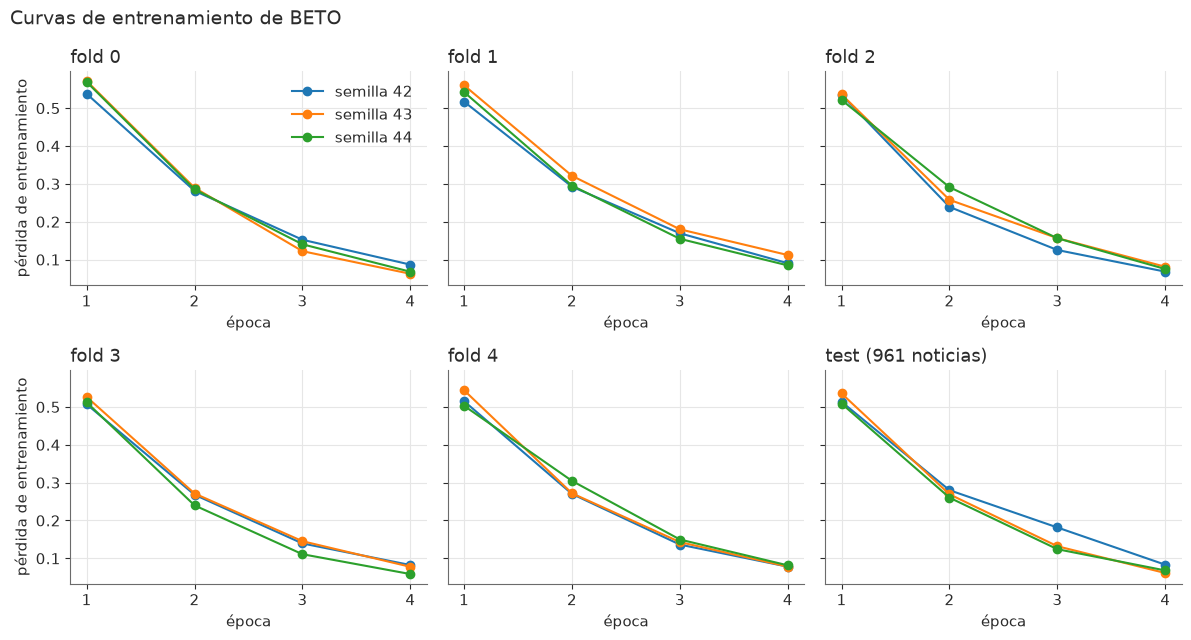

In [9]:
fig, ejes = plt.subplots(2, 3, figsize = (12, 6.5), sharey = True)
piezas = ['0', '1', '2', '3', '4', 'test']
for ax, pieza in zip(ejes.ravel(), piezas):
    for semilla in SEMILLAS_BETO:
        fila = beto_log[(beto_log['fold'] == pieza) & (beto_log['semilla'] == semilla)].iloc[0]
        perdidas = [fila['perdida_epoca_1'], fila['perdida_epoca_2'], fila['perdida_epoca_3'], fila['perdida_epoca_4']]
        ax.plot([1, 2, 3, 4], perdidas, marker = 'o', label = f'semilla {semilla}')
    ax.set_title(f'fold {pieza}' if pieza != 'test' else 'test (961 noticias)')
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xlabel('época')
ejes[0, 0].set_ylabel('pérdida de entrenamiento')
ejes[1, 0].set_ylabel('pérdida de entrenamiento')
ejes[0, 0].legend()
fig.suptitle('Curvas de entrenamiento de BETO', x = 0.01, ha = 'left', fontsize = 14)
fig.tight_layout()
guardar(fig, '2_1_beto_curvas_perdida')
plt.show()

**Tabla 2.2.** F1 de fake por fold: cada semilla, el promedio de las 3 (BETO) y la LR de texto.

In [10]:
filas = []
for k in range(5):
    en_k = folds == k
    fila = {'fold': k}
    valores_semilla = []
    for semilla in SEMILLAS_BETO:
        valor = uf.f1_fake(y[en_k], clases(beto_alineado[f'prob_s{semilla}'].values[en_k]))
        fila[f'semilla {semilla}'] = valor
        valores_semilla.append(valor)
    fila['BETO (promedio)'] = f1_por_fold['BETO'][k]
    fila['LR texto'] = f1_por_fold['LR texto'][k]
    fila['máx − mín entre semillas'] = max(valores_semilla) - min(valores_semilla)
    filas.append(fila)
beto_por_fold = pd.DataFrame(filas)
resumen = beto_por_fold.drop(columns = 'fold').agg(['mean', 'std'])
resumen.insert(0, 'fold', ['media', 'sd'])
pd.concat([beto_por_fold, resumen], ignore_index = True).round(4)

,fold,semilla 42,semilla 43,semilla 44,BETO (promedio),LR texto,máx − mín entre semillas
0,0,0.7679,0.6937,0.7234,0.7328,0.7848,0.0742
1,1,0.3025,0.1887,0.6483,0.3130,0.8541,0.4596
2,2,0.7550,0.7785,0.7376,0.7651,0.6345,0.0409
3,3,0.6667,0.6617,0.6765,0.6767,0.6375,0.0148
4,4,0.7429,0.7815,0.7922,0.7919,0.7381,0.0494
5,media,0.6470,0.6208,0.7156,0.6559,0.7298,0.1278
6,sd,0.1965,0.2472,0.0558,0.1964,0.0951,0.1867


**Tabla 2.3.** Verificaciones de BETO solo (sección 8 de la tarea: detenerse si alguna falla).

In [11]:
media_beto = float(np.mean(f1_por_fold['BETO']))
max_semillas = float(beto_por_fold['máx − mín entre semillas'].max())
verificaciones.append(fila_verificacion('BETO solo en CV: F1 de fake media ≥ 0.60', '≥ 0.60', f'{media_beto:.4f}', marca(media_beto >= 0.60)))
fold_peor = int(beto_por_fold.loc[beto_por_fold['máx − mín entre semillas'].idxmax(), 'fold'])
verificaciones.append(fila_verificacion('Diferencia entre semillas ≤ 0.10 de F1 en cada fold', '≤ 0.10', f'{max_semillas:.4f} (máximo, fold {fold_peor})',
                                        '✅' if max_semillas <= 0.10 else '⚠️ fold de El Ruinaversal (sátira); revisado y aceptado (26-nov), ver Tabla 2.5'))
pd.DataFrame(verificaciones[-2:])

,verificación,esperado,obtenido,estado
0,BETO solo en CV: F1 de fake media ≥ 0.60,≥ 0.60,0.6559,✅
1,Diferencia entre semillas ≤ 0.10 de F1 en cada...,≤ 0.10,"0.4596 (máximo, fold 1)",⚠️ fold de El Ruinaversal (sátira); revisado y...


**Tabla 2.4.** Diferencia pareada por fold: BETO − LR de texto (F1 de fake, umbral 0.5).

In [12]:
diferencia = np.array(f1_por_fold['BETO']) - np.array(f1_por_fold['LR texto'])
tabla = pd.DataFrame({'fold': range(5), 'BETO': f1_por_fold['BETO'], 'LR texto': f1_por_fold['LR texto'], 'BETO − LR': diferencia})
print(f'Diferencia media {diferencia.mean():+.4f} ± {diferencia.std(ddof = 1):.4f}; BETO gana en {int((diferencia > 0).sum())} de 5 folds')
tabla.round(4)

Diferencia media -0.0739 ± 0.2691; BETO gana en 3 de 5 folds


,fold,BETO,LR texto,BETO − LR
0,0,0.7328,0.7848,-0.0521
1,1,0.3130,0.8541,-0.5410
2,2,0.7651,0.6345,0.1306
3,3,0.6767,0.6375,0.0392
4,4,0.7919,0.7381,0.0539


**Tabla 2.5.** Diagnóstico del fold con más diferencia entre semillas: de qué fuentes vienen sus noticias y qué hace BETO con cada semilla. La fuente se usa **solo para diagnosticar**, nunca como entrada de un modelo.

In [13]:
fuentes = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'folds.csv'))
fuentes = fuentes[fuentes['particion'] != 'test'].set_index('id_unico').loc[corpus['id_unico'], 'fuente'].values
en_peor = folds == fold_peor
composicion = pd.DataFrame({'fuente': fuentes[en_peor], 'Fake': y[en_peor] == 'Fake'})
composicion = composicion.groupby('fuente')['Fake'].agg(['count', 'sum']).rename(columns = {'count': 'noticias', 'sum': 'falsas'})
composicion = composicion.sort_values('noticias', ascending = False)
print(f'Fold {fold_peor}: {int(en_peor.sum())} noticias de {len(composicion)} fuentes; fuentes con falsas: {composicion[composicion["falsas"] > 0].index.tolist()}')
display(composicion.head(6))

filas = []
y_peor = y[en_peor]
for semilla in SEMILLAS_BETO + ['promedio']:
    columna = 'prob_beto' if semilla == 'promedio' else f'prob_s{semilla}'
    prob = beto_alineado[columna].values[en_peor]
    pred = clases(prob)
    filas.append({'semilla': semilla, 'predichas Fake': int((pred == 'Fake').sum()),
                  'recall de fake': np.mean(pred[y_peor == 'Fake'] == 'Fake'),
                  'precisión de fake': np.mean(y_peor[pred == 'Fake'] == 'Fake'),
                  'prob. mediana en falsas': np.median(prob[y_peor == 'Fake']),
                  'prob. mediana en verdaderas': np.median(prob[y_peor == 'True']),
                  'F1 de fake': uf.f1_fake(y_peor, pred)})
pd.DataFrame(filas).round(3)

Fold 1: 190 noticias de 16 fuentes; fuentes con falsas: ['el ruinaversal']


,noticias,falsas
fuente,,
el ruinaversal,93,93
forbes,33,0
el financiero,22,0
aristegui noticias,14,0
cnnespañol,7,0
cnn español,5,0


,semilla,predichas Fake,recall de fake,precisión de fake,prob. mediana en falsas,prob. mediana en verdaderas,F1 de fake
0,42,26,0.194,0.692,0.040,0.006,0.303
1,43,13,0.108,0.769,0.020,0.006,0.189
2,44,52,0.505,0.904,0.500,0.007,0.648
3,promedio,22,0.194,0.818,0.225,0.007,0.313


**Figura 2.2.** Matrices de confusión en CV (las 961 predicciones *out-of-fold*): LR de texto y BETO. Cada celda muestra la proporción por fila (real) y el número de noticias.

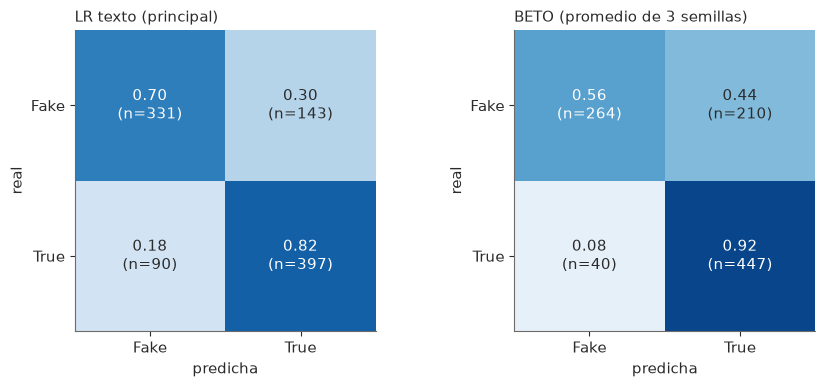

In [14]:
def dibujar_matriz(ax, y_real, y_pred, titulo):
    '''
    Función que dibuja una matriz de confusión con proporción por fila y conteos, como en evaluacion.ipynb

    inputs:
    --------
        ax (matplotlib.axes.Axes): Eje donde se dibuja
        y_real (array-like): Clases reales
        y_pred (array-like): Clases predichas
        titulo (str): Título del panel

    outputs:
    --------
        None
    '''
    etiquetas = ['Fake', 'True']
    cm = confusion_matrix(y_real, y_pred, labels = etiquetas)
    cm_norm = cm / cm.sum(axis = 1, keepdims = True)
    ax.imshow(cm_norm, cmap = 'Blues', vmin = 0, vmax = 1)
    for i in range(2):
        for j in range(2):
            color = 'white' if cm_norm[i, j] > 0.5 else TINTA
            ax.text(j, i, f'{cm_norm[i, j]:.2f}\n(n={cm[i, j]})', ha = 'center', va = 'center', color = color, fontsize = 11)
    ax.set_xticks([0, 1], etiquetas)
    ax.set_yticks([0, 1], etiquetas)
    ax.set_xlabel('predicha')
    ax.set_ylabel('real')
    ax.set_title(titulo, fontsize = 11)
    ax.grid(False)

def cuadricula_matrices(y_real, predicciones, titulo, nombre, columnas = 4):
    '''
    Función que dibuja y guarda una cuadrícula con la matriz de confusión de cada sistema

    inputs:
    --------
        y_real (array-like): Clases reales
        predicciones (dict): Nombre del sistema -> clases predichas
        titulo (str): Título de la figura
        nombre (str): Nombre del archivo de la figura
        columnas (int): Paneles por renglón

    outputs:
    --------
        None
    '''
    renglones = int(np.ceil(len(predicciones) / columnas))
    fig, ejes = plt.subplots(renglones, columnas, figsize = (3.6 * columnas, 3.5 * renglones))
    ejes = np.atleast_1d(ejes).ravel()
    for ax, (sistema, pred) in zip(ejes, predicciones.items()):
        dibujar_matriz(ax, y_real, pred, sistema)
    for ax in ejes[len(predicciones):]:
        ax.axis('off')
    fig.suptitle(titulo, x = 0.01, ha = 'left', fontsize = 14)
    fig.tight_layout()
    guardar(fig, nombre)
    plt.show()

fig, ejes = plt.subplots(1, 2, figsize = (9, 4))
dibujar_matriz(ejes[0], y, clases(Z['LR texto']), 'LR texto (principal)')
dibujar_matriz(ejes[1], y, clases(Z['BETO']), 'BETO (promedio de 3 semillas)')
fig.tight_layout()
guardar(fig, '2_2_beto_matriz_cv')
plt.show()

**Qué se observa.**

* **El entrenamiento fue normal.** En los 18 ajustes la pérdida baja de entre 0.503 y 0.572 en la primera época a entre 0.058 y 0.112 en la cuarta (Figura 2.1). En total fueron 75 min con un máximo de 2.09 GB de GPU.
* **BETO solo queda por debajo de la LR en CV:** 0.6559 ± 0.1964 contra 0.7298 ± 0.0951. Le gana en 3 de 5 folds (folds 2, 3 y 4: +0.1306, +0.0392 y +0.0539) y pierde en los folds 0 y 1 (−0.0521 y −0.5410).
* **El fold 1 es el de la sátira** (Tabla 2.5). Sus 93 falsas vienen todas de *El Ruinaversal*; las verdaderas, de otras 15 fuentes. BETO nunca ve sátira al entrenar en ese fold y la lee como verdadera: con las semillas 42 y 43 detecta el 19.4 % y el 10.8 % de las falsas, y con la 44 el 50.5 %, porque deja la probabilidad mediana justo en 0.500. Cuando marca una falsa, casi siempre acierta (precisión de 0.692 a 0.904). Por eso la diferencia entre semillas llega a 0.4596 en ese fold, contra 0.0742 o menos en los demás. Se revisó con Miguel el 26 de noviembre y se decidió seguir con la configuración fija.
* **BETO es más cauteloso que la LR** (Figura 2.2): en CV marca menos falsas, con más precisión (0.8624 contra 0.7757) y menos exhaustividad (0.5566 contra 0.6952).

**BETO no le gana a la LR por sí solo, pero falla en otros folds: es mejor en tres y mucho peor en el de la sátira. Ese patrón es justo el que un ensamble puede aprovechar.**

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Diversidad: ¿BETO se equivoca en otras noticias?</span></div>

> **Qué se hace:** medimos qué tan parecidas son las probabilidades de las 4 bases, en cuántas noticias acierta o falla cada una sola y, sobre todo, cuántas falsas detecta cada base según la longitud de la noticia.
>
> **Qué se espera ver:** que BETO se parezca a la LR menos de lo que XGBoost se parece a ella (Spearman 0.80 en el ensamble anterior), y que detecte más falsas largas que la LR. Esa es la condición de la lámina 4 que falló la vez pasada.

#### Glosario de la sección
* **Correlación de Spearman:** qué tan parecido es el orden en que dos modelos acomodan las noticias de "más falsa" a "menos falsa". 1 es el mismo orden; 0, ninguna relación.
* **Oráculo:** un selector imaginario que, para cada noticia, elige la base que acierta. Es la cota máxima de cualquier combinación; no es alcanzable.
* **Cuartil de longitud:** partimos las noticias en 4 grupos del mismo tamaño según `est_log_palabras` (logaritmo del número de palabras). Q1 son las más cortas y Q4 las más largas.

**Tabla 3.1.** Correlación de Spearman entre las probabilidades *out-of-fold* de las 4 bases.

In [15]:
Z[BASES].corr(method = 'spearman').round(3)

,LR texto,XGBoost,RF estilo,BETO
LR texto,1.000,0.801,0.678,0.674
XGBoost,0.801,1.000,0.692,0.609
RF estilo,0.678,0.692,1.000,0.550
BETO,0.674,0.609,0.550,1.000


**Tabla 3.2.** Aciertos y errores de las bases (umbral 0.5) sobre las 961 noticias.

In [16]:
aciertos = pd.DataFrame(index = corpus.index)
for nombre in BASES:
    aciertos[nombre] = clases(Z[nombre]) == y
n_aciertos = aciertos.sum(axis = 1)
filas = [('aciertan las 4 bases', int((n_aciertos == 4).sum()))]
for nombre in BASES:
    otros = [m for m in BASES if m != nombre]
    filas.append((f'solo acierta {nombre}', int((aciertos[nombre] & ~aciertos[otros].any(axis = 1)).sum())))
    filas.append((f'solo falla {nombre}', int((~aciertos[nombre] & aciertos[otros].all(axis = 1)).sum())))
filas.append(('fallan las 4 bases', int((n_aciertos == 0).sum())))
filas.append(('exactitud del oráculo de las 4 bases', round(float((n_aciertos > 0).mean()), 3)))
filas.append(('exactitud del oráculo sin BETO (3 bases)', round(float(aciertos[BASES_CLASICAS].any(axis = 1).mean()), 3)))
filas.append(('exactitud del oráculo LR + BETO', round(float((aciertos['LR texto'] | aciertos['BETO']).mean()), 3)))
filas.append(('exactitud de la mejor base sola', round(float(aciertos.mean().max()), 3)))
pd.DataFrame(filas, columns = ['caso', 'noticias'])

,caso,noticias
0,aciertan las 4 bases,452.000
1,solo acierta LR texto,32.000
2,solo falla LR texto,24.000
3,solo acierta XGBoost,13.000
4,solo falla XGBoost,42.000
5,solo acierta RF estilo,19.000
6,solo falla RF estilo,74.000
7,solo acierta BETO,47.000
8,solo falla BETO,47.000
9,fallan las 4 bases,76.000


**Tabla 3.3.** Cruce de aciertos entre la LR y BETO (número de noticias).

In [17]:
pd.crosstab(np.where(aciertos['LR texto'], 'LR acierta', 'LR falla'), np.where(aciertos['BETO'], 'BETO acierta', 'BETO falla'))

col_0,BETO acierta,BETO falla
row_0,,
LR acierta,602,126
LR falla,109,124


**Tabla 3.4.** Falsas detectadas y verdaderas acertadas (%) por cuartil de longitud, en CV, para cada base.

In [18]:
def deteccion_por_cuartil(y_real, predicciones, cuartil):
    '''
    Función que calcula el porcentaje de falsas detectadas y de verdaderas acertadas por cuartil de longitud

    inputs:
    --------
        y_real (numpy.ndarray): Clases reales
        predicciones (dict): Nombre del sistema -> clases predichas
        cuartil (pandas.Series): Cuartil de longitud de cada noticia (categórica)

    outputs:
    --------
        pandas.DataFrame: Un bloque de falsas detectadas y otro de verdaderas acertadas; una columna por sistema
    '''
    falsas = {}
    verdaderas = {}
    for nombre, pred in predicciones.items():
        columna_falsas = []
        columna_verdaderas = []
        for q in cuartil.cat.categories:
            en_q = (cuartil == q).values
            columna_falsas.append(100 * np.mean(pred[en_q & (y_real == 'Fake')] == 'Fake'))
            columna_verdaderas.append(100 * np.mean(pred[en_q & (y_real == 'True')] == 'True'))
        falsas[nombre] = columna_falsas
        verdaderas[nombre] = columna_verdaderas
    tabla_falsas = pd.DataFrame(falsas, index = cuartil.cat.categories)
    tabla_verdaderas = pd.DataFrame(verdaderas, index = cuartil.cat.categories)
    return pd.concat({'falsas detectadas (%)': tabla_falsas, 'verdaderas acertadas (%)': tabla_verdaderas}).round(1)

cuartil_cv = pd.qcut(corpus['est_log_palabras'], 4, labels = CUARTILES)
n_falsas = []
for q in CUARTILES:
    n_falsas.append(int(((cuartil_cv == q).values & (y == 'Fake')).sum()))
print('Falsas por cuartil:', dict(zip(CUARTILES, n_falsas)))
pred_bases_cv = {}
for nombre in BASES:
    pred_bases_cv[nombre] = clases(Z[nombre])
deteccion_por_cuartil(y, pred_bases_cv, cuartil_cv)

Falsas por cuartil: {'Q1 (más cortas)': 153, 'Q2': 147, 'Q3': 112, 'Q4 (más largas)': 62}


LR texto  XGBoost  RF estilo  BETO
falsas detectadas (%)    Q1 (más cortas)      75.8     81.7       76.5  81.0
                         Q2                   69.4     70.7       70.7  63.3
                         Q3                   74.1     60.7       43.8  33.0
                         Q4 (más largas)      48.4     32.3        9.7  16.1
verdaderas acertadas (%) Q1 (más cortas)      66.7     51.1       52.2  81.1
                         Q2                   69.9     53.8       58.1  90.3
                         Q3                   85.8     81.1       71.7  94.5
                         Q4 (más largas)      92.1     92.7       92.1  96.0

**Qué se observa.**

* **BETO se parece a la LR mucho menos que XGBoost.** Spearman BETO–LR = 0.674, contra 0.801 de XGBoost–LR. BETO es la base más distinta de todas (0.609 con XGBoost y 0.550 con el bosque).
* **El oráculo sube** de 0.872 con las 3 bases clásicas a 0.921 con BETO. BETO es la base que más noticias acierta sola (47), y ahora solo 76 noticias las fallan las 4 bases.
* **LR y BETO se reparten los errores** (Tabla 3.3): en 109 noticias falla la LR y acierta BETO, y en 126 pasa lo contrario. El oráculo de LR + BETO (0.871) ya iguala al de las 3 bases viejas juntas.
* **Pero en CV BETO no rescata las falsas largas.** Detecta el 81.0 % de las cortas (Q1), más que la LR, y solo el 33.0 % del Q3 y el 16.1 % del Q4, contra 74.1 % y 48.4 % de la LR. A cambio, acierta casi todas las verdaderas largas (94.5 % y 96.0 %).

**Ahora sí se cumple la condición de la lámina 4: BETO se equivoca en noticias distintas que la LR. La esperanza de que rescatara las falsas largas no se cumple en CV.**

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Meta-modelos de regresión logística (sistemas 3, 4 y 6)</span></div>

> **Qué se hace:** para cada sistema con meta-modelo LR elegimos `C` por *grid search* con los 5 folds y lo entrenamos con las 961 predicciones *out-of-fold* (es el que se aplicará al test). Después repetimos todo con el **esquema B** para estimar su desempeño honestamente. Incluimos el stacking viejo (LR + XGBoost + RF) con el mismo procedimiento.
>
> **Qué se espera ver:** pesos positivos para la LR y BETO; si BETO complementa a la LR, su peso debe ser comparable al de la LR, no casi cero como el del bosque en el ensamble anterior.

#### Glosario de la sección
* **Meta-modelo (nivel 2):** modelo cuya entrada son las probabilidades de las bases y cuya salida es la decisión final (lámina 21).
* **`C`:** inverso de la regularización. Con `C` chico, los pesos se encogen hacia cero; con `C` grande, el meta-modelo confía más en los datos. **Regla:** la mayor F1 de fake media; en empate, la `C` más chica.
* **Esquema B:** para cada fold externo k, el meta-modelo (incluido su *grid search*) se entrena **solo con las filas *out-of-fold* de los otros 4 folds** y se aplica a las del fold k. **Fuga residual que hay que tener presente:** las probabilidades de los otros 4 folds vienen de bases que sí vieron el fold k al entrenar. La CV anidada completa evitaría eso, pero costaría 75 entrenamientos más de BETO.
* **`StandardScaler` en el sistema 6:** la longitud no está en escala 0–1 como las probabilidades, así que antes de la LR se estandarizan todas las entradas (media 0, sd 1). Por eso los pesos del sistema 6 están en otra escala y no se comparan directamente con los de los sistemas 3 y 4.

In [19]:
SISTEMAS_META = {
    '3. Stacking LR (LR + BETO)': {'entradas': ['LR texto', 'BETO'], 'meta': 'LR', 'escalar': False},
    '4. Stacking LR (4 bases)': {'entradas': BASES, 'meta': 'LR', 'escalar': False},
    '5. Stacking MLP (4 bases)': {'entradas': BASES, 'meta': 'MLP', 'escalar': True},
    '6. Stacking LR (4 bases + longitud)': {'entradas': BASES + ['est_log_palabras'], 'meta': 'LR', 'escalar': True},
    '7. Stacking MLP (4 bases + longitud)': {'entradas': BASES + ['est_log_palabras'], 'meta': 'MLP', 'escalar': True},
    'Stacking viejo (LR + XGBoost + RF)': {'entradas': BASES_CLASICAS, 'meta': 'LR', 'escalar': False},
}
SISTEMAS_LR = ['3. Stacking LR (LR + BETO)', '4. Stacking LR (4 bases)', '6. Stacking LR (4 bases + longitud)', 'Stacking viejo (LR + XGBoost + RF)']
SISTEMAS_MLP = ['5. Stacking MLP (4 bases)', '7. Stacking MLP (4 bases + longitud)']

def construir_meta_lr(c, escalar):
    '''
    Función que construye el meta-modelo de regresión logística (con o sin estandarizar)

    inputs:
    --------
        c (float): Inverso de la regularización
        escalar (bool): Si se pone un StandardScaler antes de la LR

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar; el paso final se llama 'meta'
    '''
    lr = LogisticRegression(C = c, class_weight = 'balanced', max_iter = 5000)
    if escalar:
        return Pipeline([('escala', StandardScaler()), ('meta', lr)])
    return Pipeline([('meta', lr)])

def ajustar_meta_lr(X, y_numerica, folds_entrenamiento, escalar):
    '''
    Función que elige C por grid search con los folds dados y entrena el meta-modelo LR (lógica de ajustar_meta)

    inputs:
    --------
        X (numpy.ndarray): Entradas del meta-modelo (probabilidades out-of-fold y, en su caso, longitud)
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila
        escalar (bool): Si se estandarizan las entradas

    outputs:
    --------
        tuple: (meta-modelo entrenado, C elegida, tabla del grid search con la F1 de cada fold)
    '''
    busqueda = GridSearchCV(construir_meta_lr(1.0, escalar), {'meta__C': REJILLA_META}, scoring = 'f1',
                            cv = PredefinedSplit(test_fold = folds_entrenamiento), refit = False)
    busqueda.fit(X, y_numerica)
    r = busqueda.cv_results_
    folds_unicos = np.unique(folds_entrenamiento)
    filas = []
    for i, parametros in enumerate(r['params']):
        fila = {'C': parametros['meta__C']}
        for j in range(len(folds_unicos)):
            fila[f'fold {folds_unicos[j]}'] = r[f'split{j}_test_score'][i]
        fila['F1_fake_media'] = r['mean_test_score'][i]
        filas.append(fila)
    tabla = pd.DataFrame(filas)
    mejores = tabla[np.isclose(tabla['F1_fake_media'], tabla['F1_fake_media'].max())]
    c_elegida = float(mejores['C'].min())
    meta = construir_meta_lr(c_elegida, escalar).fit(X, y_numerica)
    return meta, c_elegida, tabla

def esquema_b_lr(entradas, escalar):
    '''
    Función que estima un stacking con meta-modelo LR con el esquema B (grid search y ajuste sin el fold externo)

    inputs:
    --------
        entradas (list): Columnas de M que recibe el meta-modelo
        escalar (bool): Si se estandarizan las entradas

    outputs:
    --------
        tuple: (probabilidad de fake de las 961 noticias, tabla de C y pesos por fold externo, grids de cada fold externo)
    '''
    prob = np.zeros(len(M))
    filas = []
    grids_b = []
    for k in range(5):
        afuera = folds == k
        meta_k, c_k, tabla_k = ajustar_meta_lr(M.loc[~afuera, entradas].values, y_num[~afuera], folds[~afuera], escalar)
        prob[afuera] = meta_k.predict_proba(M.loc[afuera, entradas].values)[:, 1]
        fila = {'fold externo': k, 'C elegida': c_k}
        for nombre, peso in zip(entradas, meta_k['meta'].coef_[0]):
            fila[f'peso {nombre}'] = peso
        fila['intercepto'] = meta_k['meta'].intercept_[0]
        filas.append(fila)
        tabla_k.insert(0, 'ajuste', f'esquema B, fold externo {k}')
        grids_b.append(tabla_k)
    return prob, pd.DataFrame(filas), pd.concat(grids_b, ignore_index = True)

metas_finales = {}
eleccion_meta = {}
prob_cv = {}
estabilidad_lr = {}
grids = []
for nombre in SISTEMAS_LR:
    entradas = SISTEMAS_META[nombre]['entradas']
    escalar = SISTEMAS_META[nombre]['escalar']
    meta, c_elegida, tabla = ajustar_meta_lr(M[entradas].values, y_num, folds, escalar)
    metas_finales[nombre] = meta
    eleccion_meta[nombre] = {'C': c_elegida}
    tabla.insert(0, 'ajuste', 'todo el out-of-fold (se aplica al test)')
    prob, por_fold, grids_b = esquema_b_lr(entradas, escalar)
    prob_cv[nombre] = prob
    estabilidad_lr[nombre] = por_fold
    juntas = pd.concat([tabla, grids_b], ignore_index = True)
    juntas.insert(0, 'sistema', nombre)
    grids.append(juntas)
print('C elegida con todo el out-of-fold:', eleccion_meta)

C elegida con todo el out-of-fold: {'3. Stacking LR (LR + BETO)': {'C': 10.0}, '4. Stacking LR (4 bases)': {'C': 0.1}, '6. Stacking LR (4 bases + longitud)': {'C': 0.01}, 'Stacking viejo (LR + XGBoost + RF)': {'C': 1.0}}


**Tabla 4.1.** *Grid search* de `C` con las 961 predicciones *out-of-fold* (F1 de fake media en los 5 folds). El elegido de cada sistema es el que se aplica al test.

In [20]:
tabla = pd.DataFrame({'C': REJILLA_META})
for nombre in SISTEMAS_LR:
    grid = grids[SISTEMAS_LR.index(nombre)]
    grid = grid[grid['ajuste'] == 'todo el out-of-fold (se aplica al test)']
    tabla[nombre] = grid['F1_fake_media'].values
tabla.round(4)

,C,3. Stacking LR (LR + BETO),4. Stacking LR (4 bases),6. Stacking LR (4 bases + longitud),Stacking viejo (LR + XGBoost + RF)
0,0.01,0.7154,0.7310,0.7179,0.7205
1,0.10,0.7325,0.7406,0.7083,0.7281
2,1.00,0.7445,0.7378,0.7115,0.7349
3,10.00,0.7497,0.7345,0.7106,0.7300
4,100.00,0.7457,0.7330,0.7106,0.7301


**Tabla 4.2.** Pesos de cada meta-modelo LR entrenado con las 961 predicciones *out-of-fold*. En los sistemas 3, 4 y el viejo, las entradas son probabilidades de 0 a 1 y los pesos se comparan entre sí; en el 6 están estandarizadas.

In [21]:
filas = []
for nombre in SISTEMAS_LR:
    meta = metas_finales[nombre]['meta']
    fila = {'sistema': nombre, 'C': eleccion_meta[nombre]['C']}
    for entrada, peso in zip(SISTEMAS_META[nombre]['entradas'], meta.coef_[0]):
        fila[entrada] = peso
    fila['intercepto'] = meta.intercept_[0]
    filas.append(fila)
pesos_lr = pd.DataFrame(filas).set_index('sistema')
pesos_lr.round(3)

,C,LR texto,BETO,intercepto,XGBoost,RF estilo,est_log_palabras
sistema,,,,,,,
3. Stacking LR (LR + BETO),10.00,5.128,2.581,-3.058,NaN,NaN,NaN
4. Stacking LR (4 bases),0.10,1.289,1.945,-1.835,1.214,0.241,NaN
6. Stacking LR (4 bases + longitud),0.01,0.473,0.572,0.035,0.303,0.024,-0.107
Stacking viejo (LR + XGBoost + RF),1.00,4.538,NaN,-3.075,2.103,0.075,NaN


**Tabla 4.3.** Estabilidad entre folds: `C` elegida y pesos del meta-modelo LR en cada fold externo del esquema B.

In [22]:
pd.concat(estabilidad_lr, names = ['sistema', 'renglón']).droplevel('renglón').round(3)

,fold externo,C elegida,peso LR texto,peso BETO,intercepto,peso XGBoost,peso RF estilo,peso est_log_palabras
sistema,,,,,,,,
3. Stacking LR (LR + BETO),0,10.00,4.469,2.649,-2.738,NaN,NaN,NaN
3. Stacking LR (LR + BETO),1,10.00,3.139,2.988,-2.368,NaN,NaN,NaN
3. Stacking LR (LR + BETO),2,100.00,5.942,2.415,-3.410,NaN,NaN,NaN
3. Stacking LR (LR + BETO),3,100.00,6.674,2.494,-3.739,NaN,NaN,NaN
3. Stacking LR (LR + BETO),4,100.00,5.932,2.402,-3.319,NaN,NaN,NaN
4. Stacking LR (4 bases),0,0.01,0.273,0.579,-0.515,0.316,0.137,NaN
4. Stacking LR (4 bases),1,10.00,1.305,2.922,-2.284,1.851,-0.195,NaN
4. Stacking LR (4 bases),2,10.00,5.672,2.589,-2.655,1.221,-2.652,NaN
4. Stacking LR (4 bases),3,0.10,1.324,1.815,-1.914,1.337,0.345,NaN


**Qué se observa.**

* **`C` elegida:** 10 para el sistema 3, 0.1 para el 4, 0.01 para el 6 y 1 para el stacking viejo. El *grid* del sistema 3 va de 0.7154 a 0.7497; los demás son más planos.
* **En el sistema 3, BETO recibe un peso real:** LR 5.128 y BETO 2.581, los dos positivos. En el ensamble anterior, el bosque recibía un peso negativo. Con las 4 bases (sistema 4, `C` = 0.1), el peso más grande es el de BETO (1.945), seguido de la LR (1.289) y XGBoost (1.214); el bosque queda casi en cero (0.241).
* **El sistema 3 es estable entre folds** (Tabla 4.3): `C` de 10 a 100, peso de la LR de 3.139 a 6.674 y de BETO de 2.402 a 2.988, siempre positivos. **Con más entradas vuelve la inestabilidad:** en el sistema 4, `C` va de 0.01 a 10 y el peso del bosque cambia de signo (−2.652 a 0.345). En el 6, el de la longitud también cambia de signo (−0.428 a 0.138).

**Con dos entradas, el meta-modelo aprende pesos claros y estables para la LR y BETO; agregar bases débiles o la longitud solo mete ruido en los pesos.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Meta-modelos de red neuronal (sistemas 5 y 7)</span></div>

> **Qué se hace:** cambiamos la LR del nivel 2 por un perceptrón multicapa (MLP). Elegimos su arquitectura y regularización por *grid search* (20 combinaciones) con los mismos folds, promediando 5 inicializaciones, y repetimos todo con el esquema B.
>
> **Qué se espera ver:** con 4 o 5 entradas y 961 noticias, una red rara vez le gana a una LR como meta-modelo. Si el sistema 7 gana al 6, la red estaría aprovechando la longitud de forma no lineal.

#### Glosario de la sección
* **MLP (perceptrón multicapa):** red neuronal con capas ocultas. Cada neurona calcula una suma ponderada de sus entradas y le aplica ReLU (`max(0, x)`); por eso puede aprender relaciones no lineales, como "si la noticia es larga, confía más en BETO".
* **`hidden_layer_sizes`:** neuronas por capa oculta. `(8, 4)` son dos capas, de 8 y 4 neuronas.
* **`alpha`:** regularización L2. Con `alpha` grande, los pesos se encogen y la red se parece más a una función suave.
* **`lbfgs`:** optimizador que usa todas las filas a la vez. Con ≈ 770 filas converge sin *early stopping*. No usamos el *early stopping* de `MLPClassifier`, porque aparta una validación **aleatoria** y rompería la regla 1.
* **Regla de un error estándar (SE):** entre las combinaciones cuya media está a menos de un SE de la mejor, la más simple (menos neuronas y luego `alpha` más grande). SE = sd entre folds / √(número de folds).
* **Promedio de semillas:** la red depende de su inicialización aleatoria. Cada configuración se entrena con 5 semillas (`random_state` 0 a 4) y se promedian sus probabilidades.

**Clases.** `MLPClassifier` no tiene `class_weight`. No hace falta balancear: el corpus tiene 474 falsas y 487 verdaderas (49 % y 51 %).

In [23]:
CAPAS_POR_NOMBRE = {}
for capas in REJILLA_MLP_CAPAS:
    CAPAS_POR_NOMBRE[str(capas)] = capas

def etiquetas_texto(y_numerica):
    '''
    Función que convierte la y numérica en clases de texto

    inputs:
    --------
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True

    outputs:
    --------
        numpy.ndarray: 'Fake' / 'True'
    '''
    return np.where(y_numerica == 1, 'Fake', 'True')

def construir_mlp(capas, alpha, semilla):
    '''
    Función que construye el meta-modelo MLP con estandarización previa

    inputs:
    --------
        capas (tuple): Neuronas de cada capa oculta
        alpha (float): Regularización L2
        semilla (int): Semilla de la inicialización

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar
    '''
    red = MLPClassifier(hidden_layer_sizes = capas, alpha = alpha, solver = 'lbfgs', activation = 'relu',
                        max_iter = 2000, random_state = semilla)
    return Pipeline([('escala', StandardScaler()), ('meta', red)])

def entrenar_mlp_semillas(capas, alpha, X, y_numerica):
    '''
    Función que entrena la misma MLP con las 5 semillas

    inputs:
    --------
        capas (tuple): Neuronas de cada capa oculta
        alpha (float): Regularización L2
        X (numpy.ndarray): Entradas de entrenamiento
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True

    outputs:
    --------
        list: Un modelo entrenado por semilla
    '''
    modelos = []
    for semilla in SEMILLAS_MLP:
        modelos.append(construir_mlp(capas, alpha, semilla).fit(X, y_numerica))
    return modelos

def predecir_semillas(modelos, X):
    '''
    Función que calcula la probabilidad de fake de cada modelo de una lista

    inputs:
    --------
        modelos (list): Modelos entrenados (uno por semilla)
        X (numpy.ndarray): Entradas a predecir

    outputs:
    --------
        numpy.ndarray: Matriz (número de semillas × filas); el promedio por columna es la predicción final
    '''
    probs = []
    for modelo in modelos:
        probs.append(modelo.predict_proba(X)[:, 1])
    return np.array(probs)

def grid_mlp(X, y_numerica, folds_entrenamiento):
    '''
    Función que evalúa las 20 combinaciones de la MLP con los folds dados (promediando 5 semillas en cada una)

    inputs:
    --------
        X (numpy.ndarray): Entradas del meta-modelo
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila

    outputs:
    --------
        pandas.DataFrame: Una fila por combinación con la F1 de fake de cada fold, media, sd y SE
    '''
    folds_unicos = np.unique(folds_entrenamiento)
    filas = []
    for capas in REJILLA_MLP_CAPAS:
        for alpha in REJILLA_MLP_ALPHA:
            fila = {'capas': str(capas), 'neuronas': sum(capas), 'alpha': alpha}
            valores = []
            for k in folds_unicos:
                en_k = folds_entrenamiento == k
                modelos = entrenar_mlp_semillas(capas, alpha, X[~en_k], y_numerica[~en_k])
                prob = predecir_semillas(modelos, X[en_k]).mean(axis = 0)
                valor = uf.f1_fake(etiquetas_texto(y_numerica[en_k]), clases(prob))
                fila[f'fold {k}'] = valor
                valores.append(valor)
            fila['F1_fake_media'] = np.mean(valores)
            fila['F1_fake_sd'] = np.std(valores, ddof = 1)
            fila['F1_fake_se'] = fila['F1_fake_sd'] / np.sqrt(len(valores))
            filas.append(fila)
    return pd.DataFrame(filas)

def regla_un_se_mlp(grid):
    '''
    Función que aplica la regla de un error estándar con preferencia por la red más simple

    inputs:
    --------
        grid (pandas.DataFrame): Salida de grid_mlp

    outputs:
    --------
        pandas.Series: Fila de la combinación elegida
    '''
    mejor = grid.loc[grid['F1_fake_media'].idxmax()]
    candidatas = grid[grid['F1_fake_media'] >= mejor['F1_fake_media'] - mejor['F1_fake_se']]
    candidatas = candidatas.sort_values(['neuronas', 'alpha'], ascending = [True, False])
    return candidatas.iloc[0]

def ajustar_meta_mlp(X, y_numerica, folds_entrenamiento):
    '''
    Función que elige la MLP por grid search y regla de un SE, y la entrena con las 5 semillas

    inputs:
    --------
        X (numpy.ndarray): Entradas del meta-modelo
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila

    outputs:
    --------
        tuple: (lista de modelos entrenados, capas elegidas, alpha elegida, tabla del grid)
    '''
    grid = grid_mlp(X, y_numerica, folds_entrenamiento)
    elegida = regla_un_se_mlp(grid)
    capas = CAPAS_POR_NOMBRE[elegida['capas']]
    alpha = float(elegida['alpha'])
    modelos = entrenar_mlp_semillas(capas, alpha, X, y_numerica)
    return modelos, capas, alpha, grid

def esquema_b_mlp(entradas):
    '''
    Función que estima un stacking con meta-modelo MLP con el esquema B

    inputs:
    --------
        entradas (list): Columnas de M que recibe el meta-modelo

    outputs:
    --------
        tuple: (probabilidad de fake de las 961 noticias, tabla por fold externo con la elección y la variación entre semillas, grids)
    '''
    prob = np.zeros(len(M))
    filas = []
    grids_b = []
    for k in range(5):
        afuera = folds == k
        modelos, capas, alpha, grid_k = ajustar_meta_mlp(M.loc[~afuera, entradas].values, y_num[~afuera], folds[~afuera])
        probs_semilla = predecir_semillas(modelos, M.loc[afuera, entradas].values)
        prob[afuera] = probs_semilla.mean(axis = 0)
        fila = {'fold externo': k, 'capas': str(capas), 'alpha': alpha,
                'F1 promedio de semillas': uf.f1_fake(y[afuera], clases(prob[afuera]))}
        valores = []
        for i, semilla in enumerate(SEMILLAS_MLP):
            valor = uf.f1_fake(y[afuera], clases(probs_semilla[i]))
            fila[f'semilla {semilla}'] = valor
            valores.append(valor)
        fila['sd entre semillas'] = np.std(valores, ddof = 1)
        fila['sd media de la probabilidad'] = probs_semilla.std(axis = 0, ddof = 1).mean()
        filas.append(fila)
        grid_k.insert(0, 'ajuste', f'esquema B, fold externo {k}')
        grids_b.append(grid_k)
    return prob, pd.DataFrame(filas), pd.concat(grids_b, ignore_index = True)

inicio = time.time()
grids_mlp = {}
estabilidad_mlp = {}
with warnings.catch_warnings(record = True) as avisos:
    warnings.simplefilter('always', category = ConvergenceWarning)
    for nombre in SISTEMAS_MLP:
        entradas = SISTEMAS_META[nombre]['entradas']
        modelos, capas, alpha, grid = ajustar_meta_mlp(M[entradas].values, y_num, folds)
        metas_finales[nombre] = modelos
        eleccion_meta[nombre] = {'capas': list(capas), 'alpha': alpha}
        grids_mlp[nombre] = grid
        prob, por_fold, grids_b = esquema_b_mlp(entradas)
        prob_cv[nombre] = prob
        estabilidad_mlp[nombre] = por_fold
        grid_todo = grid.copy()
        grid_todo.insert(0, 'ajuste', 'todo el out-of-fold (se aplica al test)')
        juntas = pd.concat([grid_todo, grids_b], ignore_index = True)
        juntas.insert(0, 'sistema', nombre)
        grids.append(juntas)
n_redes = 2 * (20 * 5 * 5 + 5 + 5 * (20 * 4 * 5 + 5))
print(f'MLP listas en {(time.time() - inicio) / 60:.1f} min; redes entrenadas: {n_redes}; avisos de no convergencia: {len(avisos)}')
print('Elegidas con todo el out-of-fold:', {n: eleccion_meta[n] for n in SISTEMAS_MLP})
grid_meta = pd.concat(grids, ignore_index = True)
guardar_csv(grid_meta, 'beto_meta_grid')

MLP listas en 11.5 min; redes entrenadas: 5060; avisos de no convergencia: 52
Elegidas con todo el out-of-fold: {'5. Stacking MLP (4 bases)': {'capas': [4], 'alpha': 1.0}, '7. Stacking MLP (4 bases + longitud)': {'capas': [4], 'alpha': 1.0}}


'resultados/beto_meta_grid.csv'

**Tabla 5.1.** *Grid search* completo de la MLP con las 961 predicciones *out-of-fold* (F1 de fake de cada fold, media, sd y SE). La fila elegida por la regla de un SE va marcada.

In [24]:
bloques = []
for nombre in SISTEMAS_MLP:
    grid = grids_mlp[nombre].copy()
    elegida = regla_un_se_mlp(grid)
    grid['elegida'] = ''
    grid.loc[elegida.name, 'elegida'] = '←'
    grid.insert(0, 'sistema', nombre)
    mejor = grid.loc[grid['F1_fake_media'].idxmax()]
    print(f'{nombre}: mejor media {mejor["F1_fake_media"]:.4f} ({mejor["capas"]}, alpha {mejor["alpha"]}); '
          f'umbral de la regla {mejor["F1_fake_media"] - mejor["F1_fake_se"]:.4f}; elegida {elegida["capas"]}, alpha {elegida["alpha"]} ({elegida["F1_fake_media"]:.4f})')
    bloques.append(grid)
pd.concat(bloques, ignore_index = True).round(4)

5. Stacking MLP (4 bases): mejor media 0.7380 ((4,), alpha 0.001); umbral de la regla 0.7073; elegida (4,), alpha 1.0 (0.7343)
7. Stacking MLP (4 bases + longitud): mejor media 0.7315 ((8, 4), alpha 0.01); umbral de la regla 0.7140; elegida (4,), alpha 1.0 (0.7256)


,sistema,capas,neuronas,alpha,fold 0,fold 1,fold 2,fold 3,fold 4,F1_fake_media,F1_fake_sd,F1_fake_se,elegida
0,5. Stacking MLP (4 bases),"(4,)",4,0.0001,0.8358,0.6667,0.7205,0.6923,0.7719,0.7374,0.0675,0.0302,
1,5. Stacking MLP (4 bases),"(4,)",4,0.0010,0.8315,0.6579,0.7407,0.6879,0.7719,0.7380,0.0686,0.0307,
2,5. Stacking MLP (4 bases),"(4,)",4,0.0100,0.8302,0.6400,0.7205,0.6968,0.7719,0.7319,0.0726,0.0325,
3,5. Stacking MLP (4 bases),"(4,)",4,0.1000,0.8302,0.6667,0.7205,0.6835,0.7647,0.7331,0.0661,0.0295,
4,5. Stacking MLP (4 bases),"(4,)",4,1.0000,0.8397,0.6259,0.7375,0.6968,0.7719,0.7343,0.0802,0.0358,←
5,5. Stacking MLP (4 bases),"(8,)",8,0.0001,0.8209,0.6000,0.7329,0.7051,0.7657,0.7249,0.0821,0.0367,
6,5. Stacking MLP (4 bases),"(8,)",8,0.0010,0.8253,0.5867,0.7089,0.6879,0.7692,0.7156,0.0899,0.0402,
7,5. Stacking MLP (4 bases),"(8,)",8,0.0100,0.8240,0.5833,0.7006,0.6962,0.7784,0.7165,0.0919,0.0411,
8,5. Stacking MLP (4 bases),"(8,)",8,0.1000,0.8209,0.6081,0.7205,0.7044,0.7602,0.7228,0.0783,0.0350,
9,5. Stacking MLP (4 bases),"(8,)",8,1.0000,0.8271,0.6259,0.7125,0.7006,0.7674,0.7267,0.0755,0.0338,


**Figura 5.1.** F1 de fake media del *grid* de la MLP (neuronas × `alpha`). El recuadro rojo marca la combinación elegida.

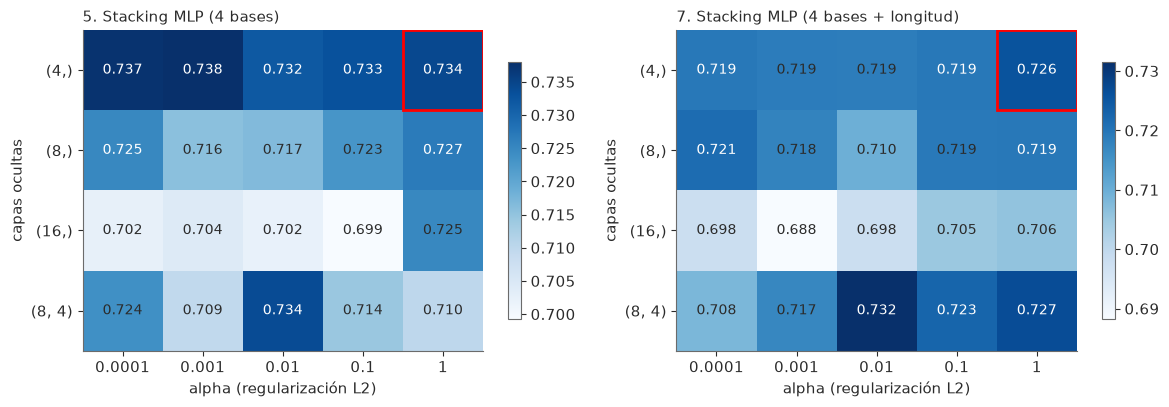

In [25]:
fig, ejes = plt.subplots(1, 2, figsize = (12, 4.2))
for ax, nombre in zip(ejes, SISTEMAS_MLP):
    grid = grids_mlp[nombre]
    tabla = grid.pivot(index = 'capas', columns = 'alpha', values = 'F1_fake_media')
    orden = []
    for capas in REJILLA_MLP_CAPAS:
        orden.append(str(capas))
    tabla = tabla.loc[orden, REJILLA_MLP_ALPHA]
    imagen = ax.imshow(tabla.values, cmap = 'Blues', aspect = 'auto')
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            valor = tabla.values[i, j]
            color = 'white' if valor > np.percentile(tabla.values, 60) else TINTA
            ax.text(j, i, f'{valor:.3f}', ha = 'center', va = 'center', color = color, fontsize = 10)
    elegida = regla_un_se_mlp(grid)
    fila_elegida = orden.index(elegida['capas'])
    columna_elegida = REJILLA_MLP_ALPHA.index(elegida['alpha'])
    ax.add_patch(Rectangle((columna_elegida - 0.5, fila_elegida - 0.5), 1, 1, fill = False, edgecolor = 'red', linewidth = 2))
    ax.set_xticks(range(len(REJILLA_MLP_ALPHA)), [str(a) for a in REJILLA_MLP_ALPHA])
    ax.set_yticks(range(len(orden)), orden)
    ax.set_xlabel('alpha (regularización L2)')
    ax.set_ylabel('capas ocultas')
    ax.set_title(nombre, fontsize = 11)
    ax.grid(False)
    fig.colorbar(imagen, ax = ax, shrink = 0.8)
fig.tight_layout()
guardar(fig, '5_1_beto_mlp_grid')
plt.show()

**Tabla 5.2.** Esquema B de la MLP: combinación elegida en cada fold externo, F1 de fake con cada semilla y su variación.

In [26]:
pd.concat(estabilidad_mlp, names = ['sistema', 'renglón']).droplevel('renglón').round(4)

,fold externo,capas,alpha,F1 promedio de semillas,semilla 0,semilla 1,semilla 2,semilla 3,semilla 4,sd entre semillas,sd media de la probabilidad
sistema,,,,,,,,,,,
5. Stacking MLP (4 bases),0,"(4,)",1.0,0.8397,0.8308,0.8244,0.8409,0.8346,0.8308,0.0060,0.0265
5. Stacking MLP (4 bases),1,"(4,)",1.0,0.6259,0.6533,0.6443,0.6533,0.6400,0.5775,0.0320,0.0342
5. Stacking MLP (4 bases),2,"(4,)",1.0,0.7375,0.7170,0.7453,0.7273,0.7250,0.7170,0.0116,0.0322
5. Stacking MLP (4 bases),3,"(4,)",1.0,0.6968,0.7134,0.6790,0.6974,0.7059,0.6923,0.0131,0.0286
5. Stacking MLP (4 bases),4,"(4,)",1.0,0.7719,0.7674,0.7701,0.7674,0.7816,0.7674,0.0061,0.0303
7. Stacking MLP (4 bases + longitud),0,"(4,)",1.0,0.8249,0.8235,0.8308,0.8352,0.8157,0.8127,0.0096,0.0473
7. Stacking MLP (4 bases + longitud),1,"(4,)",1.0,0.5986,0.6275,0.5493,0.5714,0.6623,0.6133,0.0449,0.0364
7. Stacking MLP (4 bases + longitud),2,"(4,)",1.0,0.7329,0.7362,0.7468,0.7284,0.7342,0.7170,0.0110,0.0406
7. Stacking MLP (4 bases + longitud),3,"(4,)",0.1,0.6710,0.6883,0.6832,0.6842,0.6624,0.6500,0.0166,0.0564


**Figura 5.2.** Figura de dependencia: probabilidad final del meta-modelo cuando varía la probabilidad de BETO, con la LR, XGBoost y el bosque fijos en su mediana. Hay una curva por cuartil de longitud (la longitud fija en la mediana de su cuartil). Izquierda: la MLP del sistema 7; la línea negra punteada es la MLP sin longitud (sistema 5). Derecha: la LR del sistema 6, su control lineal.

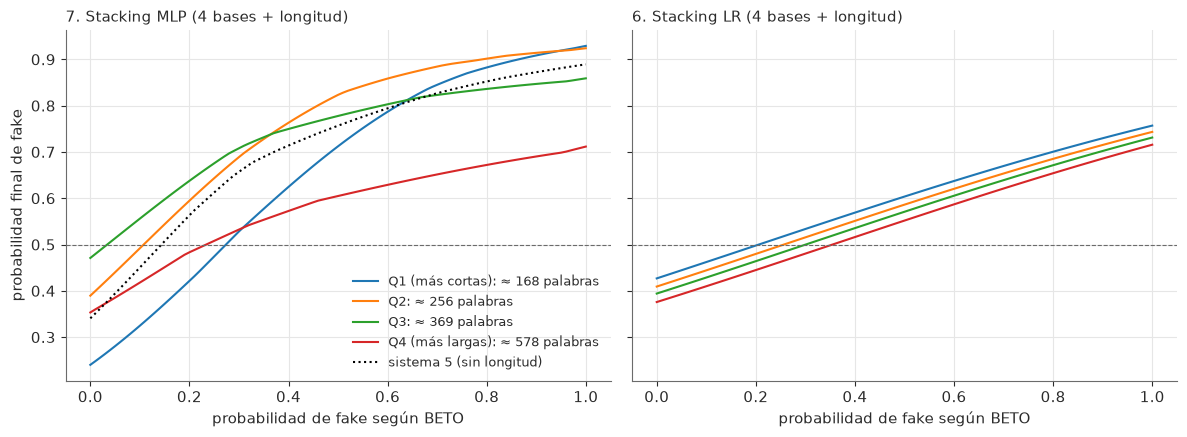

In [27]:
def prob_meta(nombre, X):
    '''
    Función que aplica un meta-modelo final (LR o lista de MLP) a unas entradas

    inputs:
    --------
        nombre (str): Sistema de SISTEMAS_META
        X (numpy.ndarray): Entradas en el orden de SISTEMAS_META[nombre]['entradas']

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake
    '''
    if SISTEMAS_META[nombre]['meta'] == 'MLP':
        return predecir_semillas(metas_finales[nombre], X).mean(axis = 0)
    return metas_finales[nombre].predict_proba(X)[:, 1]

def entradas_curva(nombre, valores_beto, longitud):
    '''
    Función que arma las entradas de la figura de dependencia: BETO varía y lo demás queda fijo

    inputs:
    --------
        nombre (str): Sistema de SISTEMAS_META
        valores_beto (numpy.ndarray): Valores de la probabilidad de BETO
        longitud (float): Valor fijo de est_log_palabras

    outputs:
    --------
        numpy.ndarray: Matriz de entradas
    '''
    columnas = {}
    for entrada in SISTEMAS_META[nombre]['entradas']:
        if entrada == 'BETO':
            columnas[entrada] = valores_beto
        elif entrada == 'est_log_palabras':
            columnas[entrada] = np.full(len(valores_beto), longitud)
        else:
            columnas[entrada] = np.full(len(valores_beto), M[entrada].median())
    return pd.DataFrame(columnas).values

valores_beto = np.linspace(0, 1, 101)
fig, ejes = plt.subplots(1, 2, figsize = (12, 4.5), sharey = True)
for ax, nombre in zip(ejes, ['7. Stacking MLP (4 bases + longitud)', '6. Stacking LR (4 bases + longitud)']):
    for q in CUARTILES:
        longitud = M.loc[(cuartil_cv == q).values, 'est_log_palabras'].median()
        curva = prob_meta(nombre, entradas_curva(nombre, valores_beto, longitud))
        ax.plot(valores_beto, curva, label = f'{q}: ≈ {np.expm1(longitud):.0f} palabras')
    if nombre.startswith('7'):
        curva = prob_meta('5. Stacking MLP (4 bases)', entradas_curva('5. Stacking MLP (4 bases)', valores_beto, 0))
        ax.plot(valores_beto, curva, color = 'black', linestyle = ':', label = 'sistema 5 (sin longitud)')
    ax.axhline(0.5, color = TINTA_SUAVE, linewidth = 0.8, linestyle = '--')
    ax.set_xlabel('probabilidad de fake según BETO')
    ax.set_title(nombre, fontsize = 11)
ejes[0].set_ylabel('probabilidad final de fake')
ejes[0].legend(fontsize = 9)
fig.tight_layout()
guardar(fig, '5_2_beto_dependencia')
plt.show()

**Qué se observa.**

* **La regla de un SE elige la red más chica y más regularizada** en los dos sistemas: 4 neuronas con `alpha` = 1. El sistema 5 da 0.7343, contra la mejor media de 0.7380. El sistema 7 da 0.7256, contra la mejor de 0.7273, que era la red de dos capas. Una red de 4 neuronas con regularización fuerte se comporta casi como una función lineal.
* **El *grid* es plano** (Figura 5.1): en el sistema 5 va de 0.6958 a 0.7380, una diferencia del orden de un SE. De 5,060 redes entrenadas, 46 avisaron que no convergieron en 2,000 iteraciones.
* **La inicialización importa poco una vez que se promedia** (Tabla 5.2): la sd de la F1 entre semillas es de 0.0449 o menos en cada fold externo, y la más alta es la del fold de la sátira.
* **La figura de dependencia muestra lo contrario de lo que se esperaba** (Figura 5.2). En el sistema 7, la curva de las noticias más largas (Q4) es la más plana: ahí la probabilidad de BETO mueve poco la decisión final. La red aprendió "en noticias largas, confía **menos** en BETO", que es lo que dicen los datos de CV: BETO detecta solo el 16.1 % de las falsas largas (Tabla 3.4). En el sistema 6, la LR solo desplaza las curvas en paralelo.

**La red no encuentra una combinación no lineal útil: elige la arquitectura más simple, y lo único no lineal que aprende es desconfiar de BETO en las noticias largas.**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Comparación en CV (esquema B)</span></div>

> **Qué se hace:** juntamos las probabilidades *out-of-fold* de las 4 bases y las del esquema B de los meta-modelos, las cortamos en 0.5 y calculamos todas las métricas por fold, las diferencias pareadas contra la LR y las matrices de confusión.
>
> **Qué se espera ver:** que algún stacking con BETO le gane a la LR en la mayoría de los folds; en el ensamble anterior, el stacking perdió en 3 de 5.

#### Glosario de la sección
* **Diferencia pareada por fold:** restamos la F1 de la LR a la del sistema **en el mismo fold**. Así se cancela la dificultad propia de cada fold (el fold 1 es fácil para la LR y difícil para los árboles).
* **Media ± sd:** promedio de los 5 folds y su desviación estándar. Con 5 folds, una diferencia menor que la sd de las diferencias no es concluyente.

In [28]:
prob_cv['LR texto (principal)'] = Z['LR texto'].values
prob_cv['XGBoost'] = Z['XGBoost'].values
prob_cv['RF estilo'] = Z['RF estilo'].values
prob_cv['1. BETO solo'] = Z['BETO'].values
prob_cv['2. Soft voting LR + BETO'] = Z[['LR texto', 'BETO']].mean(axis = 1).values
ORDEN = ['LR texto (principal)', 'XGBoost', 'RF estilo', '1. BETO solo', '2. Soft voting LR + BETO',
         '3. Stacking LR (LR + BETO)', '4. Stacking LR (4 bases)', '5. Stacking MLP (4 bases)',
         '6. Stacking LR (4 bases + longitud)', '7. Stacking MLP (4 bases + longitud)', 'Stacking viejo (LR + XGBoost + RF)']
pred_cv = {}
for nombre in ORDEN:
    pred_cv[nombre] = clases(prob_cv[nombre])

filas = []
for nombre in ORDEN:
    for k in range(5):
        en_k = folds == k
        fila = {'sistema': nombre, 'fold': k}
        fila.update(uf.metricas(y[en_k], pred_cv[nombre][en_k]))
        filas.append(fila)
cv_sistemas = pd.DataFrame(filas)
guardar_csv(cv_sistemas, 'beto_stacking_cv')

'resultados/beto_stacking_cv.csv'

**Tabla 6.1.** F1 de fake en cada fold (esquema B para los meta-modelos), con media y sd.

In [29]:
f1_cv = cv_sistemas.pivot(index = 'sistema', columns = 'fold', values = 'F1_fake').loc[ORDEN]
f1_cv.columns = [f'fold {k}' for k in range(5)]
f1_cv['media'] = f1_cv.mean(axis = 1)
f1_cv['sd'] = f1_cv.iloc[:, :5].std(axis = 1)
f1_cv.round(4)

,fold 0,fold 1,fold 2,fold 3,fold 4,media,sd
sistema,,,,,,,
LR texto (principal),0.7848,0.8541,0.6345,0.6375,0.7381,0.7298,0.0951
XGBoost,0.7680,0.6173,0.7239,0.6199,0.6982,0.6855,0.0660
RF estilo,0.7160,0.3239,0.6839,0.5904,0.7273,0.6083,0.1678
1. BETO solo,0.7328,0.3130,0.7651,0.6767,0.7919,0.6559,0.1964
2. Soft voting LR + BETO,0.7532,0.4480,0.7568,0.6716,0.7785,0.6816,0.1368
3. Stacking LR (LR + BETO),0.8110,0.6842,0.7722,0.6923,0.7719,0.7463,0.0554
4. Stacking LR (4 bases),0.8048,0.6259,0.7468,0.6974,0.7746,0.7299,0.0703
5. Stacking MLP (4 bases),0.8397,0.6259,0.7375,0.6968,0.7719,0.7343,0.0802
6. Stacking LR (4 bases + longitud),0.8417,0.5072,0.7421,0.6707,0.7771,0.7078,0.1280


**Tabla 6.2.** Todas las métricas en CV: media de los 5 folds (y sd de la F1 de fake).

In [30]:
resumen_cv = cv_sistemas.drop(columns = 'fold').groupby('sistema', sort = False).mean()
resumen_cv['sd F1_fake'] = cv_sistemas.groupby('sistema', sort = False)['F1_fake'].std()
resumen_cv.round(4)

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,sd F1_fake
sistema,,,,,,,
LR texto (principal),0.7298,0.7738,0.7518,0.7553,0.7757,0.6952,0.0951
XGBoost,0.6855,0.7204,0.7029,0.7056,0.7127,0.6661,0.0660
RF estilo,0.6083,0.6861,0.6472,0.6559,0.6536,0.5826,0.1678
1. BETO solo,0.6559,0.7860,0.7210,0.7421,0.8624,0.5566,0.1964
2. Soft voting LR + BETO,0.6816,0.7924,0.7370,0.7525,0.8729,0.5762,0.1368
3. Stacking LR (LR + BETO),0.7463,0.7877,0.7670,0.7712,0.8049,0.7052,0.0554
4. Stacking LR (4 bases),0.7299,0.7807,0.7553,0.7608,0.7990,0.6845,0.0703
5. Stacking MLP (4 bases),0.7343,0.7816,0.7580,0.7635,0.7918,0.6980,0.0802
6. Stacking LR (4 bases + longitud),0.7078,0.7653,0.7365,0.7440,0.7656,0.6801,0.1280


**Tabla 6.3.** Diferencia pareada de F1 de fake por fold frente a la LR de texto (el principal).

In [31]:
filas = []
for nombre in ORDEN[1:]:
    d = f1_cv.loc[nombre].iloc[:5].values - f1_cv.loc['LR texto (principal)'].iloc[:5].values
    fila = {'sistema': nombre}
    for k in range(5):
        fila[f'fold {k}'] = d[k]
    fila['diferencia media'] = d.mean()
    fila['sd'] = d.std(ddof = 1)
    fila['folds en que gana'] = int((d > 0).sum())
    filas.append(fila)
diferencias_cv = pd.DataFrame(filas).set_index('sistema')
diferencias_cv.round(4)

,fold 0,fold 1,fold 2,fold 3,fold 4,diferencia media,sd,folds en que gana
sistema,,,,,,,,
XGBoost,-0.0168,-0.2368,0.0894,-0.0176,-0.0399,-0.0443,0.1188,1
RF estilo,-0.0688,-0.5301,0.0494,-0.0471,-0.0108,-0.1215,0.2328,1
1. BETO solo,-0.0521,-0.5410,0.1306,0.0392,0.0539,-0.0739,0.2691,3
2. Soft voting LR + BETO,-0.0316,-0.4061,0.1223,0.0341,0.0404,-0.0482,0.2074,3
3. Stacking LR (LR + BETO),0.0262,-0.1698,0.1377,0.0548,0.0338,0.0165,0.1132,4
4. Stacking LR (4 bases),0.0200,-0.2282,0.1124,0.0599,0.0365,0.0001,0.1323,4
5. Stacking MLP (4 bases),0.0549,-0.2282,0.1030,0.0593,0.0338,0.0046,0.1325,4
6. Stacking LR (4 bases + longitud),0.0569,-0.3468,0.1077,0.0332,0.0390,-0.0220,0.1839,4
7. Stacking MLP (4 bases + longitud),0.0401,-0.2554,0.0984,0.0335,0.0498,-0.0067,0.1413,4


**Tabla 6.4.** El stacking viejo con las dos estimaciones: esquema B (este notebook, XGBoost de Linux) y CV anidada completa (`ensamble_stacking.ipynb`, XGBoost de Windows). La diferencia da una idea de cuánto infla el esquema B por su fuga residual (mezclada con la diferencia de XGBoost entre sistemas operativos).

In [32]:
viejo_b = f1_cv.loc['Stacking viejo (LR + XGBoost + RF)', 'media']
viejo_anidado = seleccion_vieja['cv_anidada']['stacking']
pd.DataFrame([('esquema B (este notebook)', round(viejo_b, 4)),
              ('CV anidada completa (ensamble_stacking.ipynb)', round(viejo_anidado, 4)),
              ('esquema B − anidada', round(viejo_b - viejo_anidado, 4))], columns = ['estimación', 'F1 de fake media'])

,estimación,F1 de fake media
0,esquema B (este notebook),0.7312
1,CV anidada completa (ensamble_stacking.ipynb),0.6842
2,esquema B − anidada,0.0470


**Figura 6.1.** Matrices de confusión en CV (las 961 predicciones *out-of-fold*, sumando los 5 folds) de todos los sistemas.

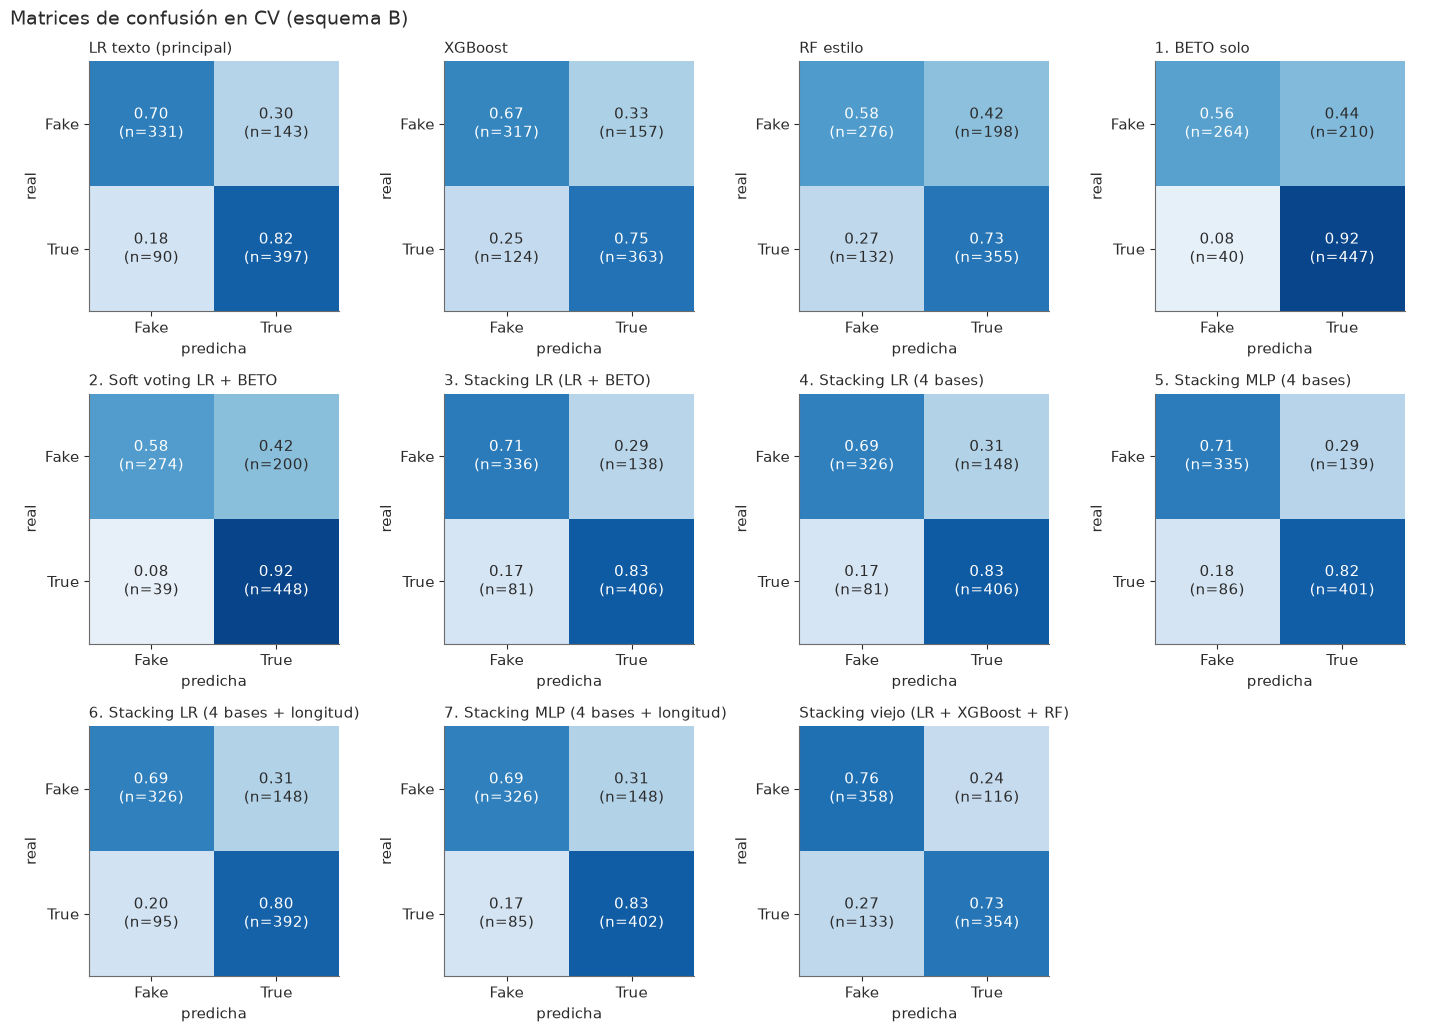

In [33]:
cuadricula_matrices(y, pred_cv, 'Matrices de confusión en CV (esquema B)', '6_1_beto_matrices_cv')

**Tabla 6.5.** Falsas detectadas y verdaderas acertadas (%) por cuartil de longitud, en CV, para todos los sistemas.

In [34]:
deteccion_por_cuartil(y, pred_cv, cuartil_cv)

LR texto (principal)  XGBoost  \
falsas detectadas (%)    Q1 (más cortas)                  75.8     81.7   
                         Q2                               69.4     70.7   
                         Q3                               74.1     60.7   
                         Q4 (más largas)                  48.4     32.3   
verdaderas acertadas (%) Q1 (más cortas)                  66.7     51.1   
                         Q2                               69.9     53.8   
                         Q3                               85.8     81.1   
                         Q4 (más largas)                  92.1     92.7   

                                          RF estilo  1. BETO solo  \
falsas detectadas (%)    Q1 (más cortas)       76.5          81.0   
                         Q2                    70.7          63.3   
                         Q3                    43.8          33.0   
                         Q4 (más largas)        9.7          16.1   
verdaderas acertadas (%) Q1 (más cortas)       52.2          81.1   
                         Q2                    58.1          90.3   
                         Q3                    71.7          94.5   
                         Q4 (más largas)       92.1          96.0   

                                          2. Soft voting LR + BETO  \
falsas detectadas (%)    Q1 (más cortas)                      80.4   
                         Q2                                   65.3   
                         Q3                                   38.4   
                         Q4 (más largas)                      19.4   
verdaderas acertadas (%) Q1 (más cortas)                      81.1   
                         Q2                                   89.2   
                         Q3                                   95.3   
                         Q4 (más largas)                      96.6   

                                          3. Stacking LR (LR + BETO)  \
falsas detectadas (%)    Q1 (más cortas)                        85.6   
                         Q2                                     76.2   
                         Q3                                     61.6   
                         Q4 (más largas)                        38.7   
verdaderas acertadas (%) Q1 (más cortas)                        68.9   
                         Q2                                     76.3   
                         Q3                                     85.8   
                         Q4 (más largas)                        92.7   

                                          4. Stacking LR (4 bases)  \
falsas detectadas (%)    Q1 (más cortas)                      86.3   
                         Q2                                   74.1   
                         Q3                                   55.4   
                         Q4 (más largas)                      37.1   
verdaderas acertadas (%) Q1 (más cortas)                      67.8   
                         Q2                                   78.5   
                         Q3                                   86.6   
                         Q4 (más largas)                      91.5   

                                          5. Stacking MLP (4 bases)  \
falsas detectadas (%)    Q1 (más cortas)                       86.9   
                         Q2                                    78.2   
                         Q3                                    58.0   
                         Q4 (más largas)                       35.5   
verdaderas acertadas (%) Q1 (más cortas)                       67.8   
                         Q2                                    76.3   
                         Q3                                    88.2   
                         Q4 (más largas)                       88.7   

                                          6. Stacking LR (4 bases + longitud)  \
falsas detectadas (%)    Q1 (más cortas)                                 88.2   
                         Q2    

**Qué se observa.**

* **El sistema 3 (LR + BETO, meta-modelo LR) es el mejor en CV:** 0.7463 ± 0.0554, contra 0.7298 ± 0.0951 de la LR. Además es el más estable: su sd es la más baja de la tabla.
* **Gana en 4 de 5 folds; el único que pierde es el de la sátira** (−0.1698). Lo mismo les pasa a los cinco stackings con BETO. En promedio, los demás quedan prácticamente empatados con la LR: sistema 4 +0.0001, 5 +0.0046, 6 −0.0220 y 7 −0.0067.
* **La ventaja del sistema 3 no es concluyente.** Su diferencia media (+0.0165 ± 0.1132) es mucho menor que su sd. Además, el stacking viejo da 0.7312 con el esquema B contra 0.6842 con CV anidada completa (Tabla 6.4): el esquema B puede inflar del orden de +0.0470, que es más que toda la ganancia del sistema 3.
* **El soft voting no sirve** (0.6816): en el fold de la sátira pierde −0.4061, porque le da la mitad del voto a BETO sin importar que ahí falle.
* **Por cuartil de longitud, en CV, ningún stacking con BETO detecta más falsas largas que la LR** (Tabla 6.5): el sistema 3 detecta el 38.7 % del Q4, contra 48.4 % de la LR y 51.6 % del stacking viejo.

**En CV, solo el stacking LR + BETO mejora la media y gana en 4 de 5 folds, pero con una diferencia que cabe dentro del ruido y del sesgo optimista del esquema B.**

<a id="fase-evaluacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Evaluación (sistema aparte)</span></div>

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Aplicación única en el test</span></div>

> **Qué se hace:** guardamos las elecciones (`seleccion_beto.json`) **antes** de cargar el test; entrenamos las 3 bases clásicas con las 961 noticias, tomamos BETO de `beto_test.csv` y aplicamos los meta-modelos entrenados con todo el *out-of-fold*. Se corre **una sola vez**.
>
> **Qué se espera ver:** que el orden entre sistemas se parezca al de la CV; con 572 noticias, diferencias menores que ±0.04 no serán concluyentes.

#### Glosario de la sección
* **IC95 bootstrap:** remuestreamos el test 1,000 veces con reemplazo y tomamos los percentiles 2.5 y 97.5 de la F1. Usamos **los mismos remuestreos** de `evaluacion.ipynb`, así que las diferencias entre sistemas son pareadas.
* **McNemar exacta:** cuenta las noticias que acierta solo un sistema y solo el otro, y prueba si esa diferencia podría deberse al azar (binomial con p = 0.5). Mide exactitud, no F1.

Los sistemas, sus hiperparámetros y el umbral 0.5 quedaron fijados antes de esta sección. El umbral 0.34 (`umbral.ipynb`) y el stacking viejo tal como se reportó (`ensamble_stacking.ipynb`) entran como referencias, leídos de sus archivos.

In [35]:
seleccion = {'bases': BASES, 'config_lr': config_lr, 'config_rf': config_rf, 'config_xgb': config_xgb,
             'beto': {'modelo': 'dccuchile/bert-base-spanish-wwm-uncased', 'tokens': '128 cabeza + 382 cola', 'epocas': 4,
                      'learning_rate': 2e-5, 'lote_efectivo': 16, 'semillas': SEMILLAS_BETO},
             'meta_modelos': {}, 'cv_esquema_b': {}}
for nombre in SISTEMAS_META:
    datos = {'entradas': SISTEMAS_META[nombre]['entradas'], 'meta': SISTEMAS_META[nombre]['meta']}
    datos.update(eleccion_meta[nombre])
    if SISTEMAS_META[nombre]['meta'] == 'LR':
        datos['pesos'] = dict(zip(SISTEMAS_META[nombre]['entradas'], [float(w) for w in metas_finales[nombre]['meta'].coef_[0]]))
        datos['intercepto'] = float(metas_finales[nombre]['meta'].intercept_[0])
    seleccion['meta_modelos'][nombre] = datos
for nombre in ORDEN:
    seleccion['cv_esquema_b'][nombre] = float(f1_cv.loc[nombre, 'media'])
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_beto.json'), 'w', encoding = 'utf-8') as f:
    json.dump(seleccion, f, ensure_ascii = False, indent = 1)

# Carga única del test
test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'))
y_test = test['Category'].values
Z_test = pd.DataFrame(index = test.index)
for nombre in BASES_CLASICAS:
    Z_test[nombre] = probabilidad_fake(entrenar_base(nombre, corpus), test)
Z_test['BETO'] = beto_test.set_index('id_unico').loc[test['id_unico'], 'prob_beto'].values
M_test = Z_test.copy()
M_test['est_log_palabras'] = test['est_log_palabras'].values

prob_test = {'LR texto (principal)': Z_test['LR texto'].values, 'XGBoost': Z_test['XGBoost'].values,
             'RF estilo': Z_test['RF estilo'].values, '1. BETO solo': Z_test['BETO'].values,
             '2. Soft voting LR + BETO': Z_test[['LR texto', 'BETO']].mean(axis = 1).values}
for nombre in SISTEMAS_META:
    prob_test[nombre] = prob_meta(nombre, M_test[SISTEMAS_META[nombre]['entradas']].values)

previas_umbral = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'predicciones_test_umbral.csv')).set_index('id_unico').loc[test['id_unico']]
previas_stacking = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'predicciones_test_stacking.csv')).set_index('id_unico').loc[test['id_unico']]
previas_eval = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'predicciones_test.csv')).set_index('id_unico').loc[test['id_unico']]

predicciones = {}
for nombre in ORDEN:
    predicciones[nombre] = clases(prob_test[nombre])
predicciones['LR texto, umbral 0.34 (referencia)'] = previas_umbral['LR texto, umbral 0.34'].values
predicciones['Stacking viejo reportado (referencia)'] = previas_stacking['Stacking (meta-modelo LR)'].values

**Tabla 7.1.** Verificaciones del test.

In [36]:
igual_principal = 100 * float(np.mean(predicciones['LR texto (principal)'] == previas_eval['LR texto (principal)'].values))
igual_viejo = 100 * float(np.mean(predicciones['Stacking viejo (LR + XGBoost + RF)'] == previas_stacking['Stacking (meta-modelo LR)'].values))
verificaciones.append(fila_verificacion('Principal en el test igual a predicciones_test.csv', '100 %', f'{igual_principal:.1f} %', marca(igual_principal == 100)))
verificaciones.append(fila_verificacion('Stacking viejo recalculado igual al reportado (informativo: XGBoost de Linux)', '—', f'{igual_viejo:.1f} % de coincidencia',
                                        '✅' if igual_viejo == 100 else '⚠️ informativo'))
pd.DataFrame(verificaciones[-2:])

,verificación,esperado,obtenido,estado
0,Principal en el test igual a predicciones_test...,100 %,100.0 %,✅
1,Stacking viejo recalculado igual al reportado ...,—,96.5 % de coincidencia,⚠️ informativo


**Tabla 7.2.** Métricas en el test. El intervalo es bootstrap del 95 % de la F1 de fake; la columna de CV es la media del esquema B (para las referencias, su estimación original).

In [37]:
rng = np.random.default_rng(SEMILLA)
indices_boot = rng.integers(0, len(test), size = (N_BOOTSTRAP, len(test)))

def f1_bootstrap(pred):
    '''
    Función que calcula la F1 de fake en cada remuestreo bootstrap del test

    inputs:
    --------
        pred (numpy.ndarray): Predicciones del sistema sobre el test

    outputs:
    --------
        numpy.ndarray: F1 de fake en cada uno de los N_BOOTSTRAP remuestreos
    '''
    valores = []
    for i in indices_boot:
        valores.append(uf.f1_fake(y_test[i], pred[i]))
    return np.array(valores)

boot = {}
for nombre, pred in predicciones.items():
    boot[nombre] = f1_bootstrap(pred)

cv_de = {}
for nombre in ORDEN:
    cv_de[nombre] = f1_cv.loc[nombre, 'media']
cv_de['LR texto, umbral 0.34 (referencia)'] = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'umbral_anidado.csv'))['F1 fake con umbral interno'].mean()
cv_de['Stacking viejo reportado (referencia)'] = seleccion_vieja['cv_anidada']['stacking']

def tabla_test(nombres):
    '''
    Función que arma la tabla de métricas del test con IC95 bootstrap

    inputs:
    --------
        nombres (list): Sistemas de predicciones

    outputs:
    --------
        pandas.DataFrame: Una fila por sistema
    '''
    filas = []
    for nombre in nombres:
        pred = predicciones[nombre]
        fila = {'sistema': nombre}
        for metrica, valor in uf.metricas(y_test, pred).items():
            fila[metrica] = round(valor, 4)
        fila['IC95 F1_fake'] = f'[{np.percentile(boot[nombre], 2.5):.3f}, {np.percentile(boot[nombre], 97.5):.3f}]'
        fila['F1_fake en CV'] = round(cv_de[nombre], 3)
        fila['predichas Fake'] = int((pred == 'Fake').sum())
        filas.append(fila)
    return pd.DataFrame(filas).set_index('sistema')

resultados_test = tabla_test(list(predicciones.keys()))
guardar_csv(resultados_test, 'beto_stacking_test', index = True)
resultados_test

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,F1_fake en CV,predichas Fake
sistema,,,,,,,,,
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",0.730,193
XGBoost,0.6371,0.7222,0.6797,0.6853,0.7524,0.5524,"[0.586, 0.686]",0.685,210
RF estilo,0.5054,0.6637,0.5846,0.5997,0.6610,0.4091,"[0.446, 0.560]",0.608,177
1. BETO solo,0.6931,0.7574,0.7253,0.7290,0.7991,0.6119,"[0.643, 0.736]",0.656,219
2. Soft voting LR + BETO,0.7080,0.7733,0.7406,0.7448,0.8271,0.6189,"[0.660, 0.752]",0.682,214
3. Stacking LR (LR + BETO),0.7357,0.7629,0.7493,0.7500,0.7804,0.6958,"[0.690, 0.778]",0.746,255
4. Stacking LR (4 bases),0.7378,0.7705,0.7542,0.7552,0.7944,0.6888,"[0.693, 0.778]",0.730,248
5. Stacking MLP (4 bases),0.7450,0.7614,0.7532,0.7535,0.7715,0.7203,"[0.700, 0.783]",0.734,267
6. Stacking LR (4 bases + longitud),0.7566,0.7869,0.7717,0.7727,0.8145,0.7063,"[0.712, 0.796]",0.708,248


**Tabla 7.3.** Comparaciones pareadas en el test: diferencia de F1 de fake con IC95 bootstrap pareado y McNemar exacta, contra las tres referencias.

In [38]:
def comparar(a, b):
    '''
    Función que compara dos sistemas en el test con bootstrap pareado y McNemar exacta

    inputs:
    --------
        a (str): Sistema que se compara
        b (str): Sistema de referencia

    outputs:
    --------
        dict: Diferencia de F1 de fake, IC95 pareado, remuestreos en que gana a y McNemar
    '''
    dif = boot[a] - boot[b]
    ok_a = predicciones[a] == y_test
    ok_b = predicciones[b] == y_test
    solo_a = int((ok_a & ~ok_b).sum())
    solo_b = int((~ok_a & ok_b).sum())
    p_mcnemar = stats.binomtest(solo_a, solo_a + solo_b, 0.5).pvalue if solo_a + solo_b > 0 else 1.0
    return {'sistema': a, 'referencia': b,
            'diferencia F1 fake': round(uf.f1_fake(y_test, predicciones[a]) - uf.f1_fake(y_test, predicciones[b]), 3),
            'IC95 pareado': f'[{np.percentile(dif, 2.5):+.3f}, {np.percentile(dif, 97.5):+.3f}]',
            'remuestreos en que gana': f'{int((dif > 0).sum())} de {N_BOOTSTRAP}',
            'McNemar (solo a / solo b)': f'{solo_a} / {solo_b}', 'p McNemar': round(p_mcnemar, 3)}

filas = []
for referencia in ['LR texto (principal)', 'LR texto, umbral 0.34 (referencia)', 'Stacking viejo reportado (referencia)']:
    for nombre in ORDEN:
        if nombre != referencia:
            filas.append(comparar(nombre, referencia))
comparaciones_test = pd.DataFrame(filas)
comparaciones_test

,sistema,referencia,diferencia F1 fake,IC95 pareado,remuestreos en que gana,McNemar (solo a / solo b),p McNemar
0,XGBoost,LR texto (principal),-0.039,"[-0.078, +0.003]",34 de 1000,29 / 54,0.008
1,RF estilo,LR texto (principal),-0.171,"[-0.226, -0.114]",0 de 1000,29 / 103,0.000
2,1. BETO solo,LR texto (principal),0.017,"[-0.032, +0.064]",753 de 1000,59 / 59,1.000
3,2. Soft voting LR + BETO,LR texto (principal),0.032,"[-0.014, +0.075]",916 de 1000,54 / 45,0.422
4,3. Stacking LR (LR + BETO),LR texto (principal),0.059,"[+0.020, +0.100]",998 de 1000,53 / 41,0.256
5,4. Stacking LR (4 bases),LR texto (principal),0.061,"[+0.020, +0.105]",996 de 1000,56 / 41,0.155
6,5. Stacking MLP (4 bases),LR texto (principal),0.069,"[+0.027, +0.110]",998 de 1000,57 / 43,0.193
7,6. Stacking LR (4 bases + longitud),LR texto (principal),0.080,"[+0.042, +0.119]",1000 de 1000,51 / 26,0.006
8,7. Stacking MLP (4 bases + longitud),LR texto (principal),0.060,"[+0.021, +0.100]",999 de 1000,51 / 37,0.165
9,Stacking viejo (LR + XGBoost + RF),LR texto (principal),0.027,"[-0.004, +0.057]",963 de 1000,26 / 24,0.888


**Figura 7.1.** Matrices de confusión en el test (572 noticias) de todos los sistemas y las dos referencias.

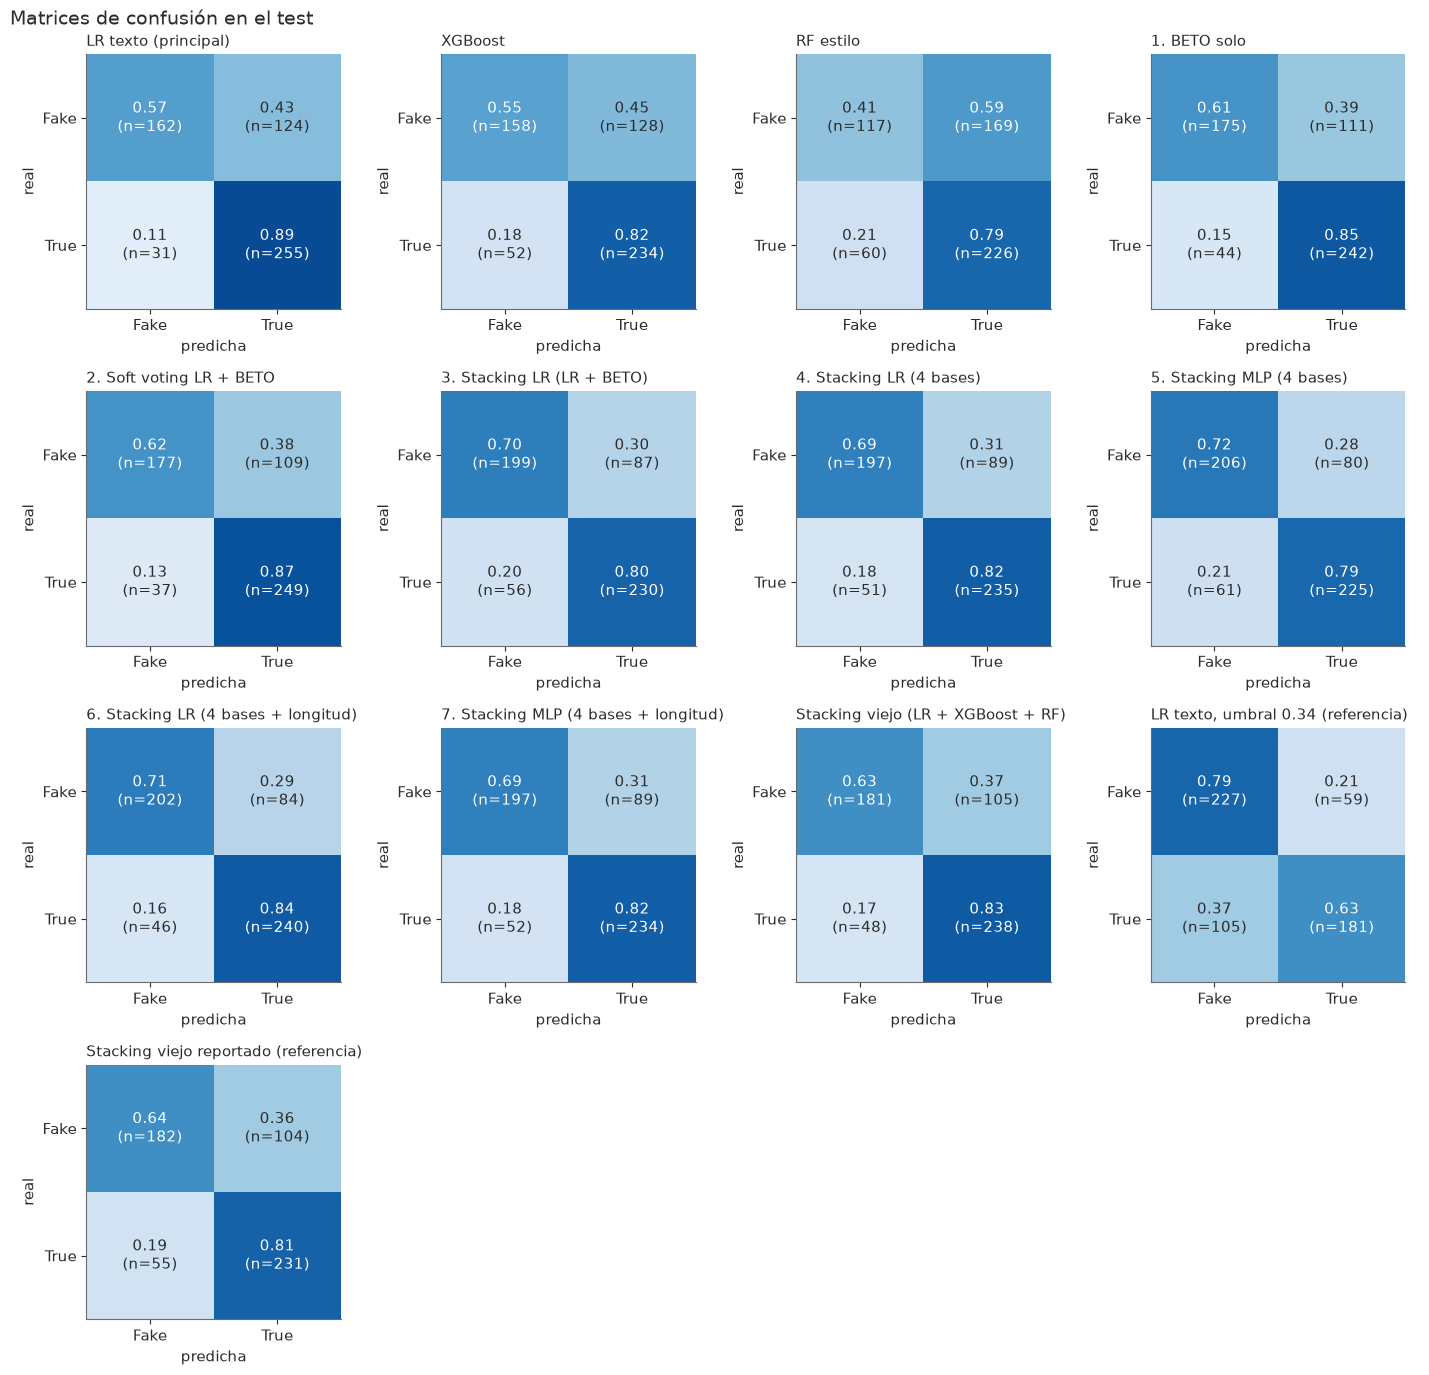

In [39]:
cuadricula_matrices(y_test, predicciones, 'Matrices de confusión en el test', '7_1_beto_matrices_test')

**Figura 7.2.** F1 de fake en el test con intervalo bootstrap del 95 %. Las líneas verticales son los resultados oficiales en el mismo test.

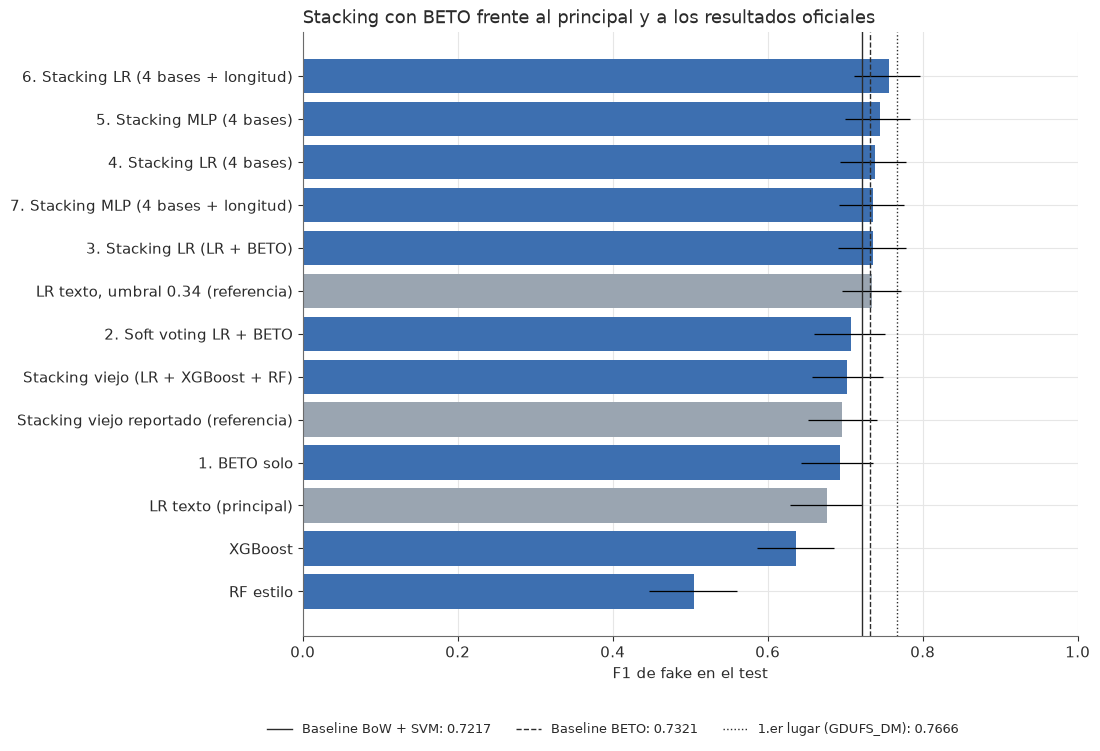

In [40]:
def figura_f1_test(nombres, nombre_figura, titulo):
    '''
    Función que dibuja la F1 de fake del test con IC95 y las líneas oficiales

    inputs:
    --------
        nombres (list): Sistemas a dibujar
        nombre_figura (str): Nombre del archivo
        titulo (str): Título de la figura

    outputs:
    --------
        None
    '''
    tabla = tabla_test(nombres)
    orden = tabla['F1_fake'].sort_values().index
    abajo = []
    arriba = []
    colores = []
    for nombre in orden:
        abajo.append(tabla.loc[nombre, 'F1_fake'] - np.percentile(boot[nombre], 2.5))
        arriba.append(np.percentile(boot[nombre], 97.5) - tabla.loc[nombre, 'F1_fake'])
        if 'referencia' in nombre or nombre == 'LR texto (principal)':
            colores.append('#9aa5b1')
        elif 'exploratorio' in nombre:
            colores.append('#c9a227')
        else:
            colores.append('#3D6FB0')
    alto = 0.45 * len(orden) + 2
    fig, ax = plt.subplots(figsize = (10, alto))
    ax.barh(orden, tabla.loc[orden, 'F1_fake'], xerr = np.array([abajo, arriba]), color = colores, error_kw = {'lw': 0.9})
    for (etiqueta, valor), estilo in zip(OFICIALES.items(), ['-', '--', ':']):
        ax.axvline(valor, color = TINTA, linestyle = estilo, linewidth = 1, label = f'{etiqueta}: {valor:.4f}')
    ax.set_xlim(0, 1)
    ax.set_xlabel('F1 de fake en el test')
    ax.set_title(titulo)
    ax.legend(loc = 'upper center', bbox_to_anchor = (0.4, -0.06 - 0.5 / alto), ncol = 3, fontsize = 9)
    guardar(fig, nombre_figura)
    plt.show()

figura_f1_test(list(predicciones.keys()), '7_2_beto_f1_test', 'Stacking con BETO frente al principal y a los resultados oficiales')

In [41]:
salida = pd.DataFrame({'id_unico': test['id_unico'].values, 'Category': y_test})
for nombre in ORDEN:
    salida[f'prob {nombre}'] = np.round(prob_test[nombre], 4)
for nombre, pred in predicciones.items():
    salida[nombre] = pred
guardar_csv(salida, 'predicciones_test_beto')
print(f'predicciones_test_beto.csv: {salida.shape[0]} filas × {salida.shape[1]} columnas')

predicciones_test_beto.csv: 572 filas × 26 columnas


**Qué se observa.**

* **Verificación.** El principal reentrenado da las mismas 572 predicciones que `evaluacion.ipynb` (100.0 %). El stacking viejo recalculado en Linux coincide en el 96.5 % con el reportado y da 0.7029 contra 0.6960.
* **Los cinco stackings con BETO le ganan al principal** (Tabla 7.3). Sacan de 0.7357 a 0.7566 contra 0.6764, y todos los IC pareados excluyen el 0: sistema 3 +0.059 [+0.020, +0.100], 4 +0.061 [+0.020, +0.105], 5 +0.069 [+0.027, +0.110], 6 +0.080 [+0.042, +0.119] y 7 +0.060 [+0.021, +0.100]. La ganancia viene sobre todo de la exhaustividad, que sube de 0.566 a entre 0.689 y 0.720. **McNemar solo es significativa para el sistema 6** (51 contra 26, p = 0.006); para los demás va de p = 0.155 a 0.256. Es decir, mejoran la F1 de fake sin acertar significativamente más noticias en total.
* **Frente al umbral 0.34 (0.7346), empate.** Las diferencias van de +0.001 a +0.022 y todos los IC incluyen el 0.
* **Frente al stacking viejo reportado (0.6960), los stackings con BETO ganan** de +0.040 a +0.061, con IC que excluyen el 0 salvo el del sistema 3 ([−0.000, +0.076]).
* **BETO solo saca 0.6931** [0.643, 0.736]: queda abajo del BETO oficial (.7321), aunque este valor cae dentro de su intervalo, y no se distingue del principal (+0.017, IC [−0.032, +0.064]).
* **El orden cambia entre CV y test.** El sistema 6 es el peor stacking en CV (0.708) y el mejor en el test (0.7566, IC [0.712, 0.796], arriba de .7217 y .7321 en estimación puntual, sin significancia). Elegirlo por eso sería usar el test para decidir. El que se elegiría con la CV es el sistema 3, que saca 0.7357 en el test.

**En el test, agregar BETO al stacking sí mejora al principal de forma consistente (+0.06 a +0.08), pero no al umbral 0.34. La mejora es en detectar falsas, no en acertar más noticias en total.**

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Diagnóstico: ¿combina o solo mueve el umbral?</span></div>

> **Qué se hace:** para cada stacking medimos la correlación de Spearman de su probabilidad con la de cada base y comparamos su F1 con la de la LR sola cortada en el umbral que marca **el mismo número de falsas**. Lo hacemos en CV y en el test.
>
> **Qué se espera ver:** si un stacking ordena las noticias casi igual que la LR (Spearman cercano a 1) y la LR con el umbral equivalente le empata, la mejora viene de mover el corte, no de combinar. Eso le pasó al stacking viejo (Spearman 0.984).

**Esto es un diagnóstico descriptivo, no un sistema.** El umbral equivalente se calcula mirando cuántas falsas marca el stacking en esos mismos datos, así que no se puede elegir de esta forma.

In [42]:
def diagnostico_umbral(probabilidades, Z_bases, y_real, nombres):
    '''
    Función que compara cada stacking con la LR sola cortada para marcar el mismo número de falsas

    inputs:
    --------
        probabilidades (dict): Sistema -> probabilidad de fake
        Z_bases (pandas.DataFrame): Probabilidades de las 4 bases en los mismos datos
        y_real (numpy.ndarray): Clases reales
        nombres (list): Stackings a diagnosticar

    outputs:
    --------
        pandas.DataFrame: Una fila por stacking
    '''
    filas = []
    for nombre in nombres:
        prob = probabilidades[nombre]
        pred = clases(prob)
        fila = {'sistema': nombre}
        for base in BASES:
            fila[f'Spearman con {base}'] = stats.spearmanr(prob, Z_bases[base]).correlation
        n_fake = int((pred == 'Fake').sum())
        umbral_equivalente = np.sort(Z_bases['LR texto'].values)[::-1][n_fake - 1]
        pred_lr = clases(Z_bases['LR texto'], umbral_equivalente)
        fila['falsas marcadas'] = n_fake
        fila['umbral equivalente de la LR'] = umbral_equivalente
        fila['F1 de la LR con ese umbral'] = uf.f1_fake(y_real, pred_lr)
        fila['F1 del stacking'] = uf.f1_fake(y_real, pred)
        fila['coinciden (%)'] = 100 * np.mean(pred_lr == pred)
        filas.append(fila)
    return pd.DataFrame(filas).set_index('sistema')

STACKINGS = ['3. Stacking LR (LR + BETO)', '4. Stacking LR (4 bases)', '5. Stacking MLP (4 bases)',
             '6. Stacking LR (4 bases + longitud)', '7. Stacking MLP (4 bases + longitud)', 'Stacking viejo (LR + XGBoost + RF)']

**Tabla 8.1.** Diagnóstico en CV (las 961 predicciones del esquema B).

In [43]:
diagnostico_umbral(prob_cv, Z, y, STACKINGS).round(3)

,Spearman con LR texto,Spearman con XGBoost,Spearman con RF estilo,Spearman con BETO,falsas marcadas,umbral equivalente de la LR,F1 de la LR con ese umbral,F1 del stacking,coinciden (%)
sistema,,,,,,,,,
3. Stacking LR (LR + BETO),0.910,0.781,0.695,0.860,417,0.503,0.734,0.754,85.848
4. Stacking LR (4 bases),0.808,0.786,0.625,0.835,407,0.506,0.733,0.740,83.351
5. Stacking MLP (4 bases),0.863,0.808,0.625,0.856,421,0.501,0.740,0.749,83.351
6. Stacking LR (4 bases + longitud),0.871,0.849,0.720,0.822,421,0.501,0.740,0.728,84.183
7. Stacking MLP (4 bases + longitud),0.836,0.794,0.626,0.814,411,0.504,0.737,0.737,82.518
Stacking viejo (LR + XGBoost + RF),0.957,0.909,0.708,0.671,491,0.460,0.765,0.742,93.132


**Tabla 8.2.** Diagnóstico en el test.

In [44]:
diagnostico_umbral(prob_test, Z_test, y_test, STACKINGS).round(3)

,Spearman con LR texto,Spearman con XGBoost,Spearman con RF estilo,Spearman con BETO,falsas marcadas,umbral equivalente de la LR,F1 de la LR con ese umbral,F1 del stacking,coinciden (%)
sistema,,,,,,,,,
3. Stacking LR (LR + BETO),0.924,0.788,0.623,0.888,255,0.427,0.706,0.736,84.266
4. Stacking LR (4 bases),0.888,0.849,0.652,0.893,248,0.433,0.708,0.738,82.517
5. Stacking MLP (4 bases),0.910,0.809,0.561,0.887,267,0.419,0.709,0.745,84.266
6. Stacking LR (4 bases + longitud),0.927,0.878,0.679,0.849,248,0.433,0.708,0.757,87.063
7. Stacking MLP (4 bases + longitud),0.879,0.825,0.568,0.810,249,0.431,0.707,0.736,84.965
Stacking viejo (LR + XGBoost + RF),0.974,0.938,0.714,0.693,229,0.455,0.711,0.703,93.007


**Qué se observa.**

* **Esta vez el stacking no es solo la LR con otro umbral.** En el test, la probabilidad de los stackings con BETO tiene Spearman de 0.879 a 0.927 con la LR, contra 0.974 del stacking viejo.
* **La LR sola, con el umbral que marca las mismas falsas** (0.419 a 0.433), saca de 0.706 a 0.709. Los stackings con BETO sacan de 0.736 a 0.757, es decir, entre 3 y 5 centésimas más. En cambio, el stacking viejo (0.703) sigue por debajo de la LR con su umbral equivalente (0.711): lo mismo que se encontró en `ensamble_stacking.ipynb`.
* **En CV pasa lo mismo:** el sistema 3 saca 0.754 contra 0.734 de la LR con su umbral equivalente, y el stacking viejo 0.742 contra 0.765.

**Con BETO, una parte real de la mejora viene de combinar información distinta y no solo de mover el corte. Sin BETO, el stacking seguía siendo un umbral disfrazado.**

<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Falsas detectadas por longitud en el test</span></div>

> **Qué se hace:** repetimos la Tabla 6.5 en el test: porcentaje de falsas detectadas y de verdaderas acertadas por cuartil de longitud, para todos los sistemas.
>
> **Qué se espera ver:** el punto débil conocido del principal: en `ensamble_stacking.ipynb`, la LR detectaba pocas falsas del cuartil más largo y XGBoost y el bosque solo el 3 %. La pregunta es si BETO las rescata.

**Tabla 9.1.** Falsas detectadas y verdaderas acertadas (%) por cuartil de longitud en el test.

In [45]:
cuartil_test = pd.qcut(test['est_log_palabras'], 4, labels = CUARTILES)
n_falsas = []
for q in CUARTILES:
    n_falsas.append(int(((cuartil_test == q).values & (y_test == 'Fake')).sum()))
print('Falsas del test por cuartil:', dict(zip(CUARTILES, n_falsas)))
deteccion_por_cuartil(y_test, predicciones, cuartil_test)

Falsas del test por cuartil: {'Q1 (más cortas)': 110, 'Q2': 81, 'Q3': 62, 'Q4 (más largas)': 33}


LR texto (principal)  XGBoost  \
falsas detectadas (%)    Q1 (más cortas)                  78.2     78.2   
                         Q2                               54.3     59.3   
                         Q3                               38.7     35.5   
                         Q4 (más largas)                  24.2      6.1   
verdaderas acertadas (%) Q1 (más cortas)                  69.7     54.5   
                         Q2                               82.5     63.5   
                         Q3                               90.0     85.0   
                         Q4 (más largas)                  98.2     98.2   

                                          RF estilo  1. BETO solo  \
falsas detectadas (%)    Q1 (más cortas)       57.3          80.0   
                         Q2                    51.9          63.0   
                         Q3                    17.7          35.5   
                         Q4 (más largas)        3.0          42.4   
verdaderas acertadas (%) Q1 (más cortas)       48.5          63.6   
                         Q2                    58.7          73.0   
                         Q3                    81.2          90.0   
                         Q4 (más largas)       98.2          93.6   

                                          2. Soft voting LR + BETO  \
falsas detectadas (%)    Q1 (más cortas)                      79.1   
                         Q2                                   64.2   
                         Q3                                   35.5   
                         Q4 (más largas)                      48.5   
verdaderas acertadas (%) Q1 (más cortas)                      66.7   
                         Q2                                   73.0   
                         Q3                                   90.0   
                         Q4 (más largas)                      99.1   

                                          3. Stacking LR (LR + BETO)  \
falsas detectadas (%)    Q1 (más cortas)                        88.2   
                         Q2                                     66.7   
                         Q3                                     48.4   
                         Q4 (más largas)                        54.5   
verdaderas acertadas (%) Q1 (más cortas)                        54.5   
                         Q2                                     65.1   
                         Q3                                     85.0   
                         Q4 (más largas)                        93.6   

                                          4. Stacking LR (4 bases)  \
falsas detectadas (%)    Q1 (más cortas)                      88.2   
                         Q2                                   67.9   
                         Q3                                   46.8   
                         Q4 (más largas)                      48.5   
verdaderas acertadas (%) Q1 (más cortas)                      60.6   
                         Q2                                   65.1   
                         Q3                                   85.0   
                         Q4 (más largas)                      96.4   

                                          5. Stacking MLP (4 bases)  \
falsas detectadas (%)    Q1 (más cortas)                       90.0   
                         Q2                                    67.9   
                         Q3                                    53.2   
                         Q4 (más largas)                       57.6   
verdaderas acertadas (%) Q1 (más cortas)                       57.6   
                         Q2                                    63.5   
                         Q3                                    85.0   
                         Q4 (más largas)                       89.1   

                                          6. Stacking LR (4 bases + longitud)  \
falsas detectadas (%)    Q1 (más cortas)                                 89.1   
                         Q2    

**Qué se observa.**

* **En el test, BETO sí detecta falsas largas.** Del cuartil más largo (33 falsas), la LR detecta el 24.2 %, BETO el 42.4 % y los stackings 3 y 5 el 54.5 % y el 57.6 %. XGBoost y el bosque se quedan en 6.1 % y 3.0 %. El umbral 0.34 llega al 63.6 %.
* **Esto contradice lo que se vio en CV**, donde BETO detectaba solo el 16.1 % de las falsas largas. Por eso la MLP del sistema 7, que aprendió en CV a desconfiar de BETO en noticias largas, detecta apenas el 30.3 % en el test.
* **El costo está en las verdaderas cortas:** la LR acierta el 69.7 % de las del Q1 y el sistema 3 el 54.5 %.

**El punto débil de la LR (las falsas largas) se reduce con BETO en el test, aunque la CV no lo anticipaba. Es una señal de que las falsas largas del test se parecen más a lo que BETO aprendió que las de los folds de entrenamiento.**

<a id="fase-exploratorio"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Exploratorio</span></div>

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: FT-Transformer como meta-modelo (exploratorio)</span></div>

> **Qué se hace:** probamos un transformer para datos tabulares como meta-modelo, con las mismas entradas que el sistema 7 (4 probabilidades + longitud). Se elige por *grid search* con el esquema B, igual que la MLP. **Es exploratorio: no es candidato a sistema final.**
>
> **Qué se espera ver:** la hipótesis previa es que **no** le gana ni a la LR ni a la MLP. La atención sirve para relacionar elementos de una secuencia larga; aquí hay 5 números sin orden y ≈ 770 filas por fold, así que lo esperable es sobreajuste.

#### Glosario de la sección
* **FT-Transformer** (Gorishniy et al., 2021): cada entrada numérica se convierte en un vector ("token") con su propia capa lineal; se agrega un token `[CLS]` aprendido, se pasan los 6 tokens por capas de atención y la cabeza clasifica desde `[CLS]`.
* **Atención:** cada token calcula cuánto "mirar" a los demás y mezcla su información. Con 2 cabezas, lo hace de dos formas en paralelo.
* **Dimensión del token:** tamaño del vector de cada entrada (8 o 16).
* ***Dropout*:** apagar al azar una fracción de neuronas al entrenar, para regularizar.

**Configuración fija:** 2 cabezas de atención, AdamW con *learning rate* 1e-3 y *weight decay* 1e-2, 200 épocas con lote completo (las ≈ 770 filas a la vez), sin *early stopping*, 5 semillas promediadas, entradas estandarizadas con un `StandardScaler` ajustado solo con las filas de entrenamiento. Pérdida sin pesos de clase: las clases están ≈ 50/50. **Regla:** un SE con preferencia por lo más chico (menor dimensión, luego menos capas, luego más *dropout*). Las elecciones solo usan las predicciones *out-of-fold* de entrenamiento; el test solo se usa para reportar.

Las funciones arman el modelo con módulos de PyTorch (`nn.ModuleDict`) y una función de propagación, sin definir clases propias. Es la sección más lenta del notebook: ≈ 1,000 ajustes de 1 a 3 s cada uno.

In [46]:
ENTRADAS_FT = SISTEMAS_META['7. Stacking MLP (4 bases + longitud)']['entradas']
NOMBRE_FT = 'FT-Transformer (exploratorio)'

def crear_ft(n_entradas, dimension, capas, dropout, semilla):
    '''
    Función que crea los módulos de un FT-Transformer pequeño

    inputs:
    --------
        n_entradas (int): Número de entradas numéricas
        dimension (int): Tamaño del token de cada entrada
        capas (int): Número de capas de atención
        dropout (float): Fracción de dropout
        semilla (int): Semilla de la inicialización

    outputs:
    --------
        torch.nn.ModuleDict: 'tokens' (peso y sesgo por entrada y token [CLS]), 'encoder' y 'cabeza'
    '''
    torch.manual_seed(semilla)
    escala = 1 / np.sqrt(dimension)
    tokens = nn.ParameterDict({
        'peso': nn.Parameter(torch.empty(n_entradas, dimension).uniform_(-escala, escala)),
        'sesgo': nn.Parameter(torch.empty(n_entradas, dimension).uniform_(-escala, escala)),
        'cls': nn.Parameter(torch.empty(1, 1, dimension).uniform_(-escala, escala)),
    })
    capa = nn.TransformerEncoderLayer(d_model = dimension, nhead = 2, dim_feedforward = 2 * dimension, dropout = dropout,
                                      batch_first = True)
    encoder = nn.TransformerEncoder(capa, num_layers = capas, enable_nested_tensor = False)
    cabeza = nn.Sequential(nn.LayerNorm(dimension), nn.ReLU(), nn.Linear(dimension, 1))
    return nn.ModuleDict({'tokens': tokens, 'encoder': encoder, 'cabeza': cabeza})

def propagar_ft(modelo, X):
    '''
    Función que calcula el logit de fake del FT-Transformer

    inputs:
    --------
        modelo (torch.nn.ModuleDict): Salida de crear_ft
        X (torch.Tensor): Entradas estandarizadas (filas × entradas)

    outputs:
    --------
        torch.Tensor: Logit de cada fila
    '''
    tokens = X.unsqueeze(-1) * modelo['tokens']['peso'] + modelo['tokens']['sesgo']   # filas × entradas × dimensión
    cls = modelo['tokens']['cls'].expand(X.shape[0], 1, -1)
    secuencia = torch.cat([cls, tokens], dim = 1)
    salida = modelo['encoder'](secuencia)
    return modelo['cabeza'](salida[:, 0]).squeeze(-1)

def entrenar_ft(X, y_numerica, dimension, capas, dropout, semilla):
    '''
    Función que entrena un FT-Transformer con lote completo y AdamW

    inputs:
    --------
        X (numpy.ndarray): Entradas estandarizadas
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        dimension (int): Tamaño del token
        capas (int): Número de capas de atención
        dropout (float): Fracción de dropout
        semilla (int): Semilla

    outputs:
    --------
        tuple: (modelo entrenado, pérdida de cada época)
    '''
    modelo = crear_ft(X.shape[1], dimension, capas, dropout, semilla)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr = 1e-3, weight_decay = 1e-2)
    perdida_fn = nn.BCEWithLogitsLoss()
    X_t = torch.tensor(X, dtype = torch.float32)
    y_t = torch.tensor(y_numerica, dtype = torch.float32)
    perdidas = []
    modelo.train()
    for epoca in range(EPOCAS_FT):
        optimizador.zero_grad()
        perdida = perdida_fn(propagar_ft(modelo, X_t), y_t)
        perdida.backward()
        optimizador.step()
        perdidas.append(perdida.item())
    return modelo, perdidas

def predecir_ft(modelo, X):
    '''
    Función que calcula la probabilidad de fake con un FT-Transformer entrenado

    inputs:
    --------
        modelo (torch.nn.ModuleDict): Modelo entrenado
        X (numpy.ndarray): Entradas estandarizadas

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake
    '''
    modelo.eval()
    with torch.no_grad():
        logits = propagar_ft(modelo, torch.tensor(X, dtype = torch.float32))
    return torch.sigmoid(logits).numpy()

def contar_parametros(modelo):
    '''
    Función que cuenta los parámetros entrenables de un modelo de PyTorch

    inputs:
    --------
        modelo (torch.nn.Module): Modelo

    outputs:
    --------
        int: Número de parámetros
    '''
    total = 0
    for parametro in modelo.parameters():
        total += parametro.numel()
    return total

def ft_semillas(config, X_entrenamiento, y_entrenamiento, X_prediccion):
    '''
    Función que estandariza con las filas de entrenamiento, entrena con las 5 semillas y predice

    inputs:
    --------
        config (dict): 'dimension', 'capas' y 'dropout'
        X_entrenamiento (numpy.ndarray): Entradas de entrenamiento (sin estandarizar)
        y_entrenamiento (numpy.ndarray): 1 = Fake, 0 = True
        X_prediccion (numpy.ndarray): Entradas a predecir (sin estandarizar)

    outputs:
    --------
        tuple: (matriz semillas × filas de probabilidades, lista de curvas de pérdida, número de parámetros)
    '''
    escala = StandardScaler().fit(X_entrenamiento)
    X_e = escala.transform(X_entrenamiento)
    X_p = escala.transform(X_prediccion)
    probs = []
    curvas = []
    n_parametros = 0
    for semilla in SEMILLAS_MLP:
        modelo, perdidas = entrenar_ft(X_e, y_entrenamiento, config['dimension'], config['capas'], config['dropout'], semilla)
        probs.append(predecir_ft(modelo, X_p))
        curvas.append(perdidas)
        n_parametros = contar_parametros(modelo)
    return np.array(probs), curvas, n_parametros

def grid_ft(X, y_numerica, folds_entrenamiento):
    '''
    Función que evalúa las 8 combinaciones del FT-Transformer con los folds dados

    inputs:
    --------
        X (numpy.ndarray): Entradas del meta-modelo (sin estandarizar)
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila

    outputs:
    --------
        pandas.DataFrame: Una fila por combinación con la F1 de fake de cada fold, media, sd, SE y parámetros
    '''
    folds_unicos = np.unique(folds_entrenamiento)
    filas = []
    for dimension in REJILLA_FT_DIMENSION:
        for capas in REJILLA_FT_CAPAS:
            for dropout in REJILLA_FT_DROPOUT:
                config = {'dimension': dimension, 'capas': capas, 'dropout': dropout}
                fila = dict(config)
                valores = []
                for k in folds_unicos:
                    en_k = folds_entrenamiento == k
                    probs, _, n_parametros = ft_semillas(config, X[~en_k], y_numerica[~en_k], X[en_k])
                    valor = uf.f1_fake(etiquetas_texto(y_numerica[en_k]), clases(probs.mean(axis = 0)))
                    fila[f'fold {k}'] = valor
                    valores.append(valor)
                fila['F1_fake_media'] = np.mean(valores)
                fila['F1_fake_sd'] = np.std(valores, ddof = 1)
                fila['F1_fake_se'] = fila['F1_fake_sd'] / np.sqrt(len(valores))
                fila['parámetros'] = n_parametros
                filas.append(fila)
    return pd.DataFrame(filas)

def regla_un_se_ft(grid):
    '''
    Función que aplica la regla de un SE con preferencia por el FT-Transformer más chico

    inputs:
    --------
        grid (pandas.DataFrame): Salida de grid_ft

    outputs:
    --------
        dict: 'dimension', 'capas' y 'dropout' elegidos
    '''
    mejor = grid.loc[grid['F1_fake_media'].idxmax()]
    candidatas = grid[grid['F1_fake_media'] >= mejor['F1_fake_media'] - mejor['F1_fake_se']]
    candidatas = candidatas.sort_values(['dimension', 'capas', 'dropout'], ascending = [True, True, False])
    elegida = candidatas.iloc[0]
    return {'dimension': int(elegida['dimension']), 'capas': int(elegida['capas']), 'dropout': float(elegida['dropout'])}

inicio = time.time()
X_ft = M[ENTRADAS_FT].values
grid_ft_todo = grid_ft(X_ft, y_num, folds)
config_ft = regla_un_se_ft(grid_ft_todo)
probs_ft_test, curvas_ft, n_parametros_ft = ft_semillas(config_ft, X_ft, y_num, M_test[ENTRADAS_FT].values)
print(f'Grid con todo el out-of-fold en {(time.time() - inicio) / 60:.1f} min; elegida: {config_ft}; parámetros: {n_parametros_ft}')

prob_cv[NOMBRE_FT] = np.zeros(len(M))
filas = []
grid_todo = grid_ft_todo.copy()
grid_todo.insert(0, 'ajuste', 'todo el out-of-fold (se aplica al test)')
grids_ft = [grid_todo]
for k in range(5):
    afuera = folds == k
    grid_k = grid_ft(X_ft[~afuera], y_num[~afuera], folds[~afuera])
    config_k = regla_un_se_ft(grid_k)
    probs_k, _, n_parametros_k = ft_semillas(config_k, X_ft[~afuera], y_num[~afuera], X_ft[afuera])
    prob_cv[NOMBRE_FT][afuera] = probs_k.mean(axis = 0)
    valores = []
    for i in range(len(SEMILLAS_MLP)):
        valores.append(uf.f1_fake(y[afuera], clases(probs_k[i])))
    filas.append({'fold externo': k, 'dimension': config_k['dimension'], 'capas': config_k['capas'], 'dropout': config_k['dropout'],
                  'parámetros': n_parametros_k, 'filas de entrenamiento': int((~afuera).sum()),
                  'FT-Transformer': uf.f1_fake(y[afuera], clases(prob_cv[NOMBRE_FT][afuera])),
                  'sd entre semillas': np.std(valores, ddof = 1),
                  'LR texto (principal)': f1_cv.loc['LR texto (principal)', f'fold {k}'],
                  '5. Stacking MLP (4 bases)': f1_cv.loc['5. Stacking MLP (4 bases)', f'fold {k}'],
                  '6. Stacking LR (4 bases + longitud)': f1_cv.loc['6. Stacking LR (4 bases + longitud)', f'fold {k}'],
                  '7. Stacking MLP (4 bases + longitud)': f1_cv.loc['7. Stacking MLP (4 bases + longitud)', f'fold {k}']})
    grid_k.insert(0, 'ajuste', f'esquema B, fold externo {k}')
    grids_ft.append(grid_k)
ft_por_fold = pd.DataFrame(filas)
guardar_csv(ft_por_fold, 'beto_exploratorio_ft')
grid_ft_completo = pd.concat(grids_ft, ignore_index = True)
grid_ft_completo.insert(0, 'sistema', NOMBRE_FT)
guardar_csv(pd.concat([grid_meta, grid_ft_completo], ignore_index = True), 'beto_meta_grid')
print(f'FT-Transformer completo en {(time.time() - inicio) / 60:.1f} min')

Grid con todo el out-of-fold en 11.0 min; elegida: {'dimension': 8, 'capas': 1, 'dropout': 0.3}; parámetros: 713


FT-Transformer completo en 49.8 min


**Tabla 10.1.** *Grid search* del FT-Transformer con las 961 predicciones *out-of-fold*.

In [47]:
grid_ft_todo.round(4)

,dimension,capas,dropout,fold 0,fold 1,fold 2,fold 3,fold 4,F1_fake_media,F1_fake_sd,F1_fake_se,parámetros
0,8,1,0.1,0.8263,0.5714,0.7160,0.7044,0.7614,0.7159,0.0939,0.0420,713
1,8,1,0.3,0.8203,0.5828,0.7453,0.6667,0.7571,0.7144,0.0916,0.0410,713
2,8,2,0.1,0.8417,0.5578,0.7205,0.6968,0.7719,0.7177,0.1053,0.0471,1313
3,8,2,0.3,0.8203,0.5811,0.7342,0.6918,0.7701,0.7195,0.0906,0.0405,1313
4,16,1,0.1,0.8441,0.5638,0.7125,0.7134,0.7614,0.7190,0.1020,0.0456,2449
5,16,1,0.3,0.8397,0.5695,0.7329,0.6788,0.7571,0.7156,0.1001,0.0448,2449
6,16,2,0.1,0.8340,0.5733,0.7453,0.7190,0.8193,0.7382,0.1041,0.0466,4673
7,16,2,0.3,0.8340,0.5578,0.7239,0.7097,0.7765,0.7204,0.1032,0.0462,4673


**Tabla 10.2.** Esquema B del FT-Transformer por fold externo, frente a la LR principal y a los meta-modelos de los sistemas 5, 6 y 7. La columna de parámetros se compara con las filas de entrenamiento.

In [48]:
resumen = ft_por_fold[['FT-Transformer', 'LR texto (principal)', '5. Stacking MLP (4 bases)', '6. Stacking LR (4 bases + longitud)', '7. Stacking MLP (4 bases + longitud)']].agg(['mean', 'std'])
resumen.insert(0, 'fold externo', ['media', 'sd'])
pd.concat([ft_por_fold, resumen], ignore_index = True).round(4)

,fold externo,dimension,capas,dropout,parámetros,filas de entrenamiento,FT-Transformer,sd entre semillas,LR texto (principal),5. Stacking MLP (4 bases),6. Stacking LR (4 bases + longitud),7. Stacking MLP (4 bases + longitud)
0,0,8.0,1.0,0.3,713.0,730.0,0.8203,0.0074,0.7848,0.8397,0.8417,0.8249
1,1,8.0,1.0,0.3,713.0,771.0,0.5828,0.0324,0.8541,0.6259,0.5072,0.5986
2,2,8.0,1.0,0.3,713.0,780.0,0.7453,0.0047,0.6345,0.7375,0.7421,0.7329
3,3,8.0,1.0,0.3,713.0,781.0,0.6667,0.0151,0.6375,0.6968,0.6707,0.6710
4,4,8.0,1.0,0.3,713.0,782.0,0.7571,0.0049,0.7381,0.7719,0.7771,0.7879
5,media,NaN,NaN,NaN,NaN,NaN,0.7144,NaN,0.7298,0.7343,0.7078,0.7231
6,sd,NaN,NaN,NaN,NaN,NaN,0.0916,NaN,0.0951,0.0802,0.1280,0.0906


**Tabla 10.3.** Diferencia pareada por fold (CV) del FT-Transformer contra la LR, la MLP del sistema 7 y la LR del sistema 6.

In [49]:
filas = []
for referencia in ['LR texto (principal)', '7. Stacking MLP (4 bases + longitud)', '6. Stacking LR (4 bases + longitud)']:
    d = ft_por_fold['FT-Transformer'].values - ft_por_fold[referencia].values
    filas.append({'referencia': referencia, 'diferencia media': d.mean(), 'sd': d.std(ddof = 1), 'folds en que gana': int((d > 0).sum())})
pd.DataFrame(filas).round(4)

,referencia,diferencia media,sd,folds en que gana
0,LR texto (principal),-0.0154,0.1476,4
1,7. Stacking MLP (4 bases + longitud),-0.0086,0.0160,1
2,6. Stacking LR (4 bases + longitud),0.0066,0.0399,2


**Figura 10.1.** Pérdida de entrenamiento del FT-Transformer elegido (entrenado con las 961 predicciones *out-of-fold*), una curva por semilla.

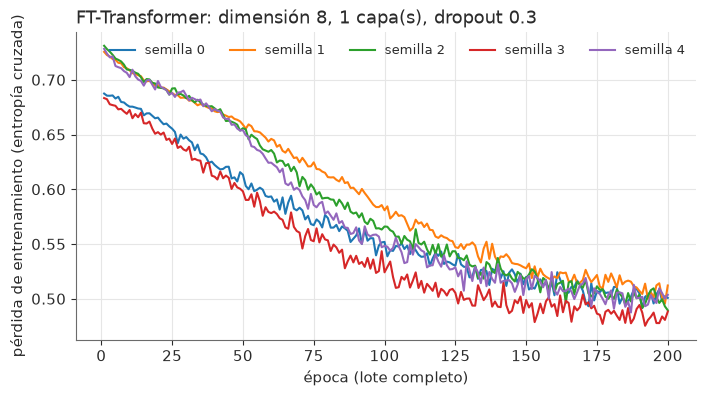

In [50]:
fig, ax = plt.subplots(figsize = (8, 4))
for semilla, curva in zip(SEMILLAS_MLP, curvas_ft):
    ax.plot(range(1, EPOCAS_FT + 1), curva, label = f'semilla {semilla}')
ax.set_xlabel('época (lote completo)')
ax.set_ylabel('pérdida de entrenamiento (entropía cruzada)')
ax.set_title(f'FT-Transformer: dimensión {config_ft["dimension"]}, {config_ft["capas"]} capa(s), dropout {config_ft["dropout"]}')
ax.legend(ncol = 5, fontsize = 9)
guardar(fig, '10_1_beto_ft_perdida')
plt.show()

**Tabla 10.4.** El FT-Transformer en el test, con las mismas métricas, IC95 y comparaciones pareadas que los demás sistemas.

In [51]:
prob_test[NOMBRE_FT] = probs_ft_test.mean(axis = 0)
predicciones[NOMBRE_FT] = clases(prob_test[NOMBRE_FT])
pred_cv[NOMBRE_FT] = clases(prob_cv[NOMBRE_FT])
boot[NOMBRE_FT] = f1_bootstrap(predicciones[NOMBRE_FT])
cv_de[NOMBRE_FT] = ft_por_fold['FT-Transformer'].mean()
salida[f'prob {NOMBRE_FT}'] = np.round(prob_test[NOMBRE_FT], 4)
salida[NOMBRE_FT] = predicciones[NOMBRE_FT]
guardar_csv(salida, 'predicciones_test_beto')
display(tabla_test([NOMBRE_FT, 'LR texto (principal)', '6. Stacking LR (4 bases + longitud)', '7. Stacking MLP (4 bases + longitud)']))
filas = []
for referencia in ['LR texto (principal)', '7. Stacking MLP (4 bases + longitud)', '6. Stacking LR (4 bases + longitud)']:
    filas.append(comparar(NOMBRE_FT, referencia))
pd.DataFrame(filas)

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,F1_fake en CV,predichas Fake
sistema,,,,,,,,,
FT-Transformer (exploratorio),0.7551,0.7787,0.7669,0.7675,0.7977,0.7168,"[0.713, 0.795]",0.714,257
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",0.730,193
6. Stacking LR (4 bases + longitud),0.7566,0.7869,0.7717,0.7727,0.8145,0.7063,"[0.712, 0.796]",0.708,248
7. Stacking MLP (4 bases + longitud),0.7364,0.7685,0.7525,0.7535,0.7912,0.6888,"[0.692, 0.776]",0.723,249


,sistema,referencia,diferencia F1 fake,IC95 pareado,remuestreos en que gana,McNemar (solo a / solo b),p McNemar
0,FT-Transformer (exploratorio),LR texto (principal),0.079,"[+0.038, +0.119]",1000 de 1000,55 / 33,0.025
1,FT-Transformer (exploratorio),7. Stacking MLP (4 bases + longitud),0.019,"[-0.003, +0.041]",953 de 1000,20 / 12,0.215
2,FT-Transformer (exploratorio),6. Stacking LR (4 bases + longitud),-0.001,"[-0.018, +0.015]",427 de 1000,8 / 11,0.648


**Figura 10.2.** Matrices de confusión del FT-Transformer: en CV (esquema B) y en el test.

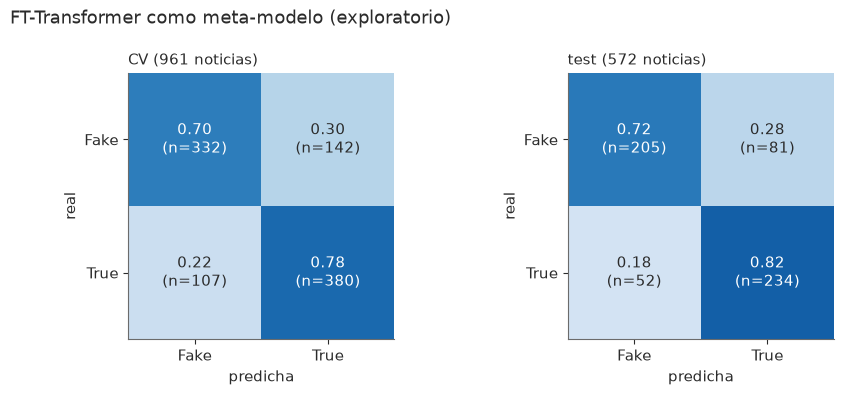

In [52]:
fig, ejes = plt.subplots(1, 2, figsize = (9, 4))
dibujar_matriz(ejes[0], y, pred_cv[NOMBRE_FT], 'CV (961 noticias)')
dibujar_matriz(ejes[1], y_test, predicciones[NOMBRE_FT], 'test (572 noticias)')
fig.suptitle('FT-Transformer como meta-modelo (exploratorio)', x = 0.01, ha = 'left', fontsize = 13)
fig.tight_layout()
guardar(fig, '10_2_beto_ft_matrices')
plt.show()

**Qué se observa.**

* **El *grid* elige el FT-Transformer más chico:** dimensión 8, 1 capa y *dropout* 0.3, con 713 parámetros para 730 a 782 filas de entrenamiento por fold. La mejor media (0.7382) era la de dimensión 16 con 2 capas, que tiene 4,673 parámetros; el *grid* va de 0.7144 a 0.7382, dentro de un SE.
* **En CV no le gana a nadie con claridad:** 0.7144 ± 0.0916, contra 0.7298 de la LR (−0.0154 ± 0.1476, aunque gana en 4 de 5 folds), −0.0086 contra la MLP del sistema 7 y +0.0066 contra la LR del sistema 6. La pérdida baja sin llegar a cero (Figura 10.1): con 713 parámetros y *dropout* no memoriza, pero tampoco aprende algo que la LR no capture.
* **En el test empata con el sistema 6:** 0.7551 [0.713, 0.795], −0.001 frente a él (IC [−0.018, +0.015]) y +0.019 frente a la MLP del sistema 7 (IC [−0.003, +0.041]). Le gana al principal (+0.079, IC [+0.038, +0.119], McNemar p = 0.025), igual que los stackings con BETO.
* **Costo:** 25.9 min de cómputo, contra segundos para el meta-modelo LR.

**Se confirma la hipótesis previa: el transformer como meta-modelo no supera a la LR ni a la MLP en CV, y en el test hace lo mismo que la LR del sistema 6. El transformer ya está donde sirve (BETO lee el texto); el meta-modelo debe ser simple (Wolpert, 1992; lámina 24). Queda como exploratorio, no como sistema final.**

<a id="seccion-11"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 11: Boostings con distintas vistas de la noticia (exploratorio)</span></div>

> **Qué se hace:** probamos si un grupo de boostings puede ser una base nueva para el meta-modelo. Primero revisamos si basta con cambiar la semilla para que cada boosting se equivoque distinto (11.1). Luego comparamos XGBoost, AdaBoost y HistGradientBoosting en tres vistas de la noticia: caracteres, rasgos de estilo y palabras + estilo (11.2). Al final metemos el mejor de cada vista al meta-modelo junto con la LR y BETO (11.3). **Es una exploración propuesta después de ver los resultados de las secciones anteriores: no es candidato a sistema final.**
>
> **Qué se espera ver:** que las semillas casi no cambien nada (el boosting reduce sesgo de forma casi determinista) y que lo que dé diversidad sea la vista, no la semilla. Un stacking con boostings solo valdría la pena si en CV supera al sistema 3.

#### Glosario de la sección
* **AdaBoost** (Freund y Schapire, 1997): boosting que entrena árboles de un solo corte (*stumps*) en secuencia; cada uno le da más peso a las noticias que los anteriores clasificaron mal (lámina 15).
* **HistGradientBoosting:** gradient boosting de scikit-learn que agrupa cada variable en 255 intervalos antes de buscar cortes; es la misma idea de LightGBM.
* **Vista:** la forma en que el modelo ve la noticia. *Caracteres* son n-gramas de 2 a 5 letras (≈ 15 mil columnas); *estilo* son los 10 rasgos de `modelo_arboles.ipynb` (longitud, mayúsculas, puntuación…); *palabras + estilo* son n-gramas de 1 a 2 palabras más los 10 rasgos.

**Regla fijada antes de correr esta sección:** el stacking de la 11.3 solo se evalúa en el test si su F1 media en CV (esquema B) supera a la del sistema 3. Si no, se reporta solo en CV. **Qué pasó:** no la superó, y el 27 de noviembre el equipo decidió evaluarlo en el test de todos modos, **solo como dato descriptivo**. Por eso su nombre dice "fuera de la regla": su número del test no puede usarse para elegirlo.

**Configuraciones fijas** (sin *grid search*, por costo): XGBoost con la configuración de `ensamble_stacking.ipynb` (profundidad 2, *learning rate* 0.05, 200 árboles, submuestreo 0.8 de filas y 0.5 de columnas); AdaBoost con 300 *stumps* y *learning rate* 0.5; HistGradientBoosting con profundidad 3, *learning rate* 0.05 y 200 iteraciones, **sin *early stopping*** (su validación interna sería aleatoria y rompería la regla 1). El mejor de cada vista se elige por la mayor F1 media en CV, sin anidar esa elección (igual que los hiperparámetros de XGBoost).

In [53]:
NOMBRE_BOOST = 'Stacking LR + BETO + 3 boostings (exploratorio, fuera de la regla)'
VISTAS_BOOST = ['caracteres', 'estilo', 'palabras + estilo']
BOOSTINGS = ['XGBoost', 'AdaBoost', 'HistGradientBoosting']

def representacion_vista(vista):
    '''
    Función que crea la representación de una vista de la noticia para los boostings

    inputs:
    --------
        vista (str): 'caracteres', 'estilo', 'palabras' o 'palabras + estilo'

    outputs:
    --------
        sklearn transformer: Transformador que recibe el DataFrame preparado
    '''
    if vista == 'estilo':
        return ColumnTransformer([('estilo', 'passthrough', uf.RASGOS_ESTILO)])
    if vista == 'caracteres':
        return uf.crear_representacion('caracteres (2,5)', 'solo texto', sin_medio = True, min_df = 20, minusculas = True)
    return uf.crear_representacion('palabras (1,2)', 'solo texto', sin_medio = True, min_df = 20, minusculas = True,
                                   estilo = (vista == 'palabras + estilo'))

def a_denso(X):
    '''
    Función que convierte una matriz dispersa en densa (HistGradientBoosting no acepta matrices dispersas)

    inputs:
    --------
        X (scipy.sparse matrix o numpy.ndarray): Matriz de entrada

    outputs:
    --------
        numpy.ndarray: Matriz densa
    '''
    if hasattr(X, 'toarray'):
        return X.toarray()
    return np.asarray(X)

def construir_boosting(nombre, vista, semilla = SEMILLA):
    '''
    Función que construye el Pipeline de un boosting sobre una vista

    inputs:
    --------
        nombre (str): 'XGBoost', 'AdaBoost' o 'HistGradientBoosting'
        vista (str): Vista de la noticia (ver representacion_vista)
        semilla (int): Semilla del modelo

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar; se entrena con y numérica (1 = Fake)
    '''
    if nombre == 'XGBoost':
        modelo = XGBClassifier(max_depth = 2, learning_rate = 0.05, n_estimators = 200, subsample = 0.8, colsample_bytree = 0.5,
                               tree_method = 'hist', n_jobs = N_NUCLEOS, random_state = semilla)
        return Pipeline([('representacion', representacion_vista(vista)), ('clasificador', modelo)])
    if nombre == 'AdaBoost':
        modelo = AdaBoostClassifier(DecisionTreeClassifier(max_depth = 1), n_estimators = 300, learning_rate = 0.5, random_state = semilla)
        return Pipeline([('representacion', representacion_vista(vista)), ('clasificador', modelo)])
    modelo = HistGradientBoostingClassifier(max_depth = 3, learning_rate = 0.05, max_iter = 200, early_stopping = False, random_state = semilla)
    return Pipeline([('representacion', representacion_vista(vista)), ('denso', FunctionTransformer(a_denso, accept_sparse = True)),
                     ('clasificador', modelo)])

def out_of_fold_boosting(nombre, vista, semilla = SEMILLA):
    '''
    Función que calcula la probabilidad out-of-fold de un boosting en los 5 folds agrupados

    inputs:
    --------
        nombre (str): 'XGBoost', 'AdaBoost' o 'HistGradientBoosting'
        vista (str): Vista de la noticia
        semilla (int): Semilla del modelo

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake de las 961 noticias
    '''
    prob = np.zeros(len(corpus))
    for k in range(5):
        en_k = folds == k
        modelo = construir_boosting(nombre, vista, semilla).fit(corpus[~en_k], y_num[~en_k])
        prob[en_k] = modelo.predict_proba(corpus[en_k])[:, 1]
    return prob

def f1_folds(prob):
    '''
    Función que calcula la F1 de fake de cada fold con el umbral 0.5

    inputs:
    --------
        prob (numpy.ndarray): Probabilidad de fake de las 961 noticias

    outputs:
    --------
        list: F1 de fake de los folds 0 a 4
    '''
    valores = []
    for k in range(5):
        valores.append(uf.f1_fake(y[folds == k], clases(prob[folds == k])))
    return valores

### 11.1 ¿Basta con cambiar la semilla?

La idea original era un puñado de boostings iguales con semillas distintas, para que cada uno se equivocara diferente. Lo probamos con palabras (la vista del XGBoost de las bases): 5 semillas de XGBoost y 3 de AdaBoost.

**Tabla 11.1.** F1 de fake en CV de cada semilla y del promedio de semillas.

In [54]:
inicio = time.time()
prob_semillas = {}
for semilla in [0, 1, 2, 3, 4]:
    prob_semillas[f'XGBoost, semilla {semilla}'] = out_of_fold_boosting('XGBoost', 'palabras', semilla)
for semilla in [0, 1, 2]:
    prob_semillas[f'AdaBoost, semilla {semilla}'] = out_of_fold_boosting('AdaBoost', 'palabras', semilla)
semillas = pd.DataFrame(prob_semillas)
promedio_xgb = semillas[['XGBoost, semilla 0', 'XGBoost, semilla 1', 'XGBoost, semilla 2', 'XGBoost, semilla 3', 'XGBoost, semilla 4']].mean(axis = 1).values
filas = []
for nombre in semillas.columns:
    filas.append({'modelo': nombre, 'F1_fake_media': np.mean(f1_folds(semillas[nombre].values))})
filas.append({'modelo': 'XGBoost, promedio de 5 semillas', 'F1_fake_media': np.mean(f1_folds(promedio_xgb))})
print(f'Listo en {(time.time() - inicio) / 60:.1f} min')
pd.DataFrame(filas).round(4)

Listo en 1.7 min


,modelo,F1_fake_media
0,"XGBoost, semilla 0",0.6904
1,"XGBoost, semilla 1",0.6916
2,"XGBoost, semilla 2",0.6879
3,"XGBoost, semilla 3",0.6949
4,"XGBoost, semilla 4",0.6665
5,"AdaBoost, semilla 0",0.6879
6,"AdaBoost, semilla 1",0.6879
7,"AdaBoost, semilla 2",0.6879
8,"XGBoost, promedio de 5 semillas",0.6883


**Tabla 11.2.** Correlación de Spearman entre semillas (y con la LR y BETO).

In [55]:
semillas['LR texto'] = Z['LR texto'].values
semillas['BETO'] = Z['BETO'].values
semillas.corr(method = 'spearman').round(3)

,"XGBoost, semilla 0","XGBoost, semilla 1","XGBoost, semilla 2","XGBoost, semilla 3","XGBoost, semilla 4","AdaBoost, semilla 0","AdaBoost, semilla 1","AdaBoost, semilla 2",LR texto,BETO
"XGBoost, semilla 0",1.000,0.978,0.977,0.978,0.977,0.913,0.913,0.913,0.803,0.608
"XGBoost, semilla 1",0.978,1.000,0.978,0.978,0.976,0.908,0.908,0.908,0.789,0.603
"XGBoost, semilla 2",0.977,0.978,1.000,0.978,0.978,0.908,0.908,0.908,0.797,0.605
"XGBoost, semilla 3",0.978,0.978,0.978,1.000,0.977,0.911,0.911,0.911,0.797,0.603
"XGBoost, semilla 4",0.977,0.976,0.978,0.977,1.000,0.914,0.914,0.914,0.791,0.609
"AdaBoost, semilla 0",0.913,0.908,0.908,0.911,0.914,1.000,1.000,1.000,0.784,0.604
"AdaBoost, semilla 1",0.913,0.908,0.908,0.911,0.914,1.000,1.000,1.000,0.784,0.604
"AdaBoost, semilla 2",0.913,0.908,0.908,0.911,0.914,1.000,1.000,1.000,0.784,0.604
LR texto,0.803,0.789,0.797,0.797,0.791,0.784,0.784,0.784,1.000,0.674
BETO,0.608,0.603,0.605,0.603,0.609,0.604,0.604,0.604,0.674,1.000


**Qué se observa.**

* **Cambiar la semilla casi no cambia a XGBoost.** Las 5 semillas dan de 0.6665 a 0.6949 y ordenan las noticias casi igual (Spearman 0.976 a 0.978). La semilla solo decide qué filas y columnas ve cada árbol; el boosting corrige el error de forma casi determinista. El promedio de las 5 (0.6883) no le gana a la mayoría de las semillas solas.
* **En AdaBoost, la semilla no cambia nada.** Las 3 dan exactamente 0.6879 y Spearman 1.000: con árboles de un solo corte y sin submuestreo, no hay nada aleatorio que la semilla pueda mover.
* **Todos se parecen a la LR** (Spearman 0.784 a 0.803), igual que el XGBoost de las bases.

**Un puñado de boostings que solo cambian de semilla es, en la práctica, un solo modelo: para que se equivoquen distinto hay que cambiar lo que ven, no la semilla.**

### 11.2 Tres boostings × tres vistas

Cada boosting se entrena con la misma semilla (42) sobre cada vista. Para cada uno reportamos su F1 por fold, qué tanto se parece a la LR y a BETO y cuántas falsas largas detecta (el punto débil de la LR).

**Tabla 11.3.** Los 9 boostings en CV agrupada: F1 de fake por fold, media y sd, Spearman con la LR y con BETO, y falsas del cuartil más largo detectadas.

In [56]:
inicio = time.time()
prob_boost = {}
filas = []
es_q4_falsa = (cuartil_cv == CUARTILES[3]).values & (y == 'Fake')
for vista in VISTAS_BOOST:
    for nombre in BOOSTINGS:
        prob = out_of_fold_boosting(nombre, vista)
        prob_boost[(vista, nombre)] = prob
        valores = f1_folds(prob)
        fila = {'vista': vista, 'boosting': nombre}
        for k in range(5):
            fila[f'fold {k}'] = valores[k]
        fila['F1_fake_media'] = np.mean(valores)
        fila['F1_fake_sd'] = np.std(valores, ddof = 1)
        fila['Spearman con LR'] = stats.spearmanr(prob, Z['LR texto']).correlation
        fila['Spearman con BETO'] = stats.spearmanr(prob, Z['BETO']).correlation
        fila['falsas Q4 detectadas (%)'] = 100 * np.mean(clases(prob)[es_q4_falsa] == 'Fake')
        filas.append(fila)
tabla_boost = pd.DataFrame(filas)
print(f'9 boostings × 5 folds en {(time.time() - inicio) / 60:.1f} min')
tabla_boost.round(4)

9 boostings × 5 folds en 9.7 min


,vista,boosting,fold 0,fold 1,fold 2,fold 3,fold 4,F1_fake_media,F1_fake_sd,Spearman con LR,Spearman con BETO,falsas Q4 detectadas (%)
0,caracteres,XGBoost,0.7984,0.5395,0.7042,0.6460,0.7456,0.6867,0.0995,0.8141,0.6592,25.8065
1,caracteres,AdaBoost,0.6923,0.6386,0.6901,0.6456,0.7186,0.6770,0.0339,0.8041,0.6570,37.0968
2,caracteres,HistGradientBoosting,0.7581,0.5949,0.7222,0.6503,0.7349,0.6921,0.0676,0.8033,0.6519,30.6452
3,estilo,XGBoost,0.6301,0.5065,0.7059,0.6310,0.7108,0.6369,0.0826,0.6917,0.5679,19.3548
4,estilo,AdaBoost,0.6578,0.3946,0.6887,0.6071,0.7574,0.6211,0.1379,0.6565,0.5361,16.1290
5,estilo,HistGradientBoosting,0.5981,0.5032,0.6883,0.6341,0.7305,0.6309,0.0875,0.6457,0.5433,22.5806
6,palabras + estilo,XGBoost,0.7193,0.4832,0.7125,0.6000,0.6829,0.6396,0.0995,0.7923,0.6203,24.1935
7,palabras + estilo,AdaBoost,0.7355,0.5526,0.7273,0.5939,0.6864,0.6592,0.0819,0.7687,0.6143,30.6452
8,palabras + estilo,HistGradientBoosting,0.7288,0.6545,0.7097,0.5988,0.7037,0.6791,0.0526,0.7934,0.6215,43.5484


**Tabla 11.4.** El mejor boosting de cada vista (mayor F1 media en CV) y Spearman entre los tres ganadores, la LR y BETO.

In [57]:
mejores_boost = {}
columnas_boost = []
for vista in VISTAS_BOOST:
    sub = tabla_boost[tabla_boost['vista'] == vista]
    mejor = sub.loc[sub['F1_fake_media'].idxmax()]
    mejores_boost[vista] = mejor['boosting']
    columna = f'{mejor["boosting"]} ({vista})'
    M[columna] = prob_boost[(vista, mejor['boosting'])]
    columnas_boost.append(columna)
    print(f'{vista}: gana {mejor["boosting"]} con {mejor["F1_fake_media"]:.4f}')
M[['LR texto', 'BETO'] + columnas_boost].corr(method = 'spearman').round(3)

caracteres: gana HistGradientBoosting con 0.6921
estilo: gana XGBoost con 0.6369
palabras + estilo: gana HistGradientBoosting con 0.6791


,LR texto,BETO,HistGradientBoosting (caracteres),XGBoost (estilo),HistGradientBoosting (palabras + estilo)
LR texto,1.000,0.674,0.803,0.692,0.793
BETO,0.674,1.000,0.652,0.568,0.622
HistGradientBoosting (caracteres),0.803,0.652,1.000,0.725,0.764
XGBoost (estilo),0.692,0.568,0.725,1.000,0.757
HistGradientBoosting (palabras + estilo),0.793,0.622,0.764,0.757,1.000


**Qué se observa.**

* **El mejor boosting depende de la vista** (Tabla 11.3):
  * en caracteres gana HistGradientBoosting (0.6921), seguido de XGBoost (0.6867) y AdaBoost (0.6770);
  * en estilo gana XGBoost (0.6369), con HistGradientBoosting (0.6309) y AdaBoost (0.6211) detrás;
  * en palabras + estilo gana HistGradientBoosting (0.6791), por encima de AdaBoost (0.6592) y XGBoost (0.6396).
* **Ninguno se acerca a la LR (0.7298).** El mejor, HistGradientBoosting con caracteres, queda apenas arriba del XGBoost de las bases (0.6855).
* **La vista sí cambia la diversidad, pero con un costo.** Con caracteres, los boostings se parecen a la LR tanto como el XGBoost viejo (Spearman de 0.80 a 0.81). Con estilo son los más distintos (0.65 a 0.69), pero también los más débiles. Entre los tres ganadores, el Spearman va de 0.725 a 0.764: ahora sí se equivocan distinto entre ellos.
* **Falsas largas:** el HistGradientBoosting de palabras + estilo detecta el 43.5 % del cuartil más largo; es el boosting que más se acerca a la LR (48.4 %).
* AdaBoost con caracteres es el más estable entre folds (sd 0.0339) y el que mejor aguanta el fold de la sátira (0.6386).

**Variar la vista da boostings más distintos entre sí que variar la semilla, pero todos quedan por debajo de la LR, y los de texto se le siguen pareciendo.**

### 11.3 Stacking LR + BETO + los 3 boostings ganadores

Mismo meta-modelo que el sistema 3 (regresión logística, `C` elegida por *grid search* con `PredefinedSplit`), ahora con 5 entradas: la LR, BETO y los tres boostings ganadores. Se estima con el esquema B.

**Tabla 11.5.** F1 de fake por fold (esquema B) del stacking con boostings, frente a la LR y al sistema 3; pesos del meta-modelo entrenado con todo el *out-of-fold*.

In [58]:
entradas_boost = ['LR texto', 'BETO'] + columnas_boost
SISTEMAS_META[NOMBRE_BOOST] = {'entradas': entradas_boost, 'meta': 'LR', 'escalar': False}
meta, c_elegida, tabla = ajustar_meta_lr(M[entradas_boost].values, y_num, folds, False)
metas_finales[NOMBRE_BOOST] = meta
eleccion_meta[NOMBRE_BOOST] = {'C': c_elegida}
prob, estabilidad_boost, grids_b = esquema_b_lr(entradas_boost, False)
prob_cv[NOMBRE_BOOST] = prob
pred_cv[NOMBRE_BOOST] = clases(prob)
f1_boost = f1_folds(prob)
cv_de[NOMBRE_BOOST] = np.mean(f1_boost)

comparacion = pd.DataFrame({'fold': range(5), 'stacking con boostings': f1_boost,
                            'LR texto (principal)': f1_cv.loc['LR texto (principal)'].iloc[:5].values,
                            '3. Stacking LR (LR + BETO)': f1_cv.loc['3. Stacking LR (LR + BETO)'].iloc[:5].values})
comparacion['− sistema 3'] = comparacion['stacking con boostings'] - comparacion['3. Stacking LR (LR + BETO)']
resumen = comparacion.drop(columns = 'fold').agg(['mean', 'std'])
resumen.insert(0, 'fold', ['media', 'sd'])
display(pd.concat([comparacion, resumen], ignore_index = True).round(4))
print(f'C elegida con todo el out-of-fold: {c_elegida}; gana al sistema 3 en {int((comparacion["− sistema 3"] > 0).sum())} de 5 folds')
pesos = pd.DataFrame({'peso': list(meta['meta'].coef_[0]) + [meta['meta'].intercept_[0]]}, index = entradas_boost + ['intercepto'])
display(pesos.round(3))
guardar_csv(tabla_boost.merge(pd.DataFrame({'vista': VISTAS_BOOST, 'elegido': [mejores_boost[v] for v in VISTAS_BOOST]}), on = 'vista'), 'beto_exploratorio_boosting')
estabilidad_boost.round(3)

,fold,stacking con boostings,LR texto (principal),3. Stacking LR (LR + BETO),− sistema 3
0,0,0.8409,0.7848,0.8110,0.0299
1,1,0.6069,0.8541,0.6842,-0.0773
2,2,0.7662,0.6345,0.7722,-0.0059
3,3,0.6582,0.6375,0.6923,-0.0341
4,4,0.7907,0.7381,0.7719,0.0188
5,media,0.7326,0.7298,0.7463,-0.0137
6,sd,0.0969,0.0951,0.0554,0.0432


C elegida con todo el out-of-fold: 1.0; gana al sistema 3 en 2 de 5 folds


,peso
LR texto,2.930
BETO,2.356
HistGradientBoosting (caracteres),1.309
XGBoost (estilo),-0.260
HistGradientBoosting (palabras + estilo),0.282
intercepto,-2.570


,fold externo,C elegida,peso LR texto,peso BETO,peso HistGradientBoosting (caracteres),peso XGBoost (estilo),peso HistGradientBoosting (palabras + estilo),intercepto
0,0,1.0,2.715,2.426,1.226,-0.154,-0.147,-2.267
1,1,10.0,1.041,2.734,1.949,0.114,-0.246,-2.140
2,2,10.0,5.559,2.435,0.892,-0.942,-0.086,-3.183
3,3,0.1,1.069,1.584,1.113,0.456,0.875,-2.008
4,4,1.0,3.165,2.181,1.287,-0.326,0.494,-2.629


**Tabla 11.6.** La regla fijada antes de correr la sección y su resultado. El stacking con boostings se evalúa en el test fuera de la regla, como dato descriptivo, con las demás exploraciones en la Sección 13.1; aquí se preparan sus probabilidades del test.

In [59]:
f1_sistema3 = f1_cv.loc['3. Stacking LR (LR + BETO)', 'media']
pasa_regla = cv_de[NOMBRE_BOOST] > f1_sistema3
print(f'Stacking con boostings en CV: {cv_de[NOMBRE_BOOST]:.4f}; sistema 3: {f1_sistema3:.4f}; ¿pasa la regla? {"sí" if pasa_regla else "no"}')
print('Se evalúa en el test de todos modos, como dato descriptivo (decisión del equipo, 27-nov), en la Sección 13.1.')
for vista, columna in zip(VISTAS_BOOST, columnas_boost):
    modelo = construir_boosting(mejores_boost[vista], vista).fit(corpus, y_num)
    M_test[columna] = modelo.predict_proba(test)[:, 1]
prob_test[NOMBRE_BOOST] = prob_meta(NOMBRE_BOOST, M_test[entradas_boost].values)
predicciones[NOMBRE_BOOST] = clases(prob_test[NOMBRE_BOOST])
boot[NOMBRE_BOOST] = f1_bootstrap(predicciones[NOMBRE_BOOST])
salida[f'prob {NOMBRE_BOOST}'] = np.round(prob_test[NOMBRE_BOOST], 4)
print(f'Probabilidades del test listas para {len(columnas_boost)} boostings y el meta-modelo.')

Stacking con boostings en CV: 0.7326; sistema 3: 0.7463; ¿pasa la regla? no
Se evalúa en el test de todos modos, como dato descriptivo (decisión del equipo, 27-nov), en la Sección 13.1.


Probabilidades del test listas para 3 boostings y el meta-modelo.


**Figura 11.1.** Matriz de confusión en CV (esquema B) del stacking con boostings, junto a la del sistema 3.

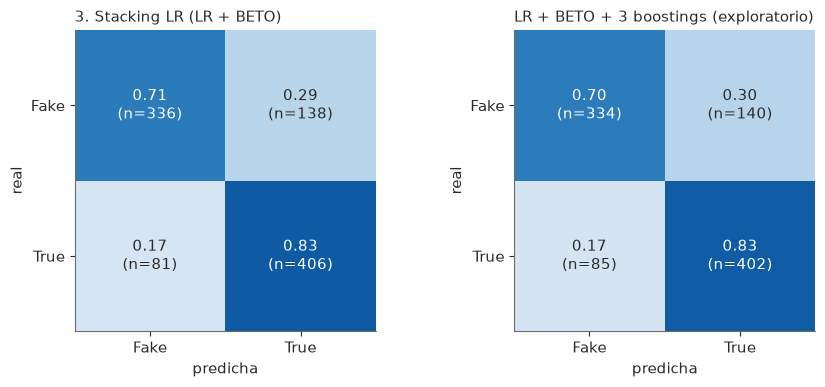

In [60]:
fig, ejes = plt.subplots(1, 2, figsize = (9, 4))
dibujar_matriz(ejes[0], y, pred_cv['3. Stacking LR (LR + BETO)'], '3. Stacking LR (LR + BETO)')
dibujar_matriz(ejes[1], y, pred_cv[NOMBRE_BOOST], 'LR + BETO + 3 boostings (exploratorio)')
fig.tight_layout()
guardar(fig, '11_1_beto_boosting_matrices_cv')
plt.show()

**Qué se observa.**

* **El stacking con boostings no supera al sistema 3:** 0.7326 ± 0.0969 contra 0.7463 ± 0.0554 en CV (−0.0137 en promedio). Solo le gana en 2 de 5 folds y pierde sobre todo en el de la sátira (0.6069 contra 0.6842).
* **No pasa la regla fijada antes de correr la sección.** Por decisión del equipo (27-nov), se evalúa en el test de todos modos, como dato descriptivo, en la pasada única de la Sección 13.1, con la etiqueta "fuera de la regla". Ese número no sirve para elegirlo.
* **El meta-modelo casi no los usa.** Con todo el *out-of-fold* (`C` = 1), los pesos quedan así: LR 2.930, BETO 2.356, HistGradientBoosting de caracteres 1.309, XGBoost de estilo −0.260 y HistGradientBoosting de palabras + estilo 0.282.
* **Los pesos de los boostings no son estables.** Entre folds externos, el del XGBoost de estilo cambia de signo (−0.942 a 0.456) y el del HistGradientBoosting de palabras + estilo también (−0.246 a 0.875). Es el mismo patrón de inestabilidad que se vio con las bases débiles en la Sección 4.

**Agregar boostings al stacking LR + BETO no ayuda: lo que ya cubren la LR (palabras y caracteres) y BETO (contexto) no lo mejoran modelos de árboles que leen la noticia con las mismas palabras. Se confirma la lámina 24: agregar complejidad solo si mejora la validación, y aquí no la mejora.**

<a id="seccion-12"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 12: Bases nuevas que leen la noticia de otra forma (exploratorio)</span></div>

> **Qué se hace:** agregamos cinco bases que podrían equivocarse distinto que la LR: un SVM con kernel RBF y un kNN sobre los *embeddings* de BETO sin ajustar, y un Naive Bayes sobre palabras (12.1), y dos transformers más, BERTIN y XLM-RoBERTa, entrenados con el mismo protocolo que BETO (12.2). Después medimos qué tan distintas son (12.3). **Exploración propuesta después de ver los resultados del test de las secciones anteriores: no es candidata a sistema final.**
>
> **Qué se espera ver:** que el SVM y el kNN sobre *embeddings* queden por debajo de la LR pero se le parezcan poco, y que los dos transformers se parezcan más a BETO que a la LR.

#### Glosario de la sección
* ***Embedding* de BETO sin ajustar:** para cada noticia, el promedio de los 768 números que BETO preentrenado le asigna a cada *token* (`beto_embeddings.py`). No usa etiquetas, así que es una representación del texto como el TF-IDF, pero densa y basada en el significado.
* **SVM con kernel RBF:** busca la frontera con más margen entre clases; el kernel RBF permite fronteras curvas midiendo la similitud entre noticias. En TF-IDF (miles de columnas dispersas) se comporta casi como uno lineal; en 768 dimensiones densas sí aprovecha la curvatura. Su probabilidad sale de un ajuste de Platt (`CalibratedClassifierCV` con una CV interna de 5 partes) **solo con las filas de entrenamiento**.
* **kNN:** clasifica cada noticia según sus k vecinas más parecidas (similitud coseno) del entrenamiento. Es un sesgo muy distinto al de la LR: no aprende pesos, solo compara.
* **Naive Bayes (Complement NB):** modelo **generativo**: estima qué tan frecuente es cada palabra en cada clase y combina esas frecuencias suponiendo que las palabras son independientes. La variante *Complement* (Rennie et al., 2003) estima cada clase con las noticias de la otra y funciona mejor en texto. Se agregó el 27 de noviembre a petición del equipo, antes de ver los resultados de BERTIN y XLM-RoBERTa.
* **BERTIN** (De la Rosa et al., 2022): RoBERTa entrenado solo con español de mC4; otro corpus y otro tokenizador que BETO.
* **XLM-RoBERTa** (Conneau et al., 2020): RoBERTa multilingüe (100 idiomas, CommonCrawl). Por su vocabulario de 250 mil *tokens*, se entrenó con la tabla de *embeddings* de palabras **congelada** para caber en 4 GB; todo lo demás se ajusta igual que en BETO.

**Por qué no MarIA.** Era el candidato original (RoBERTa entrenado con la Biblioteca Nacional de España), pero el 27 de noviembre de 2026 su repositorio oficial (`PlanTL-GOB-ES/roberta-base-bne`) ya no tenía los pesos, y las copias disponibles son de terceros sin forma de verificarlas.

**Elección de hiperparámetros:** `C` del SVM en {0.1, 1, 10, 100}, k del kNN en {5, 15, 31, 61} y `alpha` (suavizado) del Naive Bayes en {0.1, 0.3, 1, 3, 10}, por la mayor F1 media en CV agrupada (sin anidar, igual que las demás bases). Los transformers no tienen *grid*.

### 12.1 SVM-RBF y kNN sobre *embeddings* de BETO sin ajustar, y Naive Bayes sobre palabras

In [61]:
EMBEDDINGS = np.load(os.path.join(uf.RUTA_RESULTADOS, 'beto_embeddings.npz'))
emb_corpus = pd.DataFrame(EMBEDDINGS['X_corpus'], index = EMBEDDINGS['ids_corpus']).loc[corpus['id_unico']].values
emb_test = pd.DataFrame(EMBEDDINGS['X_test'], index = EMBEDDINGS['ids_test']).loc[test['id_unico']].values
REJILLA_SVM = [0.1, 1, 10, 100]
REJILLA_KNN = [5, 15, 31, 61]
REJILLA_NB = [0.1, 0.3, 1, 3, 10]
COLUMNA_BASE = {'SVM-RBF': 'SVM-RBF (embeddings)', 'kNN': 'kNN (embeddings)', 'Naive Bayes': 'Naive Bayes (palabras)'}
print(f'Embeddings: corpus {emb_corpus.shape}, test {emb_test.shape}')

def construir_svm(c):
    '''
    Función que construye el SVM con kernel RBF sobre embeddings estandarizados

    inputs:
    --------
        c (float): Penalización del SVM

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar
    '''
    return Pipeline([('escala', StandardScaler()),
                     ('svm', CalibratedClassifierCV(SVC(kernel = 'rbf', C = c, gamma = 'scale'), ensemble = False))])

def construir_knn(k):
    '''
    Función que construye el kNN con similitud coseno

    inputs:
    --------
        k (int): Número de vecinas

    outputs:
    --------
        sklearn.neighbors.KNeighborsClassifier: Modelo sin entrenar
    '''
    return KNeighborsClassifier(n_neighbors = k, metric = 'cosine', algorithm = 'brute')

def construir_nb(alpha):
    '''
    Función que construye el Naive Bayes (Complement) sobre TF-IDF de palabras

    inputs:
    --------
        alpha (float): Suavizado de las frecuencias

    outputs:
    --------
        sklearn.pipeline.Pipeline: Pipeline sin entrenar
    '''
    representacion = uf.crear_representacion('palabras (1,2)', 'solo texto', sin_medio = True, min_df = 20, minusculas = True)
    return Pipeline([('representacion', representacion), ('nb', ComplementNB(alpha = alpha))])

def out_of_fold_entrada(construir, valor, X):
    '''
    Función que calcula la probabilidad out-of-fold de un modelo sobre una entrada (embeddings o noticias)

    inputs:
    --------
        construir (function): construir_svm, construir_knn o construir_nb
        valor (float o int): Hiperparámetro del modelo
        X (numpy.ndarray o pandas.DataFrame): emb_corpus o corpus, en el orden de corpus

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake de las 961 noticias
    '''
    prob = np.zeros(len(corpus))
    for k in range(5):
        en_k = folds == k
        modelo = construir(valor).fit(X[~en_k], y_num[~en_k])
        prob[en_k] = modelo.predict_proba(X[en_k])[:, 1]
    return prob

inicio = time.time()
prob_emb = {}
filas = []
MODELOS_121 = [('SVM-RBF', construir_svm, REJILLA_SVM, 'C', emb_corpus), ('kNN', construir_knn, REJILLA_KNN, 'k', emb_corpus),
               ('Naive Bayes', construir_nb, REJILLA_NB, 'alpha', corpus)]
for nombre, construir, rejilla, parametro, X in MODELOS_121:
    for valor in rejilla:
        prob = out_of_fold_entrada(construir, valor, X)
        prob_emb[(nombre, valor)] = prob
        valores = f1_folds(prob)
        fila = {'modelo': nombre, 'hiperparámetro': f'{parametro} = {valor}'}
        for k in range(5):
            fila[f'fold {k}'] = valores[k]
        fila['F1_fake_media'] = np.mean(valores)
        fila['F1_fake_sd'] = np.std(valores, ddof = 1)
        filas.append(fila)
grid_emb = pd.DataFrame(filas)
print(f'Grid de SVM, kNN y Naive Bayes en {time.time() - inicio:.0f} s')

Embeddings: corpus (961, 768), test (572, 768)


Grid de SVM, kNN y Naive Bayes en 17 s


**Tabla 12.1.** *Grid* del SVM-RBF y del kNN sobre *embeddings*, y del Naive Bayes sobre palabras (F1 de fake por fold en CV agrupada).

In [62]:
eleccion_emb = {}
for nombre, construir, rejilla, parametro, X in MODELOS_121:
    sub = grid_emb[grid_emb['modelo'] == nombre]
    mejor = sub.loc[sub['F1_fake_media'].idxmax()]
    valor = rejilla[list(sub.index).index(mejor.name)]
    eleccion_emb[nombre] = valor
    M[COLUMNA_BASE[nombre]] = prob_emb[(nombre, valor)]
    print(f'{nombre}: elegido {mejor["hiperparámetro"]} con {mejor["F1_fake_media"]:.4f}')
grid_emb.round(4)

SVM-RBF: elegido C = 100 con 0.6719
kNN: elegido k = 31 con 0.5593
Naive Bayes: elegido alpha = 3 con 0.6734


,modelo,hiperparámetro,fold 0,fold 1,fold 2,fold 3,fold 4,F1_fake_media,F1_fake_sd
0,SVM-RBF,C = 0.1,0.8168,0.4045,0.5775,0.6519,0.7027,0.6307,0.1535
1,SVM-RBF,C = 1,0.6415,0.5109,0.7075,0.6792,0.7647,0.6608,0.0951
2,SVM-RBF,C = 10,0.5962,0.5507,0.7347,0.6875,0.7784,0.6695,0.0948
3,SVM-RBF,C = 100,0.5962,0.5507,0.7347,0.6875,0.7904,0.6719,0.0983
4,kNN,k = 5,0.5905,0.3944,0.5693,0.5767,0.5786,0.5419,0.0828
5,kNN,k = 15,0.5962,0.4521,0.5612,0.5432,0.5443,0.5394,0.0533
6,kNN,k = 31,0.6393,0.4681,0.5342,0.5818,0.5732,0.5593,0.0633
7,kNN,k = 61,0.7319,0.4648,0.5417,0.5349,0.5185,0.5584,0.1016
8,Naive Bayes,alpha = 0.1,0.7210,0.8776,0.5442,0.5677,0.6093,0.6640,0.1374
9,Naive Bayes,alpha = 0.3,0.7479,0.8844,0.5298,0.5641,0.6203,0.6693,0.1461


### 12.2 Dos transformers más: BERTIN y XLM-RoBERTa

**Tabla 12.2.** Verificaciones de los archivos de BERTIN y XLM-RoBERTa (mismas que las de BETO).

In [63]:
TRANSFORMERS_EXTRA = {'BERTIN': 'bertin', 'XLM-RoBERTa': 'xlmr'}
prob_test_extra = {}
logs_extra = {}
semillas_extra = {}
verificaciones_extra = []
for nombre, prefijo in TRANSFORMERS_EXTRA.items():
    oof = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, f'{prefijo}_oof.csv'))
    prueba = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, f'{prefijo}_test.csv'))
    logs_extra[nombre] = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, f'{prefijo}_log.csv'), dtype = {'fold': str})
    alineado = oof.set_index('id_unico').loc[corpus['id_unico']]
    M[nombre] = alineado[f'prob_{prefijo}'].values
    semillas_extra[nombre] = alineado
    prob_test_extra[nombre] = prueba.set_index('id_unico').loc[test['id_unico'], f'prob_{prefijo}'].values
    n_nan = int(oof.isna().sum().sum() + prueba.isna().sum().sum())
    ok = (len(oof) == 961 and len(prueba) == 572 and set(oof['id_unico']) == set(corpus['id_unico'])
          and set(prueba['id_unico']) == set(test['id_unico']) and n_nan == 0 and len(logs_extra[nombre]) == 18)
    verificaciones_extra.append(fila_verificacion(f'{nombre}: 961 y 572 filas, mismos ids, sin NaN, 18 entrenamientos', 'sí',
                                                  f'{len(oof)}, {len(prueba)}, NaN {n_nan}, bitácora {len(logs_extra[nombre])}', marca(ok)))
verificaciones = verificaciones + verificaciones_extra
pd.DataFrame(verificaciones_extra)

,verificación,esperado,obtenido,estado
0,"BERTIN: 961 y 572 filas, mismos ids, sin NaN, ...",sí,"961, 572, NaN 0, bitácora 18",✅
1,"XLM-RoBERTa: 961 y 572 filas, mismos ids, sin ...",sí,"961, 572, NaN 0, bitácora 18",✅


**Tabla 12.3.** F1 de fake por fold de los tres transformers (promedio de 3 semillas), la diferencia máxima entre semillas y el costo de entrenamiento.

In [64]:
filas = []
for k in range(5):
    en_k = folds == k
    fila = {'fold': k, 'LR texto': f1_por_fold['LR texto'][k], 'BETO': f1_por_fold['BETO'][k]}
    for nombre in TRANSFORMERS_EXTRA:
        fila[nombre] = uf.f1_fake(y[en_k], clases(M.loc[en_k, nombre]))
        valores = []
        for semilla in SEMILLAS_BETO:
            valores.append(uf.f1_fake(y[en_k], clases(semillas_extra[nombre][f'prob_s{semilla}'].values[en_k])))
        fila[f'{nombre}: máx − mín entre semillas'] = max(valores) - min(valores)
    filas.append(fila)
tabla = pd.DataFrame(filas)
resumen = tabla.drop(columns = 'fold').agg(['mean', 'std'])
resumen.insert(0, 'fold', ['media', 'sd'])
for nombre in TRANSFORMERS_EXTRA:
    log = logs_extra[nombre]
    print(f'{nombre}: {log["minutos"].sum():.0f} min de GPU; memoria máxima {log["memoria_max_gb"].max():.2f} GB; '
          f'pérdida de la última época de {log["perdida_final"].min():.3f} a {log["perdida_final"].max():.3f}')
pd.concat([tabla, resumen], ignore_index = True).round(4)

BERTIN: 68 min de GPU; memoria máxima 2.36 GB; pérdida de la última época de 0.027 a 0.185
XLM-RoBERTa: 70 min de GPU; memoria máxima 2.37 GB; pérdida de la última época de 0.243 a 0.456


,fold,LR texto,BETO,BERTIN,BERTIN: máx − mín entre semillas,XLM-RoBERTa,XLM-RoBERTa: máx − mín entre semillas
0,0,0.7848,0.7328,0.7971,0.0368,0.4868,0.0974
1,1,0.8541,0.3130,0.9340,0.0459,0.5833,0.1941
2,2,0.6345,0.7651,0.7919,0.0671,0.7260,0.0847
3,3,0.6375,0.6767,0.7571,0.0333,0.6316,0.0561
4,4,0.7381,0.7919,0.7692,0.0569,0.7651,0.0538
5,media,0.7298,0.6559,0.8099,0.0480,0.6386,0.0972
6,sd,0.0951,0.1964,0.0713,0.0141,0.1116,0.0573


### 12.3 ¿Se equivocan distinto?

**Tabla 12.4.** Correlación de Spearman entre todas las bases candidatas (*out-of-fold*).

In [65]:
BASES_NUEVAS = ['SVM-RBF (embeddings)', 'kNN (embeddings)', 'Naive Bayes (palabras)', 'BERTIN', 'XLM-RoBERTa']
TODAS_BASES = BASES + columnas_boost + BASES_NUEVAS
M[TODAS_BASES].corr(method = 'spearman').round(3)

,LR texto,XGBoost,RF estilo,BETO,HistGradientBoosting (caracteres),XGBoost (estilo),HistGradientBoosting (palabras + estilo),SVM-RBF (embeddings),kNN (embeddings),Naive Bayes (palabras),BERTIN,XLM-RoBERTa
LR texto,1.000,0.801,0.678,0.674,0.803,0.692,0.793,0.687,0.567,0.867,0.617,0.774
XGBoost,0.801,1.000,0.692,0.609,0.769,0.685,0.897,0.609,0.538,0.638,0.517,0.687
RF estilo,0.678,0.692,1.000,0.550,0.711,0.913,0.733,0.575,0.591,0.532,0.426,0.659
BETO,0.674,0.609,0.550,1.000,0.652,0.568,0.622,0.762,0.472,0.519,0.792,0.819
HistGradientBoosting (caracteres),0.803,0.769,0.711,0.652,1.000,0.725,0.764,0.664,0.553,0.591,0.573,0.702
XGBoost (estilo),0.692,0.685,0.913,0.568,0.725,1.000,0.757,0.595,0.551,0.532,0.468,0.671
HistGradientBoosting (palabras + estilo),0.793,0.897,0.733,0.622,0.764,0.757,1.000,0.622,0.530,0.636,0.531,0.702
SVM-RBF (embeddings),0.687,0.609,0.575,0.762,0.664,0.595,0.622,1.000,0.664,0.523,0.605,0.729
kNN (embeddings),0.567,0.538,0.591,0.472,0.553,0.551,0.530,0.664,1.000,0.464,0.343,0.512
Naive Bayes (palabras),0.867,0.638,0.532,0.519,0.591,0.532,0.636,0.523,0.464,1.000,0.509,0.659


**Tabla 12.5.** F1 de fake en CV, aciertos que solo tiene cada base nueva frente a la LR y BETO, y falsas largas detectadas.

In [66]:
acierta_lr = clases(M['LR texto']) == y
acierta_beto = clases(M['BETO']) == y
filas = []
for nombre in ['LR texto', 'BETO'] + BASES_NUEVAS:
    acierta = clases(M[nombre]) == y
    filas.append({'base': nombre, 'F1_fake_media': np.mean(f1_folds(M[nombre].values)),
                  'aciertos que no tienen ni la LR ni BETO': int((acierta & ~acierta_lr & ~acierta_beto).sum()),
                  'falsas Q4 detectadas (%)': 100 * np.mean(clases(M[nombre])[es_q4_falsa] == 'Fake')})
oraculo_3 = (acierta_lr | acierta_beto).mean()
oraculo_todas = (acierta_lr | acierta_beto)
for nombre in BASES_NUEVAS:
    oraculo_todas = oraculo_todas | (clases(M[nombre]) == y)
print(f'Exactitud del oráculo LR + BETO: {oraculo_3:.3f}; con las 4 bases nuevas: {oraculo_todas.mean():.3f}')
pd.DataFrame(filas).round(4)

Exactitud del oráculo LR + BETO: 0.871; con las 4 bases nuevas: 0.943


,base,F1_fake_media,aciertos que no tienen ni la LR ni BETO,falsas Q4 detectadas (%)
0,LR texto,0.7298,0,48.3871
1,BETO,0.6559,0,16.1290
2,SVM-RBF (embeddings),0.6719,19,27.4194
3,kNN (embeddings),0.5593,18,9.6774
4,Naive Bayes (palabras),0.6734,27,70.9677
5,BERTIN,0.8099,50,74.1935
6,XLM-RoBERTa,0.6386,11,41.9355


**Qué se observa.**

* **SVM y kNN sobre *embeddings* (Tabla 12.1).**
  * El SVM-RBF llega a 0.6719 (`C` = 100, prácticamente empatado con `C` = 10, 0.6695): queda abajo de la LR, pero a la par de XGBoost.
  * El kNN es la base más débil (0.5593). k = 31 y k = 61 empatan (0.5593 contra 0.5584), así que la elección de k casi no importa. Con *embeddings* sin ajustar, las vecinas más parecidas suelen ser del mismo **tema**, y en cada tema hay falsas y verdaderas.
* **Naive Bayes es el más parecido a la LR** (Spearman 0.867, Tabla 12.4) y el más inestable entre folds: 0.8812 en el fold de la sátira y 0.5455 en el fold 2 con `alpha` = 3 (0.6734 de media).
* **BERTIN es, por mucho, la mejor base del proyecto:** 0.8099 ± 0.0713 en CV, contra 0.7298 de la LR.
  * Gana en 4 de 5 folds y sus semillas difieren a lo más 0.0671.
  * En el fold de la sátira saca 0.9340, donde BETO sacaba 0.3130: detecta el 98.9 % de las falsas de *El Ruinaversal* (Tabla 12.9).
* **XLM-RoBERTa queda abajo** (0.6386 ± 0.1116), con semillas inestables en el fold de la sátira (0.1941). Su tabla de *embeddings* congelada le quitó capacidad: su pérdida final (0.243 a 0.456) no baja como la de BERTIN (0.027 a 0.185).
* **Diversidad (Tablas 12.4 y 12.5).**
  * BERTIN se parece poco a la LR (0.617) y bastante a BETO (0.792).
  * Con las cinco bases nuevas, el oráculo sube de 0.871 (LR + BETO) a 0.943.
  * BERTIN acierta sola 50 noticias que fallan la LR y BETO.
  * En falsas largas detectadas, BERTIN (74.2 %) y Naive Bayes (71.0 %) superan a la LR (48.4 %).

**BERTIN es la primera base que supera claramente a la LR en CV, y lo hace justo donde BETO fallaba. Antes de creerle hay que revisar si conocía esos textos (12.4).**

### 12.4 ¿Vieron los transformers estas noticias al preentrenarse? (prueba de contaminación)

BERTIN se preentrenó con mC4, un rastreo masivo de páginas web en español hecho alrededor de 2020, y XLM-RoBERTa con CC-100, otro rastreo web. Si esos rastreos incluyeron páginas de los medios del corpus (en especial *El Ruinaversal*), el modelo podría estar **reconociendo textos que ya vio** en lugar de aprender a detectar falsedad. Eso no es fuga de etiquetas (nunca vio "esta noticia es falsa"), pero sí **contaminación**: el desempeño en CV sería optimista para noticias de esos sitios.

**Prueba 1: adivinar palabras tapadas** (`contaminacion_mlm.py`). A cada modelo **preentrenado, sin ajuste fino**, le tapamos el 15 % de los *tokens* de cada noticia (mismas posiciones al azar con semilla fija, mismo truncado cabeza + cola) y medimos su acierto top-1 en esos *tokens*. Un texto memorizado se completa anormalmente bien. Como cada modelo tiene su propio tokenizador y su propio nivel base, comparamos con **diferencia en diferencias**: la ventaja de BERTIN (o XLM-R) sobre BETO en cada grupo, menos esa misma ventaja en el test (2021, posterior a los rastreos). BETO sirve de referencia porque su corpus (Wikipedia, OPUS y otros) tiene pocas páginas de noticias. Si la ventaja crece mucho justo en *El Ruinaversal*, es señal de contaminación.

**Prueba 2: búsqueda directa** (`contaminacion_busqueda.py`). En la muestra de mC4 con la que se preentrenó BERTIN (`bertin-project/mc4-es-sampled`, configuración `gaussian`) buscamos, con el buscador público de Hugging Face, el dominio web de las 5 fuentes de falsas y las 5 de verdaderas con más noticias (por ejemplo `elruinaversal` o `eluniversal`). El buscador no busca frases exactas, sino palabras sueltas; por eso no basta con el número de resultados: contamos cuántos de los primeros 100 resultados tienen una URL **de ese mismo dominio** (`eluniversal.com.mx`, no el Universal de otro país). El buscador indexa solo una parte del conjunto (se reporta), así que un 0 no prueba que el sitio no esté.

**Qué se puede concluir y qué no.** Ninguna de las dos pruebas es definitiva: un estilo muy peculiar también se adivina bien, y no encontrar el sitio en un índice parcial no prueba que no esté. Si las dos apuntan al mismo lado, la conclusión es más fuerte.

**Tabla 12.6.** Acierto top-1 (%) al adivinar el 15 % de *tokens* tapados, por grupo de noticias y modelo preentrenado (sin ajuste fino), con su error estándar.

In [67]:
contaminacion = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'contaminacion_mlm.csv'))
fuentes_corpus = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'folds.csv'))
fuentes_corpus = fuentes_corpus[fuentes_corpus['particion'] != 'test'].set_index('id_unico')
grupo_corpus = {}
for id_unico, fuente, clase in zip(corpus['id_unico'], fuentes_corpus.loc[corpus['id_unico'], 'fuente'], y):
    if fuente == 'el ruinaversal':
        grupo_corpus[id_unico] = 'falsas de El Ruinaversal'
    elif clase == 'Fake':
        grupo_corpus[id_unico] = 'otras falsas del corpus'
    else:
        grupo_corpus[id_unico] = 'verdaderas del corpus'
GRUPOS = ['falsas de El Ruinaversal', 'otras falsas del corpus', 'verdaderas del corpus', 'test (2021)']
contaminacion['grupo'] = contaminacion['id_unico'].map(grupo_corpus).fillna('test (2021)')
contaminacion['acierto (%)'] = 100 * contaminacion['acierto_top1']
media = contaminacion.pivot_table(index = 'grupo', columns = 'modelo', values = 'acierto (%)', aggfunc = 'mean').loc[GRUPOS]
error = contaminacion.pivot_table(index = 'grupo', columns = 'modelo', values = 'acierto (%)', aggfunc = 'sem').loc[GRUPOS]
n_grupo = contaminacion[contaminacion['modelo'] == 'BETO'].groupby('grupo').size().loc[GRUPOS]
tabla = media.round(1).astype(str) + ' ± ' + error.round(1).astype(str)
tabla['noticias'] = n_grupo.values
tabla

modelo,BERTIN,BETO,XLM-RoBERTa,noticias
grupo,,,,
falsas de El Ruinaversal,68.6 ± 0.7,43.8 ± 0.7,66.4 ± 0.7,93
otras falsas del corpus,68.6 ± 0.5,43.4 ± 0.5,66.1 ± 0.4,381
verdaderas del corpus,73.4 ± 0.4,44.1 ± 0.4,70.0 ± 0.4,487
test (2021),69.7 ± 0.3,43.7 ± 0.4,68.1 ± 0.4,572


**Tabla 12.7.** Diferencia en diferencias: ventaja de cada modelo sobre BETO en cada grupo, menos su ventaja en el test, con IC95 bootstrap (1,000 remuestreos de noticias dentro de cada grupo, semilla 42). Un valor grande y positivo en un grupo del corpus es señal de que el modelo vio esos textos.

In [68]:
def ventaja_sobre_beto(datos, modelo):
    '''
    Función que calcula, por noticia, el acierto del modelo menos el de BETO

    inputs:
    --------
        datos (pandas.DataFrame): Filas de contaminacion_mlm.csv
        modelo (str): 'BERTIN' o 'XLM-RoBERTa'

    outputs:
    --------
        pandas.Series: Ventaja por id_unico (en puntos porcentuales)
    '''
    a = datos[datos['modelo'] == modelo].set_index('id_unico')['acierto (%)']
    b = datos[datos['modelo'] == 'BETO'].set_index('id_unico')['acierto (%)']
    return a - b.loc[a.index]

rng_cont = np.random.default_rng(SEMILLA)
filas = []
for modelo in ['BERTIN', 'XLM-RoBERTa']:
    ventaja = ventaja_sobre_beto(contaminacion, modelo)
    grupo = contaminacion.drop_duplicates('id_unico').set_index('id_unico').loc[ventaja.index, 'grupo']
    en_test = ventaja[grupo == 'test (2021)'].values
    for nombre_grupo in GRUPOS[:3]:
        en_grupo = ventaja[grupo == nombre_grupo].values
        remuestreos = []
        for r in range(N_BOOTSTRAP):
            remuestreos.append(rng_cont.choice(en_grupo, len(en_grupo)).mean() - rng_cont.choice(en_test, len(en_test)).mean())
        filas.append({'modelo': modelo, 'grupo': nombre_grupo, 'ventaja sobre BETO en el grupo': en_grupo.mean(),
                      'ventaja sobre BETO en el test': en_test.mean(), 'diferencia en diferencias': en_grupo.mean() - en_test.mean(),
                      'IC95': f'[{np.percentile(remuestreos, 2.5):+.1f}, {np.percentile(remuestreos, 97.5):+.1f}]'})
dif_en_dif = pd.DataFrame(filas)
dif_en_dif.round(2)

,modelo,grupo,ventaja sobre BETO en el grupo,ventaja sobre BETO en el test,diferencia en diferencias,IC95
0,BERTIN,falsas de El Ruinaversal,24.76,25.96,-1.20,"[-3.3, +0.9]"
1,BERTIN,otras falsas del corpus,25.23,25.96,-0.73,"[-2.3, +0.7]"
2,BERTIN,verdaderas del corpus,29.30,25.96,3.35,"[+2.0, +4.7]"
3,XLM-RoBERTa,falsas de El Ruinaversal,22.50,24.36,-1.86,"[-4.0, +0.2]"
4,XLM-RoBERTa,otras falsas del corpus,22.75,24.36,-1.61,"[-3.2, -0.1]"
5,XLM-RoBERTa,verdaderas del corpus,25.92,24.36,1.56,"[+0.2, +2.9]"


**Figura 12.1.** Acierto top-1 al adivinar *tokens* tapados, por grupo y modelo preentrenado. Las barras de error son ±2 errores estándar.

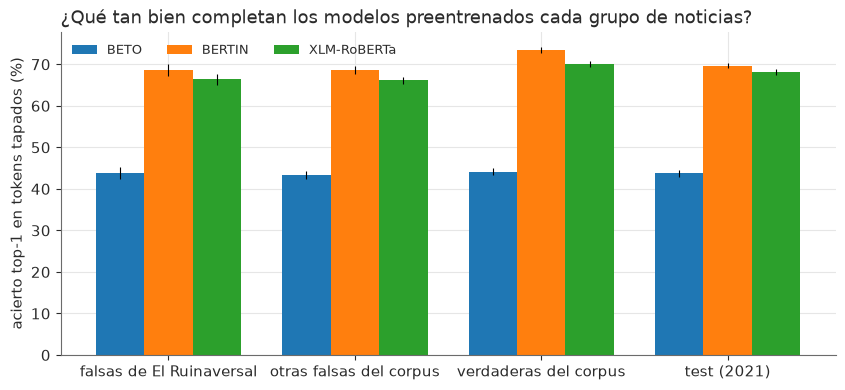

In [69]:
fig, ax = plt.subplots(figsize = (10, 4.2))
ancho = 0.26
x = np.arange(len(GRUPOS))
for i, modelo in enumerate(['BETO', 'BERTIN', 'XLM-RoBERTa']):
    ax.bar(x + (i - 1) * ancho, media.loc[GRUPOS, modelo], ancho, yerr = 2 * error.loc[GRUPOS, modelo], label = modelo, error_kw = {'lw': 0.8})
ax.set_xticks(x, GRUPOS)
ax.set_ylabel('acierto top-1 en tokens tapados (%)')
ax.set_title('¿Qué tan bien completan los modelos preentrenados cada grupo de noticias?')
ax.legend(ncol = 3, fontsize = 9)
guardar(fig, '12_1_beto_contaminacion')
plt.show()

**Tabla 12.8.** Búsqueda directa en la muestra de mC4 de BERTIN (`contaminacion_busqueda.py`; buscador público de Hugging Face): a) páginas de cada dominio entre los primeros 100 resultados; b) noticias del corpus encontradas con su URL exacta; c) control positivo del método de b).

In [70]:
busqueda = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'contaminacion_busqueda.csv'))
busqueda_noticias = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'contaminacion_busqueda_noticias.csv'))
busqueda_control = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'contaminacion_busqueda_control.csv'))
print('a) Por dominio: ¿hay páginas del sitio en la muestra de mC4 de BERTIN?')
display(busqueda[['fuente', 'dominio', 'clase en el corpus', 'noticias en el corpus', 'resultados de la búsqueda',
                  'páginas del dominio (primeros 100)', 'índice parcial']])
print('b) Noticia por noticia: ¿están las mismas noticias del corpus? (se buscan las palabras de su URL y se compara la URL exacta)')
display(pd.crosstab(busqueda_noticias['fuente'], busqueda_noticias['en mC4 (BERTIN)'], margins = True, margins_name = 'total'))
print('c) Control positivo: páginas que sí están en mC4, buscadas con el mismo método de b)')
busqueda_control

a) Por dominio: ¿hay páginas del sitio en la muestra de mC4 de BERTIN?


,fuente,dominio,clase en el corpus,noticias en el corpus,resultados de la búsqueda,páginas del dominio (primeros 100),índice parcial
0,el dizque,eldizque.com,Fake,134,6,6,True
1,el ruinaversal,elruinaversal.com,Fake,93,2,2,True
2,hay noticia,haynoticia.es,Fake,38,19,18,True
3,censura 0,censura0.com,Fake,36,8433,1,True
4,la voz popular,lavozpopular.com,Fake,24,1,0,True
5,el país,elpais.com,True,74,6752,43,True
6,el universal,eluniversal.com.mx,True,68,2484,52,True
7,excelsior,excelsior.com.mx,True,45,989,2,True
8,forbes,forbes.com.mx,True,33,2016,33,True
9,huffpost,huffingtonpost.com.mx,True,25,758,7,True


b) Noticia por noticia: ¿están las mismas noticias del corpus? (se buscan las palabras de su URL y se compara la URL exacta)


en mC4 (BERTIN),no encontrada,sin palabras en la URL,total
fuente,,,
el dizque,134,0,134
el ruinaversal,93,0,93
el universal,68,1,69
forbes,33,0,33
hay noticia,38,0,38
total,366,1,367


c) Control positivo: páginas que sí están en mC4, buscadas con el mismo método de b)


,fuente,url (página que sí está en mC4),resultado del método noticia por noticia
0,el dizque,https://www.eldizque.com/por-austeridad-republ...,encontrada
1,el ruinaversal,https://elruinaversal.com/2018/02/16/epn-propo...,encontrada
2,hay noticia,https://haynoticia.es/jubilado-despierta-anest...,encontrada
3,el universal,http://archivo.eluniversal.com.mx/espectaculos...,sin palabras en la URL
4,forbes,https://www.forbes.com.mx/forbes-life/rosalia-...,encontrada


**Tabla 12.9.** Para comparar: falsas de *El Ruinaversal* que detecta cada transformer ya ajustado (en CV, *out-of-fold*) y su F1 en el test.

In [71]:
es_ruinaversal = np.array([grupo_corpus[i] == 'falsas de El Ruinaversal' for i in corpus['id_unico']])
filas = []
for nombre in ['BETO', 'BERTIN', 'XLM-RoBERTa']:
    filas.append({'transformer': nombre,
                  'falsas de El Ruinaversal detectadas en CV (%)': 100 * np.mean(clases(M.loc[es_ruinaversal, nombre]) == 'Fake'),
                  'otras falsas detectadas en CV (%)': 100 * np.mean(clases(M.loc[~es_ruinaversal & (y == 'Fake'), nombre]) == 'Fake'),
                  'F1 de fake en CV': np.mean(f1_folds(M[nombre].values))})
pd.DataFrame(filas).round(3)

,transformer,falsas de El Ruinaversal detectadas en CV (%),otras falsas detectadas en CV (%),F1 de fake en CV
0,BETO,19.355,64.567,0.656
1,BERTIN,98.925,74.016,0.810
2,XLM-RoBERTa,45.161,51.969,0.639


**Qué se observa.**

* **Los modelos no completan mejor la sátira que el test (Tablas 12.6 y 12.7).**
  * BERTIN completa el 68.6 % de los *tokens* tapados de *El Ruinaversal* y el 69.7 % del test (2021). BETO queda plano en todos los grupos (43.4 % a 44.1 %).
  * La diferencia en diferencias de BERTIN para *El Ruinaversal* es −1.20 puntos (IC95 [−3.3, +0.9]); para las otras falsas, −0.73 [−2.3, +0.7]. **No hay señal de que BERTIN haya memorizado las noticias falsas del corpus.** XLM-RoBERTa da lo mismo (−1.86 [−4.0, +0.2]).
* **Sí hay una señal en las verdaderas:** BERTIN completa las verdaderas del corpus 3.35 puntos mejor de lo esperado (IC95 [+2.0, +4.7]) y XLM-RoBERTa 1.56 [+0.2, +2.9]. Las verdaderas vienen de medios grandes (El Universal, El País, Forbes), cuyo estilo está muy presente en la web.
* **La búsqueda directa (Tabla 12.8) cuadra con eso:**
  * Los **sitios** sí están en la muestra de mC4 de BERTIN: hay páginas de *El Ruinaversal*, *El Dizque* y *Hay Noticia*, y decenas de El Universal, El País y Forbes.
  * Pero **ninguna de las noticias concretas del corpus** que se buscaron aparece con su URL exacta, y el método sí encuentra las páginas del control positivo.
  * El índice es parcial: un "no encontrada" no prueba que no esté.
* **Lo que no cuadra es el test:** BERTIN pasa de 0.810 en CV a 0.7258 en el test (Sección 13.1), la caída más grande de todas las bases. Su exhaustividad sigue alta (0.7587), pero marca muchas verdaderas como falsas (precisión 0.6955).

**No hay evidencia de que BERTIN haya memorizado las noticias del corpus, pero sí de que conocía los sitios y su estilo. Eso, más la caída en el test, indica que su 0.810 en CV es optimista: parte de su ventaja es reconocer el registro de los medios del corpus (en especial la sátira), y eso no se transfiere a las noticias de 2021. Es una contaminación de estilo, no de etiquetas.**

<a id="seccion-13"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 13: Otros meta-modelos y umbral anidado (exploratorio)</span></div>

> **Qué se hace:** probamos cuatro sistemas más, fijados antes de verlos: (E1) el sistema 3 con su umbral elegido por CV anidada; (E2) stacking LR con la LR y los tres transformers; (E3) un meta-modelo con **pesos no negativos** sobre todas las bases; (E4) el E3 con umbral anidado. Al final se aplican **todos juntos al test en una sola pasada**, junto con las bases nuevas y el stacking con boostings de la Sección 11.
>
> **Qué se espera ver:** que el umbral anidado sume algo al sistema 3 (el umbral 0.34 y el sistema 3 empataron en el test porque mejoran cosas distintas) y que los pesos no negativos sean más estables entre folds que los de la LR libre.

#### Glosario de la sección
* **Pesos no negativos:** una regresión logística cuyos pesos solo pueden ser ≥ 0 (el intercepto es libre). Una base que no ayuda queda con peso 0 en lugar de recibir un peso negativo que absorbe ruido (lo que pasó con el bosque y los boostings). Se ajusta con `scipy.optimize.minimize` (L-BFGS-B con límites), con pesos de clase balanceados y regularización L2 con la misma rejilla de `C`.
* **Umbral anidado:** en lugar de cortar la probabilidad del stacking en 0.5, se elige el corte que maximiza la F1 de fake media **dentro de los folds de entrenamiento**, usando las predicciones del meta-modelo en esos folds (un esquema B interno). Se busca en 0.20, 0.21, …, 0.70; en empate, el más cercano a 0.5. Para el test, el umbral se elige con las 961 predicciones del esquema B, igual que el 0.34 de `umbral.ipynb`.

In [72]:
UMBRALES = np.round(np.arange(0.20, 0.705, 0.01), 2)

def ajustar_no_negativa_c(X, y_numerica, c):
    '''
    Función que ajusta una regresión logística con pesos no negativos, pesos de clase balanceados y L2

    inputs:
    --------
        X (numpy.ndarray): Entradas del meta-modelo
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        c (float): Inverso de la regularización (como el C de scikit-learn)

    outputs:
    --------
        dict: 'pesos' (numpy.ndarray) e 'intercepto' (float)
    '''
    n_fake = y_numerica.sum()
    n_true = len(y_numerica) - n_fake
    peso_fila = np.where(y_numerica == 1, len(y_numerica) / (2 * n_fake), len(y_numerica) / (2 * n_true))
    p = X.shape[1]

    def perdida(theta):
        z = X @ theta[:p] + theta[p]
        valor = c * np.sum(peso_fila * (y_numerica * np.logaddexp(0, -z) + (1 - y_numerica) * np.logaddexp(0, z))) + 0.5 * np.sum(theta[:p] ** 2)
        residuo = c * peso_fila * (1 / (1 + np.exp(-z)) - y_numerica)
        gradiente = np.concatenate([X.T @ residuo + theta[:p], [residuo.sum()]])
        return valor, gradiente

    limites = [(0, None)] * p + [(None, None)]
    resultado = minimize(perdida, np.zeros(p + 1), jac = True, method = 'L-BFGS-B', bounds = limites)
    return {'pesos': resultado.x[:p], 'intercepto': resultado.x[p]}

def prob_no_negativa(modelo, X):
    '''
    Función que calcula la probabilidad de fake con el meta-modelo de pesos no negativos

    inputs:
    --------
        modelo (dict): Salida de ajustar_no_negativa_c
        X (numpy.ndarray): Entradas

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake
    '''
    return 1 / (1 + np.exp(-(X @ modelo['pesos'] + modelo['intercepto'])))

def ajustar_meta_no_negativa(X, y_numerica, folds_entrenamiento):
    '''
    Función que elige C para el meta-modelo no negativo con los folds dados y lo entrena

    inputs:
    --------
        X (numpy.ndarray): Entradas del meta-modelo
        y_numerica (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila

    outputs:
    --------
        tuple: (meta-modelo entrenado, C elegida)
    '''
    mejor_c = None
    mejor_media = -1
    for c in REJILLA_META:
        valores = []
        for k in np.unique(folds_entrenamiento):
            en_k = folds_entrenamiento == k
            modelo = ajustar_no_negativa_c(X[~en_k], y_numerica[~en_k], c)
            valores.append(uf.f1_fake(etiquetas_texto(y_numerica[en_k]), clases(prob_no_negativa(modelo, X[en_k]))))
        if np.mean(valores) > mejor_media + 1e-12:
            mejor_media = np.mean(valores)
            mejor_c = c
    return ajustar_no_negativa_c(X, y_numerica, mejor_c), mejor_c

def predecir_meta_lr(X_entrenamiento, y_entrenamiento, folds_entrenamiento, X_prediccion):
    '''
    Función que elige y entrena el meta-modelo LR y predice otras filas

    inputs:
    --------
        X_entrenamiento (numpy.ndarray): Entradas de entrenamiento
        y_entrenamiento (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila de entrenamiento
        X_prediccion (numpy.ndarray): Entradas a predecir

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake
    '''
    meta, _, _ = ajustar_meta_lr(X_entrenamiento, y_entrenamiento, folds_entrenamiento, False)
    return meta.predict_proba(X_prediccion)[:, 1]

def predecir_meta_no_negativa(X_entrenamiento, y_entrenamiento, folds_entrenamiento, X_prediccion):
    '''
    Función que elige y entrena el meta-modelo no negativo y predice otras filas

    inputs:
    --------
        X_entrenamiento (numpy.ndarray): Entradas de entrenamiento
        y_entrenamiento (numpy.ndarray): 1 = Fake, 0 = True
        folds_entrenamiento (numpy.ndarray): Fold de cada fila de entrenamiento
        X_prediccion (numpy.ndarray): Entradas a predecir

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake
    '''
    modelo, _ = ajustar_meta_no_negativa(X_entrenamiento, y_entrenamiento, folds_entrenamiento)
    return prob_no_negativa(modelo, X_prediccion)

def esquema_b_filas(predecir, entradas, filas):
    '''
    Función que aplica el esquema B solo en las filas indicadas (cada fold de esas filas se predice sin verlo)

    inputs:
    --------
        predecir (function): predecir_meta_lr o predecir_meta_no_negativa
        entradas (list): Columnas de M
        filas (numpy.ndarray): Máscara booleana de las filas que participan

    outputs:
    --------
        numpy.ndarray: Probabilidad de fake en esas filas (NaN en las demás)
    '''
    prob = np.full(len(M), np.nan)
    for k in np.unique(folds[filas]):
        afuera = filas & (folds == k)
        dentro = filas & (folds != k)
        prob[afuera] = predecir(M.loc[dentro, entradas].values, y_num[dentro], folds[dentro], M.loc[afuera, entradas].values)
    return prob

def elegir_umbral(prob, y_real, folds_umbral):
    '''
    Función que elige el umbral que maximiza la F1 de fake media por fold (en empate, el más cercano a 0.5)

    inputs:
    --------
        prob (numpy.ndarray): Probabilidades de fake
        y_real (numpy.ndarray): Clases reales
        folds_umbral (numpy.ndarray): Fold de cada fila

    outputs:
    --------
        float: Umbral elegido
    '''
    mejor_umbral = 0.5
    mejor_media = -1
    for umbral in sorted(UMBRALES, key = lambda u: abs(u - 0.5)):
        valores = []
        for k in np.unique(folds_umbral):
            en_k = folds_umbral == k
            valores.append(uf.f1_fake(y_real[en_k], clases(prob[en_k], umbral)))
        if np.mean(valores) > mejor_media + 1e-12:
            mejor_media = np.mean(valores)
            mejor_umbral = float(umbral)
    return mejor_umbral

def umbral_anidado(predecir, entradas, prob_b):
    '''
    Función que aplica el umbral anidado: para cada fold externo, elige el umbral con un esquema B interno sin ese fold

    inputs:
    --------
        predecir (function): predecir_meta_lr o predecir_meta_no_negativa
        entradas (list): Columnas de M
        prob_b (numpy.ndarray): Probabilidades del esquema B del sistema (961 noticias)

    outputs:
    --------
        tuple: (clases predichas de las 961 noticias, lista de umbrales por fold externo)
    '''
    pred = np.empty(len(M), dtype = object)
    umbrales = []
    for k in range(5):
        dentro = folds != k
        prob_interna = esquema_b_filas(predecir, entradas, dentro)
        umbral = elegir_umbral(prob_interna[dentro], y[dentro], folds[dentro])
        umbrales.append(umbral)
        pred[folds == k] = clases(prob_b[folds == k], umbral)
    return pred.astype(str), umbrales

inicio = time.time()
ENTRADAS_3 = SISTEMAS_META['3. Stacking LR (LR + BETO)']['entradas']
ENTRADAS_E2 = ['LR texto', 'BETO', 'BERTIN', 'XLM-RoBERTa']
NOMBRES_EXTRA = {'E1': 'E1. Sistema 3 + umbral anidado (exploratorio)',
                 'E2': 'E2. Stacking LR (LR + 3 transformers) (exploratorio)',
                 'E3': 'E3. Stacking no negativo, todas las bases (exploratorio)',
                 'E4': 'E4. Stacking no negativo + umbral anidado (exploratorio)'}

# E1: sistema 3 con umbral anidado
pred_cv[NOMBRES_EXTRA['E1']], umbrales_e1 = umbral_anidado(predecir_meta_lr, ENTRADAS_3, prob_cv['3. Stacking LR (LR + BETO)'])
umbral_test_e1 = elegir_umbral(prob_cv['3. Stacking LR (LR + BETO)'], y, folds)

# E2: LR + 3 transformers, meta-modelo LR
prob_cv[NOMBRES_EXTRA['E2']] = esquema_b_filas(predecir_meta_lr, ENTRADAS_E2, np.ones(len(M), dtype = bool))
pred_cv[NOMBRES_EXTRA['E2']] = clases(prob_cv[NOMBRES_EXTRA['E2']])
meta_e2, c_e2, _ = ajustar_meta_lr(M[ENTRADAS_E2].values, y_num, folds, False)

# E3: pesos no negativos, todas las bases
prob_cv[NOMBRES_EXTRA['E3']] = esquema_b_filas(predecir_meta_no_negativa, TODAS_BASES, np.ones(len(M), dtype = bool))
pred_cv[NOMBRES_EXTRA['E3']] = clases(prob_cv[NOMBRES_EXTRA['E3']])
meta_e3, c_e3 = ajustar_meta_no_negativa(M[TODAS_BASES].values, y_num, folds)

# E4: E3 con umbral anidado
pred_cv[NOMBRES_EXTRA['E4']], umbrales_e4 = umbral_anidado(predecir_meta_no_negativa, TODAS_BASES, prob_cv[NOMBRES_EXTRA['E3']])
umbral_test_e4 = elegir_umbral(prob_cv[NOMBRES_EXTRA['E3']], y, folds)
print(f'Meta-modelos extra en {(time.time() - inicio) / 60:.1f} min')
print(f'Umbrales anidados por fold, E1: {umbrales_e1}; E4: {umbrales_e4}')
print(f'Umbral para el test, E1: {umbral_test_e1}; E4: {umbral_test_e4}; C de E2: {c_e2}; C de E3: {c_e3}')

Meta-modelos extra en 0.1 min
Umbrales anidados por fold, E1: [0.45, 0.46, 0.38, 0.33, 0.4]; E4: [0.45, 0.5, 0.46, 0.41, 0.49]
Umbral para el test, E1: 0.37; E4: 0.44; C de E2: 100.0; C de E3: 1


**Tabla 13.1.** F1 de fake por fold en CV de los cuatro sistemas extra, frente a la LR y al sistema 3, con la diferencia pareada contra el sistema 3.

In [73]:
filas = []
for nombre in ['LR texto (principal)', '3. Stacking LR (LR + BETO)'] + list(NOMBRES_EXTRA.values()):
    valores = []
    for k in range(5):
        valores.append(uf.f1_fake(y[folds == k], pred_cv[nombre][folds == k]))
    fila = {'sistema': nombre}
    for k in range(5):
        fila[f'fold {k}'] = valores[k]
    fila['media'] = np.mean(valores)
    fila['sd'] = np.std(valores, ddof = 1)
    filas.append(fila)
cv_extra = pd.DataFrame(filas).set_index('sistema')
base_3 = cv_extra.loc['3. Stacking LR (LR + BETO)'].iloc[:5].values
diferencias = []
ganados = []
for nombre in cv_extra.index:
    d = cv_extra.loc[nombre].iloc[:5].values - base_3
    diferencias.append(d.mean())
    ganados.append(int((d > 0).sum()))
cv_extra['− sistema 3 (media)'] = diferencias
cv_extra['folds en que gana al 3'] = ganados
for nombre in NOMBRES_EXTRA.values():
    cv_de[nombre] = cv_extra.loc[nombre, 'media']
cv_extra.round(4)

,fold 0,fold 1,fold 2,fold 3,fold 4,media,sd,− sistema 3 (media),folds en que gana al 3
sistema,,,,,,,,,
LR texto (principal),0.7848,0.8541,0.6345,0.6375,0.7381,0.7298,0.0951,-0.0165,1
3. Stacking LR (LR + BETO),0.8110,0.6842,0.7722,0.6923,0.7719,0.7463,0.0554,0.0000,0
E1. Sistema 3 + umbral anidado (exploratorio),0.8365,0.7134,0.7619,0.6593,0.7650,0.7472,0.0659,0.0009,2
E2. Stacking LR (LR + 3 transformers) (exploratorio),0.8043,0.8817,0.7785,0.7448,0.7826,0.7984,0.0512,0.0521,4
"E3. Stacking no negativo, todas las bases (exploratorio)",0.8201,0.9043,0.7922,0.7534,0.7879,0.8116,0.0570,0.0653,5
E4. Stacking no negativo + umbral anidado (exploratorio),0.8293,0.9043,0.8000,0.7436,0.7879,0.8130,0.0596,0.0667,5


**Figura 13.1.** Curva de F1 de fake (media por fold) del sistema 3 según el umbral, con las 961 predicciones del esquema B. La línea punteada es el 0.5, la sólida el umbral que se aplicará al test (el máximo de esta curva) y las marcas grises los umbrales elegidos en cada fold externo de la CV anidada, sin ver ese fold. Debajo, la estimación honesta fold por fold.

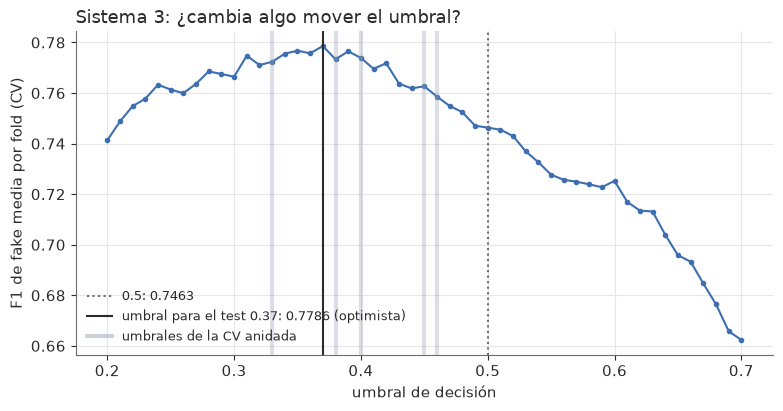

Media con 0.5: 0.7463; con umbral anidado: 0.7472; gana en 2 de 5 folds


,fold externo,umbral elegido sin ese fold,F1 con 0.5,F1 con umbral anidado,diferencia
0,0,0.45,0.8110,0.8365,0.0255
1,1,0.46,0.6842,0.7134,0.0292
2,2,0.38,0.7722,0.7619,-0.0102
3,3,0.33,0.6923,0.6593,-0.0330
4,4,0.40,0.7719,0.7650,-0.0069


In [74]:
def curva_umbral(prob, y_real, folds_umbral):
    '''
    Función que calcula la F1 de fake media por fold para cada umbral de UMBRALES

    inputs:
    --------
        prob (numpy.ndarray): Probabilidades de fake
        y_real (numpy.ndarray): Clases reales
        folds_umbral (numpy.ndarray): Fold de cada fila

    outputs:
    --------
        numpy.ndarray: F1 de fake media para cada umbral
    '''
    medias = []
    for umbral in UMBRALES:
        valores = []
        for k in np.unique(folds_umbral):
            en_k = folds_umbral == k
            valores.append(uf.f1_fake(y_real[en_k], clases(prob[en_k], umbral)))
        medias.append(np.mean(valores))
    return np.array(medias)

prob_3 = prob_cv['3. Stacking LR (LR + BETO)']
curva_3 = curva_umbral(prob_3, y, folds)
fig, ax = plt.subplots(figsize = (9, 4.2))
ax.plot(UMBRALES, curva_3, color = '#3D6FB0', marker = 'o', markersize = 3)
ax.axvline(0.5, color = TINTA_SUAVE, linestyle = ':', label = f'0.5: {curva_3[np.argmin(np.abs(UMBRALES - 0.5))]:.4f}')
ax.axvline(umbral_test_e1, color = TINTA, linestyle = '-', label = f'umbral para el test {umbral_test_e1}: {curva_3.max():.4f} (optimista)')
for umbral in umbrales_e1:
    ax.axvline(umbral, color = '#9aa5b1', linewidth = 3, alpha = 0.35)
ax.plot([], [], color = '#9aa5b1', linewidth = 3, alpha = 0.5, label = 'umbrales de la CV anidada')
ax.set_xlabel('umbral de decisión')
ax.set_ylabel('F1 de fake media por fold (CV)')
ax.set_title('Sistema 3: ¿cambia algo mover el umbral?')
ax.legend(fontsize = 9, loc = 'lower left')
guardar(fig, '13_1_beto_umbral_sistema3')
plt.show()

filas = []
for k in range(5):
    en_k = folds == k
    con_05 = uf.f1_fake(y[en_k], clases(prob_3[en_k]))
    con_anidado = uf.f1_fake(y[en_k], pred_cv[NOMBRES_EXTRA['E1']][en_k])
    filas.append({'fold externo': k, 'umbral elegido sin ese fold': umbrales_e1[k], 'F1 con 0.5': con_05,
                  'F1 con umbral anidado': con_anidado, 'diferencia': con_anidado - con_05})
anidado = pd.DataFrame(filas)
print(f'Media con 0.5: {anidado["F1 con 0.5"].mean():.4f}; con umbral anidado: {anidado["F1 con umbral anidado"].mean():.4f}; '
      f'gana en {int((anidado["diferencia"] > 0).sum())} de 5 folds')
anidado.round(4)

**Tabla 13.2.** Pesos del meta-modelo no negativo (E3) con todo el *out-of-fold* y en cada fold externo. Una base con peso 0 queda fuera.

In [75]:
columnas = {'todo el out-of-fold': meta_e3['pesos']}
for k in range(5):
    dentro = folds != k
    modelo_k, _ = ajustar_meta_no_negativa(M.loc[dentro, TODAS_BASES].values, y_num[dentro], folds[dentro])
    columnas[f'fold externo {k}'] = modelo_k['pesos']
pesos_e3 = pd.DataFrame(columnas, index = TODAS_BASES)
print(f'Bases con peso > 0.01 en todo el out-of-fold: {list(pesos_e3.index[pesos_e3["todo el out-of-fold"] > 0.01])}')
print('Pesos del meta-modelo LR de E2:', dict(zip(ENTRADAS_E2, np.round(meta_e2['meta'].coef_[0], 3))))
pesos_e3.round(3)

Bases con peso > 0.01 en todo el out-of-fold: ['LR texto', 'XGBoost', 'BETO', 'HistGradientBoosting (caracteres)', 'SVM-RBF (embeddings)', 'BERTIN']
Pesos del meta-modelo LR de E2: {'LR texto': np.float64(4.446), 'BETO': np.float64(1.429), 'BERTIN': np.float64(2.859), 'XLM-RoBERTa': np.float64(-0.936)}


,todo el out-of-fold,fold externo 0,fold externo 1,fold externo 2,fold externo 3,fold externo 4
LR texto,1.068,0.424,0.263,1.249,0.584,1.189
XGBoost,1.158,0.592,0.532,1.118,0.642,1.373
RF estilo,0.000,0.000,0.091,0.000,0.000,0.000
BETO,0.713,0.420,0.976,0.683,0.743,0.640
HistGradientBoosting (caracteres),0.884,0.771,0.742,0.794,0.683,0.781
XGBoost (estilo),0.000,0.059,0.300,0.000,0.251,0.000
HistGradientBoosting (palabras + estilo),0.000,0.000,0.222,0.000,0.512,0.000
SVM-RBF (embeddings),0.440,0.741,0.451,0.335,0.463,0.378
kNN (embeddings),0.000,0.000,0.000,0.000,0.000,0.000
Naive Bayes (palabras),0.003,0.000,0.000,0.842,0.374,0.017


### 13.1 Aplicación conjunta en el test (exploratorio)

Una sola pasada por el test para todo lo exploratorio de las Secciones 11 a 13. Las bases nuevas se entrenan con las 961 noticias (los transformers vienen de sus `*_test.csv`); los meta-modelos se entrenan con todo el *out-of-fold*; los umbrales de E1 y E4 son los elegidos con las 961 predicciones del esquema B.

**Tabla 13.3.** Métricas en el test de las bases nuevas y de los sistemas exploratorios, con IC95 bootstrap.

In [76]:
for nombre, construir in [('SVM-RBF', construir_svm), ('kNN', construir_knn)]:
    modelo = construir(eleccion_emb[nombre]).fit(emb_corpus, y_num)
    M_test[COLUMNA_BASE[nombre]] = modelo.predict_proba(emb_test)[:, 1]
modelo = construir_nb(eleccion_emb['Naive Bayes']).fit(corpus, y_num)
M_test[COLUMNA_BASE['Naive Bayes']] = modelo.predict_proba(test)[:, 1]
for nombre in TRANSFORMERS_EXTRA:
    M_test[nombre] = prob_test_extra[nombre]

prob_test[NOMBRES_EXTRA['E2']] = meta_e2.predict_proba(M_test[ENTRADAS_E2].values)[:, 1]
prob_test[NOMBRES_EXTRA['E3']] = prob_no_negativa(meta_e3, M_test[TODAS_BASES].values)
predicciones[NOMBRES_EXTRA['E1']] = clases(prob_test['3. Stacking LR (LR + BETO)'], umbral_test_e1)
predicciones[NOMBRES_EXTRA['E2']] = clases(prob_test[NOMBRES_EXTRA['E2']])
predicciones[NOMBRES_EXTRA['E3']] = clases(prob_test[NOMBRES_EXTRA['E3']])
predicciones[NOMBRES_EXTRA['E4']] = clases(prob_test[NOMBRES_EXTRA['E3']], umbral_test_e4)
for nombre in BASES_NUEVAS:
    clave = f'{nombre} (base exploratoria)'
    predicciones[clave] = clases(M_test[nombre])
    pred_cv[clave] = clases(M[nombre])
    cv_de[clave] = np.mean(f1_folds(M[nombre].values))
NUEVOS_TEST = [f'{nombre} (base exploratoria)' for nombre in BASES_NUEVAS] + [NOMBRE_BOOST] + list(NOMBRES_EXTRA.values())
for nombre in NUEVOS_TEST:
    if nombre not in boot:
        boot[nombre] = f1_bootstrap(predicciones[nombre])
for nombre, pred in predicciones.items():
    salida[nombre] = pred
guardar_csv(salida, 'predicciones_test_beto')
tabla_test(['LR texto (principal)', '3. Stacking LR (LR + BETO)', 'LR texto, umbral 0.34 (referencia)'] + NUEVOS_TEST)

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,F1_fake en CV,predichas Fake
sistema,,,,,,,,,
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",0.730,193
3. Stacking LR (LR + BETO),0.7357,0.7629,0.7493,0.7500,0.7804,0.6958,"[0.690, 0.778]",0.746,255
"LR texto, umbral 0.34 (referencia)",0.7346,0.6882,0.7114,0.7133,0.6837,0.7937,"[0.696, 0.771]",0.744,332
SVM-RBF (embeddings) (base exploratoria),0.6747,0.7492,0.7120,0.7168,0.7925,0.5874,"[0.628, 0.723]",0.672,212
kNN (embeddings) (base exploratoria),0.4861,0.6882,0.5872,0.6119,0.7192,0.3671,"[0.423, 0.539]",0.559,146
Naive Bayes (palabras) (base exploratoria),0.6166,0.6959,0.6563,0.6608,0.7091,0.5455,"[0.562, 0.664]",0.673,220
BERTIN (base exploratoria),0.7258,0.6996,0.7127,0.7133,0.6955,0.7587,"[0.684, 0.767]",0.810,312
XLM-RoBERTa (base exploratoria),0.6708,0.7595,0.7151,0.7220,0.8223,0.5664,"[0.616, 0.718]",0.639,197
"Stacking LR + BETO + 3 boostings (exploratorio, fuera de la regla)",0.7335,0.7707,0.7521,0.7535,0.7984,0.6783,"[0.687, 0.774]",0.733,243


**Tabla 13.4.** Comparaciones pareadas en el test de los sistemas exploratorios contra el principal, el sistema 3 y el umbral 0.34.

In [77]:
filas = []
for nombre in [NOMBRE_BOOST] + list(NOMBRES_EXTRA.values()):
    for referencia in ['LR texto (principal)', '3. Stacking LR (LR + BETO)', 'LR texto, umbral 0.34 (referencia)']:
        filas.append(comparar(nombre, referencia))
comparaciones_extra = pd.DataFrame(filas)
guardar_csv(cv_extra.reset_index(), 'beto_exploratorio_extra')
comparaciones_extra

,sistema,referencia,diferencia F1 fake,IC95 pareado,remuestreos en que gana,McNemar (solo a / solo b),p McNemar
0,Stacking LR + BETO + 3 boostings (exploratorio...,LR texto (principal),0.057,"[+0.016, +0.097]",997 de 1000,52 / 38,0.170
1,Stacking LR + BETO + 3 boostings (exploratorio...,3. Stacking LR (LR + BETO),-0.002,"[-0.019, +0.013]",403 de 1000,10 / 8,0.815
2,Stacking LR + BETO + 3 boostings (exploratorio...,"LR texto, umbral 0.34 (referencia)",-0.001,"[-0.039, +0.036]",479 de 1000,76 / 53,0.052
3,E1. Sistema 3 + umbral anidado (exploratorio),LR texto (principal),0.068,"[+0.025, +0.108]",999 de 1000,56 / 51,0.699
4,E1. Sistema 3 + umbral anidado (exploratorio),3. Stacking LR (LR + BETO),0.008,"[-0.015, +0.033]",751 de 1000,19 / 26,0.371
5,E1. Sistema 3 + umbral anidado (exploratorio),"LR texto, umbral 0.34 (referencia)",0.009,"[-0.021, +0.039]",722 de 1000,51 / 37,0.165
6,E2. Stacking LR (LR + 3 transformers) (explora...,LR texto (principal),0.063,"[+0.015, +0.109]",995 de 1000,70 / 67,0.864
7,E2. Stacking LR (LR + 3 transformers) (explora...,3. Stacking LR (LR + BETO),0.004,"[-0.031, +0.037]",599 de 1000,40 / 49,0.397
8,E2. Stacking LR (LR + 3 transformers) (explora...,"LR texto, umbral 0.34 (referencia)",0.005,"[-0.030, +0.038]",617 de 1000,63 / 51,0.303
9,"E3. Stacking no negativo, todas las bases (exp...",LR texto (principal),0.073,"[+0.024, +0.122]",997 de 1000,73 / 65,0.551


**Figura 13.2.** Matrices de confusión en el test de los sistemas exploratorios.

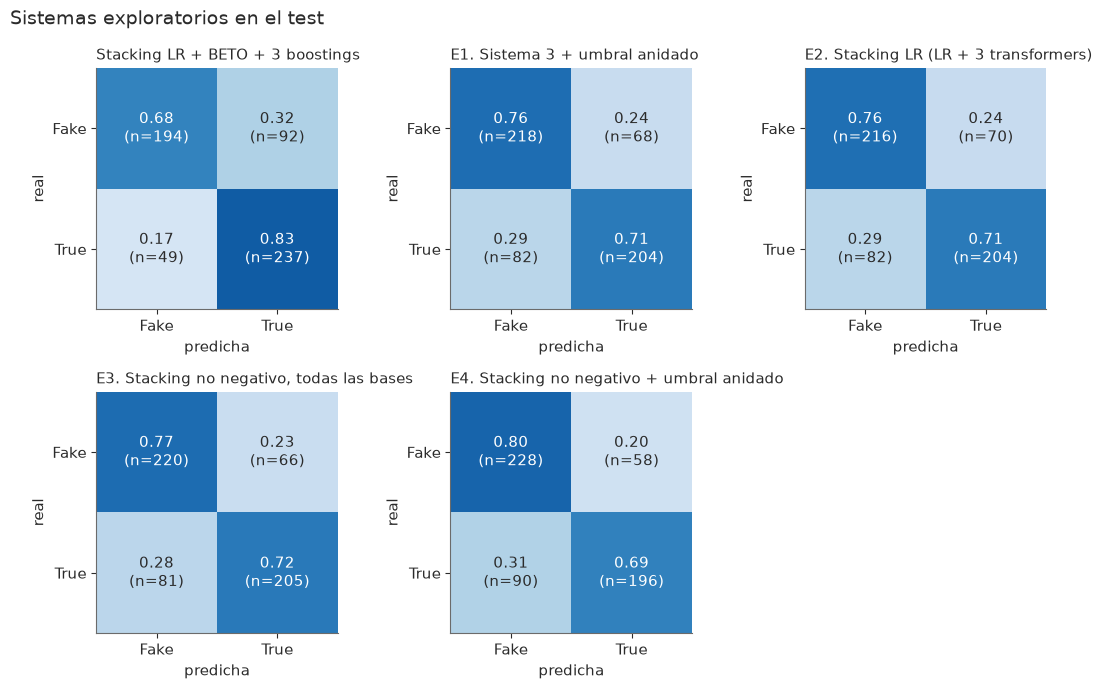

In [78]:
seleccion_figura = {}
for nombre in [NOMBRE_BOOST] + list(NOMBRES_EXTRA.values()):
    seleccion_figura[nombre.replace(' (exploratorio)', '').replace(' (exploratorio, fuera de la regla)', '')] = predicciones[nombre]
cuadricula_matrices(y_test, seleccion_figura, 'Sistemas exploratorios en el test', '13_2_beto_exploratorios_matrices_test', columnas = 3)

**Tabla 13.5.** Falsas detectadas y verdaderas acertadas (%) por cuartil de longitud en el test, para las bases nuevas y los sistemas exploratorios.

In [79]:
seleccion_cuartil = {'LR texto (principal)': predicciones['LR texto (principal)'], '3. Stacking LR (LR + BETO)': predicciones['3. Stacking LR (LR + BETO)']}
for nombre in NUEVOS_TEST:
    seleccion_cuartil[nombre] = predicciones[nombre]
deteccion_por_cuartil(y_test, seleccion_cuartil, cuartil_test)

LR texto (principal)  \
falsas detectadas (%)    Q1 (más cortas)                  78.2   
                         Q2                               54.3   
                         Q3                               38.7   
                         Q4 (más largas)                  24.2   
verdaderas acertadas (%) Q1 (más cortas)                  69.7   
                         Q2                               82.5   
                         Q3                               90.0   
                         Q4 (más largas)                  98.2   

                                          3. Stacking LR (LR + BETO)  \
falsas detectadas (%)    Q1 (más cortas)                        88.2   
                         Q2                                     66.7   
                         Q3                                     48.4   
                         Q4 (más largas)                        54.5   
verdaderas acertadas (%) Q1 (más cortas)                        54.5   
                         Q2                                     65.1   
                         Q3                                     85.0   
                         Q4 (más largas)                        93.6   

                                          SVM-RBF (embeddings) (base exploratoria)  \
falsas detectadas (%)    Q1 (más cortas)                                      78.2   
                         Q2                                                   59.3   
                         Q3                                                   35.5   
                         Q4 (más largas)                                      36.4   
verdaderas acertadas (%) Q1 (más cortas)                                      60.6   
                         Q2                                                   69.8   
                         Q3                                                   91.2   
                         Q4 (más largas)                                      95.5   

                                          kNN (embeddings) (base exploratoria)  \
falsas detectadas (%)    Q1 (más cortas)                                  52.7   
                         Q2                                               50.6   
                         Q3                                                6.5   
                         Q4 (más largas)                                   6.1   
verdaderas acertadas (%) Q1 (más cortas)                                  60.6   
                         Q2                                               65.1   
                         Q3                                               95.0   
                         Q4 (más largas)                                  98.2   

                                          Naive Bayes (palabras) (base exploratoria)  \
falsas detectadas (%)    Q1 (más cortas)                                        57.3   
                         Q2                                                     54.3   
                         Q3                                                     51.6   
                         Q4 (más largas)                                        51.5   
verdaderas acertadas (%) Q1 (más cortas)                                        84.8   
                         Q2                                                     81.0   
                         Q3                                                     76.2   
                         Q4 (más largas)                                        74.5   

                                          BERTIN (base exploratoria)  \
falsas detectadas (%)    Q1 (más cortas)                        85.5   
                         Q2                                     72.8   
                         Q3                                     64.5   
                         Q4 (más largas)                        72.7   
verdaderas acertadas (%) Q1 (más cortas)                        42.4   
                         Q2                                

**Guardado para `finalistas.ipynb`.** Se guardan las entradas de los meta-modelos (probabilidades *out-of-fold* de todas las bases en CV y sus probabilidades en el test), las probabilidades de los tres finalistas (sistema 3, E3 y E4) y sus parámetros, para analizarlos a fondo en `finalistas.ipynb` sin recalcular las bases.

In [80]:
entradas_cv = M[TODAS_BASES + ['est_log_palabras']].copy()
entradas_cv.insert(0, 'fold_grupo', folds)
entradas_cv.insert(0, 'Category', y)
entradas_cv.insert(0, 'conjunto', 'cv')
entradas_cv.insert(0, 'id_unico', corpus['id_unico'].values)
entradas_cv['prob 3'] = prob_cv['3. Stacking LR (LR + BETO)']
entradas_cv['prob E3'] = prob_cv[NOMBRES_EXTRA['E3']]
entradas_cv['pred E4'] = pred_cv[NOMBRES_EXTRA['E4']]
entradas_test = M_test[TODAS_BASES + ['est_log_palabras']].copy()
entradas_test.insert(0, 'fold_grupo', -1)
entradas_test.insert(0, 'Category', y_test)
entradas_test.insert(0, 'conjunto', 'test')
entradas_test.insert(0, 'id_unico', test['id_unico'].values)
entradas_test['prob 3'] = prob_test['3. Stacking LR (LR + BETO)']
entradas_test['prob E3'] = prob_test[NOMBRES_EXTRA['E3']]
entradas_test['pred E4'] = predicciones[NOMBRES_EXTRA['E4']]
guardar_csv(pd.concat([entradas_cv, entradas_test], ignore_index = True), 'finalistas_entradas')
meta_3 = metas_finales['3. Stacking LR (LR + BETO)']['meta']
finalistas = {'bases_E3': TODAS_BASES,
              'sistema_3': {'entradas': ENTRADAS_3, 'C': eleccion_meta['3. Stacking LR (LR + BETO)']['C'],
                            'pesos': [float(w) for w in meta_3.coef_[0]], 'intercepto': float(meta_3.intercept_[0])},
              'E3': {'C': float(c_e3), 'pesos': [float(w) for w in meta_e3['pesos']], 'intercepto': float(meta_e3['intercepto'])},
              'E4': {'umbral_test': float(umbral_test_e4), 'umbrales_por_fold': [float(u) for u in umbrales_e4]},
              'E1': {'umbral_test': float(umbral_test_e1), 'umbrales_por_fold': [float(u) for u in umbrales_e1]},
              'config_xgb': config_xgb, 'boosting_por_vista': mejores_boost,
              'columnas_boosting': columnas_boost, 'eleccion_embeddings_y_nb': {n: float(v) for n, v in eleccion_emb.items()}}
with open(os.path.join(uf.RUTA_RESULTADOS, 'finalistas_meta.json'), 'w', encoding = 'utf-8') as f:
    json.dump(finalistas, f, ensure_ascii = False, indent = 1)
print(f'finalistas_entradas.csv: {len(entradas_cv)} filas de CV y {len(entradas_test)} del test; finalistas_meta.json guardado')

finalistas_entradas.csv: 961 filas de CV y 572 del test; finalistas_meta.json guardado


**Qué se observa.**

* **El umbral anidado no ayuda al sistema 3** (Figura 13.1). La curva tiene su máximo en 0.37 (su valor está en la leyenda de la figura), pero es optimista, porque el umbral se elige y se mide en los mismos datos. Con CV anidada, los umbrales van de 0.33 a 0.46 según los folds y la F1 apenas pasa de 0.7463 a 0.7472 (E1), ganando en 2 de 5 folds.
* **En CV, todo lo que lleva a BERTIN sube** (Tabla 13.1):
  * E2 (LR + 3 transformers) saca 0.7984;
  * E3 (pesos no negativos, todas las bases) saca 0.8116 y le gana al sistema 3 en los 5 folds;
  * E4 (E3 + umbral anidado) saca 0.8130.

  Es prácticamente lo mismo que BERTIN solo (0.8099).
* **Los pesos no negativos evitan, por construcción, los signos cambiantes de la Sección 4** (Tabla 13.2) y funcionan como selector de bases. El meta-modelo se queda con 6 bases (LR, XGBoost, BETO, HistGradientBoosting de caracteres, SVM y BERTIN) y deja en 0 al bosque, al kNN, a XLM-RoBERTa y, en la práctica, a Naive Bayes (0.003). BERTIN tiene el peso mayor (2.711).
* **En el test, casi toda esa ventaja desaparece** (Tablas 13.3 y 13.4):
  * E1 saca 0.7440, E2 0.7397, E3 0.7496 y E4 0.7550; el sistema 3 saca 0.7357. Todos le ganan al principal, con IC pareados que excluyen el 0 (de +0.063 a +0.079).
  * **Ninguno se distingue del sistema 3** (E4: +0.019, IC [−0.019, +0.056]) **ni del umbral 0.34** (E4: +0.020, IC [−0.014, +0.053]), y ninguna McNemar es significativa.
  * La ventaja de E3 sobre el sistema 3 pasa de +0.0653 en CV a +0.014 en el test.
* **El stacking con boostings** (fuera de la regla) saca 0.7335 y empata con el sistema 3 (−0.002, IC [−0.019, +0.013]), como anticipaba la CV.
* **Las bases nuevas en el test:**
  * BERTIN saca 0.7258; queda arriba del principal, pero muy lejos de su 0.810 de CV;
  * XLM-RoBERTa saca 0.6708, el SVM 0.6747, Naive Bayes 0.6166 y el kNN 0.4861.
* **Falsas largas en el test** (Tabla 13.5): BERTIN detecta el 72.7 % del cuartil más largo y E3 y E4 el 66.7 %, contra 24.2 % del principal. El costo son las verdaderas cortas: 42.4 % acertadas contra 69.7 % del principal.

**Con BERTIN, la CV prometía +0.065 sobre el sistema 3 y el test solo da +0.01 a +0.02, sin significancia. Es lo que se espera si la ventaja de BERTIN en CV viene en parte de conocer los sitios del corpus (12.4). Los meta-modelos más sofisticados (pesos no negativos, umbral anidado) no cambian la conclusión: en el test, todos los stackings buenos empatan entre sí y con el umbral 0.34.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-14"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 14: Tabla maestra, respuestas y limitaciones</span></div>

> **Qué se hace:** reunimos todos los sistemas en una tabla, repasamos las verificaciones y respondemos las dos preguntas de la tarea.
>
> **Qué se espera ver:** una respuesta directa: ¿BETO hace que el ensamble mitigue errores? ¿La red neuronal le gana a la LR como meta-modelo?

**Tabla 14.1.** Tabla maestra: todas las métricas en CV (media de los 5 folds; esquema B para los meta-modelos) y en el test. Las referencias solo tienen su F1 de CV original.

In [81]:
bloques = {'LR texto (principal)': 'base', 'XGBoost': 'base', 'RF estilo': 'base', '1. BETO solo': 'base / sistema 1',
           'Stacking viejo (LR + XGBoost + RF)': 'referencia recalculada', 'LR texto, umbral 0.34 (referencia)': 'referencia',
           'Stacking viejo reportado (referencia)': 'referencia', NOMBRE_FT: 'exploratorio', NOMBRE_BOOST: 'exploratorio'}
metricas_test = tabla_test(list(predicciones.keys()))
nombres_tabla = list(predicciones.keys())
if NOMBRE_BOOST not in nombres_tabla:
    nombres_tabla.append(NOMBRE_BOOST)
filas = []
for nombre in nombres_tabla:
    fila = {'sistema': nombre, 'bloque': bloques.get(nombre, 'sistema fijo')}
    if nombre in pred_cv:
        por_fold = []
        for k in range(5):
            en_k = folds == k
            por_fold.append(uf.metricas(y[en_k], pred_cv[nombre][en_k]))
        for metrica in por_fold[0]:
            valores = []
            for m in por_fold:
                valores.append(m[metrica])
            fila[f'CV {metrica}'] = np.mean(valores)
            if metrica == 'F1_fake':
                fila['CV sd F1_fake'] = np.std(valores, ddof = 1)
    else:
        fila['CV F1_fake'] = cv_de[nombre]
    for metrica in ['F1_fake', 'F1_true', 'F1_macro', 'accuracy', 'precision_fake', 'recall_fake', 'IC95 F1_fake']:
        if nombre in predicciones:
            fila[f'test {metrica}'] = metricas_test.loc[nombre, metrica]
        else:
            fila[f'test {metrica}'] = 'no evaluado: no superó al sistema 3 en CV'
    fila['¿se eligió antes del test?'] = 'sí'
    fila['exploratorio'] = 'sí' if 'exploratori' in nombre else 'no'
    if 'exploratori' in nombre:
        fila['bloque'] = 'exploratorio'
    filas.append(fila)
tabla_maestra = pd.DataFrame(filas).set_index('sistema')
guardar_csv(tabla_maestra, 'beto_resumen_sistemas', index = True)
print(f'Notebook completo en {(time.time() - inicio_notebook) / 60:.0f} min')
tabla_maestra.round(3)

Notebook completo en 75 min


,bloque,CV F1_fake,CV sd F1_fake,CV F1_true,CV F1_macro,CV accuracy,CV precision_fake,CV recall_fake,test F1_fake,test F1_true,test F1_macro,test accuracy,test precision_fake,test recall_fake,test IC95 F1_fake,¿se eligió antes del test?,exploratorio
sistema,,,,,,,,,,,,,,,,,
LR texto (principal),base,0.730,0.095,0.774,0.752,0.755,0.776,0.695,0.676,0.767,0.722,0.729,0.839,0.566,"[0.629, 0.722]",sí,no
XGBoost,base,0.685,0.066,0.720,0.703,0.706,0.713,0.666,0.637,0.722,0.680,0.685,0.752,0.552,"[0.586, 0.686]",sí,no
RF estilo,base,0.608,0.168,0.686,0.647,0.656,0.654,0.583,0.505,0.664,0.585,0.600,0.661,0.409,"[0.446, 0.560]",sí,no
1. BETO solo,base / sistema 1,0.656,0.196,0.786,0.721,0.742,0.862,0.557,0.693,0.757,0.725,0.729,0.799,0.612,"[0.643, 0.736]",sí,no
2. Soft voting LR + BETO,sistema fijo,0.682,0.137,0.792,0.737,0.752,0.873,0.576,0.708,0.773,0.741,0.745,0.827,0.619,"[0.660, 0.752]",sí,no
3. Stacking LR (LR + BETO),sistema fijo,0.746,0.055,0.788,0.767,0.771,0.805,0.705,0.736,0.763,0.749,0.750,0.780,0.696,"[0.690, 0.778]",sí,no
4. Stacking LR (4 bases),sistema fijo,0.730,0.070,0.781,0.755,0.761,0.799,0.685,0.738,0.770,0.754,0.755,0.794,0.689,"[0.693, 0.778]",sí,no
5. Stacking MLP (4 bases),sistema fijo,0.734,0.080,0.782,0.758,0.764,0.792,0.698,0.745,0.761,0.753,0.754,0.772,0.720,"[0.700, 0.783]",sí,no
6. Stacking LR (4 bases + longitud),sistema fijo,0.708,0.128,0.765,0.737,0.744,0.766,0.680,0.757,0.787,0.772,0.773,0.814,0.706,"[0.712, 0.796]",sí,no


**Tabla 14.2.** Todas las verificaciones del notebook. Las dos restantes de la tarea (cifras del texto contra las salidas y ejecución completa con `nbconvert --execute`) se revisan fuera del notebook; ver `notas/ensamble_beto.md`.

In [82]:
pd.DataFrame(verificaciones)

,verificación,esperado,obtenido,estado
0,folds.csv regenerado idéntico al del zip (md5),32bea9ad9bc0198acaf9b9b0b476d0f7,32bea9ad9bc0198acaf9b9b0b476d0f7,✅
1,fold_grupo de folds.csv igual al de corpus.par...,961 iguales,961 iguales,✅
2,"LR texto out-of-fold, F1 por fold","[0.7848, 0.8541, 0.6345, 0.6375, 0.7381]","[0.7848, 0.8541, 0.6345, 0.6375, 0.7381]",✅
3,"XGBoost out-of-fold, media",0.6773 (Windows),0.6855 (Linux),"⚠️ diferencia Windows/Linux, aceptada (26-nov)"
4,"RF estilo out-of-fold, media",0.6083,0.6083,✅
5,beto_oof.csv: filas e ids de corpus.parquet,"961, mismos ids y folds","961, 961 ids, 961 folds iguales",✅
6,beto_test.csv: filas e ids de test.parquet,"572, mismos ids","572, 572 ids",✅
7,Sin NaN en beto_oof.csv ni beto_test.csv,0,0,✅
8,beto_entrenar.py solo lee id_unico y texto_sin...,una lectura con columns = [...] y sin Category,lectura restringida: True; menciones de Catego...,✅
9,beto_log.csv: 18 entrenamientos (15 out-of-fol...,18,18,✅


**Tabla 14.3.** Auditoría de fuga de datos. Las cuatro primeras revisiones se calculan aquí con los datos; las demás son una revisión del código de este notebook y de `beto_entrenar.py` (cada `fit`, cada lectura del test y cada paso que elige algo).

In [83]:
fuentes_folds = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'folds.csv'))
fuentes_folds = fuentes_folds[fuentes_folds['particion'] != 'test']
n_fuentes_repartidas = int((fuentes_folds.groupby('fuente')['fold_grupo'].nunique() > 1).sum())
texto_normal = corpus['texto_sin_medio'].str.lower().str.split().str.join(' ')
n_textos_repartidos = int((pd.DataFrame({'t': texto_normal, 'f': folds}).groupby('t')['f'].nunique() > 1).sum())
texto_test = set(test['texto_sin_medio'].str.lower().str.split().str.join(' '))
n_textos_en_test = int(texto_normal.isin(texto_test).sum())
n_ids_test = int(corpus['id_unico'].isin(test['id_unico']).sum())
auditoria = [
    ('Fuentes que aparecen en más de un fold', '0', str(n_fuentes_repartidas), marca(n_fuentes_repartidas == 0)),
    ('Textos idénticos repartidos en folds distintos', '0', str(n_textos_repartidos), marca(n_textos_repartidos == 0)),
    ('Textos del corpus idénticos a uno del test', '0', str(n_textos_en_test), marca(n_textos_en_test == 0)),
    ('Noticias del test dentro del corpus', '0', str(n_ids_test), marca(n_ids_test == 0)),
    ('Etiquetas del test: primera lectura', 'Sección 7', 'Sección 7 (antes solo se leen ids)', '✅'),
    ('Algún fit con filas del test', 'ninguno', 'ninguno (revisión del código)', '✅'),
    ('Alguna elección (C, grid, base ganadora, umbral, MLP, FT) con el test', 'ninguna', 'ninguna: todas usan y, folds y predicciones out-of-fold del corpus', '✅'),
    ('Transformers: lectura del test en el entrenamiento', 'solo id_unico y texto_sin_medio', 'solo id_unico y texto_sin_medio', '✅'),
    ('Escaladores, TF-IDF y calibración del SVM', 'ajustados solo con filas de entrenamiento', 'dentro de Pipeline o con filas de entrenamiento', '✅'),
    ('Embeddings de BETO sin ajustar', 'sin etiquetas', 'promedio por noticia de BETO preentrenado; no ve etiquetas', '✅'),
    ('Léxico de medios borrado del texto', 'sin etiquetas ni test', 'sale de la versión 1.0 (train + development); no usa etiquetas', '✅'),
    ('Esquema B de los meta-modelos', 'sin fuga', 'fuga residual conocida: las bases que generan el out-of-fold de los otros folds vieron el fold externo', '⚠️'),
    ('Hiperparámetros de las bases (XGBoost, SVM, kNN, Naive Bayes, boosting por vista)', 'anidados', 'elegidos con los 5 folds, sin anidar (CV algo optimista)', '⚠️'),
    ('Secciones 10 a 13 diseñadas después de ver el test de la Sección 7', 'no', 'sí: por eso son exploratorias y no candidatas a sistema final', '⚠️'),
]
pd.DataFrame(auditoria, columns = ['revisión', 'esperado', 'obtenido', 'estado'])

,revisión,esperado,obtenido,estado
0,Fuentes que aparecen en más de un fold,0,0,✅
1,Textos idénticos repartidos en folds distintos,0,0,✅
2,Textos del corpus idénticos a uno del test,0,0,✅
3,Noticias del test dentro del corpus,0,0,✅
4,Etiquetas del test: primera lectura,Sección 7,Sección 7 (antes solo se leen ids),✅
5,Algún fit con filas del test,ninguno,ninguno (revisión del código),✅
6,"Alguna elección (C, grid, base ganadora, umbra...",ninguna,"ninguna: todas usan y, folds y predicciones ou...",✅
7,Transformers: lectura del test en el entrenami...,solo id_unico y texto_sin_medio,solo id_unico y texto_sin_medio,✅
8,"Escaladores, TF-IDF y calibración del SVM",ajustados solo con filas de entrenamiento,dentro de Pipeline o con filas de entrenamiento,✅
9,Embeddings de BETO sin ajustar,sin etiquetas,promedio por noticia de BETO preentrenado; no ...,✅


**Respuesta 1: ¿BETO hace que el ensamble mitigue errores?** **Sí, en parte, y por la razón correcta.**

* BETO se equivoca en noticias distintas que la LR (Spearman 0.674, contra 0.801 de XGBoost), el oráculo sube de 0.872 a 0.921 y el meta-modelo le da un peso positivo y estable.
* En CV, el stacking LR + BETO (sistema 3) es el mejor de los sistemas fijados (0.7463 contra 0.7298) y gana en 4 de 5 folds, pero la diferencia no es concluyente y es menor que el sesgo del esquema B.
* En el test, los cinco stackings con BETO superan al principal con IC pareado que excluye el 0 (+0.059 a +0.080), y el diagnóstico de la Sección 8 muestra que no es solo un cambio de umbral.
* Lo que **no** se logra es superar al umbral 0.34: empatan con él. Y BETO falla de forma sistemática en la sátira (*El Ruinaversal*), algo que solo se ve gracias a la CV agrupada por fuente.

**Respuesta 2: ¿la red neuronal le gana a la LR como meta-modelo?** **No.**

* En CV, el mejor meta-modelo de los sistemas fijados es una LR (sistema 3). Con las mismas entradas, la MLP del sistema 5 (0.7343) y la LR del sistema 4 (0.7299) empatan.
* La MLP termina eligiendo 4 neuronas con la máxima regularización, es decir, casi una LR.
* Con la longitud, la red aprende a desconfiar de BETO en noticias largas, y en el test eso le cuesta (30.3 % de falsas largas detectadas).
* El FT-Transformer tampoco gana.
* En la exploración, el meta-modelo con pesos no negativos (E3) sí es más estable que la LR libre, pero en el test empata con ella.

**Lo que agregaron las exploraciones (Secciones 11 a 13):**

* **Árboles y boostings:** variar la semilla no los diversifica (Spearman 0.976 a 0.978 entre semillas de XGBoost). Variar la vista sí, pero siguen por debajo de la LR, y su stacking con LR + BETO empata con el sistema 3 en CV y en el test.
* **BERTIN es la mejor base del proyecto en CV (0.8099)**, y la que más falsas largas detecta. Pero en el test baja a 0.7258. La prueba de contaminación no encontró memorización de las noticias del corpus, pero sí que BERTIN conocía los sitios y su estilo. Su CV es optimista.
* **El mejor sistema exploratorio en el test es E4** (pesos no negativos sobre todas las bases + umbral anidado): 0.7550, IC [0.715, 0.794]. Supera al principal (+0.079) y queda arriba de los *baselines* oficiales en estimación puntual, pero no se distingue del sistema 3 ni del umbral 0.34. Como se diseñó después de ver el test, **no puede declararse sistema final**.

**Sistema que se elegiría con la CV de los sistemas fijados: el sistema 3** (stacking LR + BETO con meta-modelo LR): 0.7463 en CV y 0.7357 en el test (IC [0.690, 0.778]). Supera al principal (+0.059), empata con el umbral 0.34 y con todas las variantes exploratorias, y queda en el rango de los *baselines* oficiales (.7217 y .7321).

**Limitaciones:**

* **Esquema B en lugar de CV anidada completa.** Su fuga residual infla la CV: en el stacking viejo fue +0.0470 contra la anidada, mezclado con la diferencia de XGBoost entre sistemas operativos.
* **Transformers sin *grid search*** y con solo 3 semillas. BETO es muy inestable en el fold de la sátira (hasta 0.4596 entre semillas). XLM-RoBERTa se entrenó con su tabla de *embeddings* congelada para caber en 4 GB.
* **Contaminación de estilo en BERTIN:** su preentrenamiento incluyó páginas de los sitios del corpus. Su CV no es comparable con la de BETO y la LR.
* **XGBoost de Linux** (0.6855) en lugar del de Windows (0.6773).
* **El orden entre sistemas cambia entre CV y test** (el sistema 6 es el peor stacking en CV y el mejor de los fijados en el test). Con 572 noticias de test no se separan stackings que difieran ±0.02.
* **El test se cargó más de una vez:** la primera corrida se detuvo para apagar la laptop, y el notebook se volvió a correr completo al agregar las Secciones 11 a 13. El código de las Secciones 1 a 10 no cambió y ninguna decisión se tomó viendo el test.
* **Las Secciones 10 a 13 se propusieron después de ver el test de la Sección 7**, y algunas cifras del test salieron en pantalla al depurarlas con copias de prueba. Por eso son exploratorias y llevan sus propias reglas: el stacking con boostings no pasó la suya y se evaluó fuera de ella, solo como dato descriptivo.
* **No sabemos si el test tiene sátira:** revisarlo sería mirar el test con fines de decisión.
* Los hiperparámetros de las bases siguen sin anidar, igual que en los notebooks anteriores.

<a id="seccion-15"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 15: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Alegre Ventura, R. J. (2026). *Métodos de ensamble: bagging, boosting y stacking*. Materiales de Minería de Datos, LCD, IIMAS, UNAM (láminas 4, 20–24).
2. Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H. y Pérez, J. (2020). Spanish Pre-Trained BERT Model and Evaluation Data. En *PML4DC at ICLR 2020* (BETO).
3. Sun, C., Qiu, X., Xu, Y. y Huang, X. (2019). How to Fine-Tune BERT for Text Classification? En *CCL 2019* (truncado cabeza + cola).
4. Huang, X., Xiong, J. y Jiang, S. (2021). GDUF_DM at FakeDeS 2021: Spanish Fake News Detection with BERT and Sample Memory. *CEUR-WS* Vol. 2943, 621–629.
5. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231.
6. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
7. Sill, J., Takács, G., Mackey, L. y Lin, D. (2009). Feature-Weighted Linear Stacking. arXiv:0911.0460.
8. Gorishniy, Y., Rubachev, I., Khrulkov, V. y Babenko, A. (2021). Revisiting Deep Learning Models for Tabular Data. En *NeurIPS 2021* (FT-Transformer).
9. Chen, T. y Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. En *KDD 2016*.
10. Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32.
11. Freund, Y. y Schapire, R. E. (1997). A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting. *Journal of Computer and System Sciences*, 55(1), 119–139 (AdaBoost).
12. Cortes, C. y Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20, 273–297.
13. Cover, T. y Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21–27.
14. Rennie, J. D. M., Shih, L., Teevan, J. y Karger, D. R. (2003). Tackling the Poor Assumptions of Naive Bayes Text Classifiers. En *ICML 2003* (Complement Naive Bayes).
15. De la Rosa, J., Ponferrada, E. G., Villegas, P., González de Prado Salas, P., Romero, M. y Grandury, M. (2022). BERTIN: Efficient Pre-Training of a Spanish Language Model using Perplexity Sampling. *Procesamiento del Lenguaje Natural*, 68, 13–23.
16. Conneau, A., Khandelwal, K., Goyal, N., Chaudhary, V., Wenzek, G., Guzmán, F., Grave, E., Ott, M., Zettlemoyer, L. y Stoyanov, V. (2020). Unsupervised Cross-lingual Representation Learning at Scale. En *ACL 2020* (XLM-RoBERTa).